# Proyecto Integrador de Aprendizaje Automático
## Predicción de default en préstamos de Lending Club: scikit-learn vs. PySpark

**Autor:** Daniel Serrano Romero
**Programa:** Maestría en Matemáticas
**Asignatura:** Machine Learning

* Informe publicado (Jupyter Book): [https://danielserrero2124-oss.github.io/jbook_ml_dsr/](https://danielserrero2124-oss.github.io/jbook_ml_dsr/)
* Código fuente: [https://github.com/danielserrero2124-oss/jbook_ml_dsr](https://github.com/danielserrero2124-oss/jbook_ml_dsr)

> Este archivo reúne, en orden, los siete notebooks del proyecto **ya ejecutados** sobre el
> dataset completo, con todas sus salidas. Cada notebook se ejecutó en su propia sesión (algunos
> tardan más de una hora); para volver a ejecutarlos se recomienda usar los notebooks
> individuales del repositorio (carpeta `notebooks/`), en orden del 01 al 07.

**Predicción de default en préstamos de Lending Club: scikit-learn vs. PySpark**

Este libro documenta la construcción y comparación de seis modelos de clasificación
supervisada (regresión logística, árbol de decisión, bosque aleatorio, *gradient boosting*,
SVM lineal y Naive Bayes) para predecir si un préstamo de Lending Club termina en *default*
(`Charged Off` = 1) o se paga completamente (`Fully Paid` = 0). Cada modelo se implementa
dos veces, con **scikit-learn** y con **PySpark**, sobre el **dataset completo sin muestreo**
y con **la misma partición 80/20** para que las comparaciones sean pareadas.

## Contenido

| Capítulo | Contenido |
|---|---|
| 1. EDA | Carga completa, análisis uni y bidimensional, multicolinealidad, valores faltantes, resumen ejecutivo |
| 2. Partición y preprocesamiento (scikit-learn) | Partición común estratificada guardada en Parquet; transformadores ajustados solo con train |
| 3. Modelado con scikit-learn | `GridSearchCV` (cv = 3, AUC), métricas, matrices de confusión, tiempos |
| 4. Preprocesamiento y modelado con PySpark | Lectura del CSV en Spark, pipeline, caché, `CrossValidator` (3 pliegues), métricas, tiempos |
| 5. Comparación estadística | DeLong rápido (validado), Holm, McNemar, bootstrap pareado |
| 6. LIME | Explicaciones locales de instancias mal clasificadas en ambos entornos |
| 7. Comparación final | Tablas y gráficos comparativos, escalabilidad y reflexión crítica |

## Resultados principales

| Modelo | AUC scikit-learn | AUC PySpark | Entrenamiento + CV sklearn (s) | Entrenamiento + CV PySpark (s) |
|---|---|---|---|---|
| Gradient boosting | **0,7207** | **0,7208** | 71 | 581 |
| Bosque aleatorio | 0,7153 | 0,7142 | 519 | 2.741 |
| Regresión logística | 0,7141 | 0,7141 | 63 | 27 |
| Árbol de decisión | 0,7043 | 0,7018 | 37 | 26 |
| Naive Bayes | 0,6792 | 0,6795 | 4 | 6 |
| LinearSVC | 0,5293 | 0,6793 | 3.549 | 97 |

* Ambos entornos alcanzan la **misma capacidad predictiva**: el mejor modelo (*gradient
  boosting*) no difiere entre entornos (DeLong, p Holm = 0,82). Solo LinearSVC difiere de forma
  relevante, por diferencias de implementación.
* **Velocidad:** PySpark es más rápido en los modelos lineales y el árbol, y scikit-learn en los
  ensambles. En la regresión logística PySpark supera a scikit-learn a partir de unas 250 mil
  filas; en el bosque, nunca en este equipo.
* Configuración de Spark ajustada y justificada (`local[6]`, 6 particiones, 9g): las 400
  particiones del enunciado resultaron ≈ 9 veces más lentas en una sola máquina, y con 12 hilos
  el bosque de 100 árboles de profundidad 15 agotaba la memoria.

## Reproducibilidad

* Semilla global: 42. Partición 80/20 estratificada (`data/particion_train_test.parquet`).
* Código reutilizable en `src/` y código fuente de cada notebook en `fuentes/`;
  **cada línea de código está comentada**.
* Hardware: AMD Ryzen (6 núcleos físicos / 12 lógicos), 14 GB de RAM, Windows 11,
  Python 3.9, scikit-learn 1.3, PySpark 3.5.3 (modo local), Java 21.

## Referencias

* DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988). *Biometrics*, 44(3), 837–845.
* Dietterich, T. G. (1998). *Neural Computation*, 10(7), 1895–1923.
* Efron, B. y Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
* McNemar, Q. (1947). *Psychometrika*, 12(2), 153–157.
* Sun, X. y Xu, W. (2014). *IEEE Signal Processing Letters*, 21(11), 1389–1393.
* Ribeiro, M. T., Singh, S. y Guestrin, C. (2016). "Why should I trust you?" *KDD*.

---

# 1. Análisis exploratorio de datos (EDA)

**Objetivo del proyecto:** predecir si un préstamo de Lending Club termina en *default*
(`Charged Off` = 1) o se paga completamente (`Fully Paid` = 0), comparando seis modelos
implementados en scikit-learn y en PySpark.

Este notebook cubre las secciones 2.1 a 2.5 del enunciado: carga completa del dataset
(sin muestreo), análisis unidimensional, bidimensional, multicolinealidad, valores
faltantes y un resumen ejecutivo con las decisiones que guían el preprocesamiento.

> **Nota sobre la definición del target.** La fórmula del enunciado
> `df["default"] = df["loan_status"].apply(lambda x: 1 if x == "Charged Off" else 0)`
> aplicada al archivo completo etiquetaría como "pagados" (0) a los préstamos `Current`,
> `Late`, `In Grace Period`, etc., que **todavía no tienen un desenlace observado**. Eso sería
> un error de etiquetado. Por ello primero se conservan solo los préstamos con estado final
> (`Fully Paid` / `Charged Off`) y después se aplica la fórmula literal. Esto no es un muestreo:
> se usan **todas** las filas con desenlace conocido (1.345.310, coherente con los "más de
> 1,3 millones de registros" del enunciado).

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto para poder importar src/
import time  # Medición de tiempos
import warnings  # Control de advertencias
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos tabulares
import matplotlib.pyplot as plt  # Gráficos
import seaborn as sns  # Gráficos estadísticos
import missingno as msno  # Visualización de valores faltantes
from scipy import stats  # Pruebas estadísticas
from src import config as cfg  # Configuración central del proyecto
from src import preparacion as prep  # Construcción de variables con pandas
from src.utilidades import guardar_figura, info_hardware  # Utilidades auxiliares

warnings.filterwarnings("ignore", category=FutureWarning)  # Oculta avisos de versiones futuras de librerías
pd.set_option("display.max_columns", 60)  # Muestra hasta 60 columnas en las tablas
pd.set_option("display.width", 200)  # Ancho máximo de impresión de tablas
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")  # Formato de los números flotantes
sns.set_theme(style="whitegrid", palette="deep")  # Estilo general de los gráficos
print(info_hardware())  # Muestra el hardware utilizado

{'sistema': 'Windows 10', 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD', 'nucleos_fisicos': 6, 'nucleos_logicos': 12, 'ram_total_gb': 13.8, 'ram_disponible_gb': 6.0, 'python': '3.9.25'}


## 2.2 Carga inicial y visión general

Se carga el CSV comprimido **completo** con pandas y, a modo de comparación, con Spark.

In [2]:
inicio = time.time()  # Marca de tiempo antes de la carga
df_raw = pd.read_csv(cfg.RUTA_CSV, low_memory=False)  # Lee el archivo completo (pandas descomprime el .gz)
t_pandas = time.time() - inicio  # Tiempo total de carga con pandas
print(f"Tiempo de carga con pandas: {t_pandas:.1f} s")  # Reporta el tiempo
print(f"Dimensión: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")  # Reporta filas y columnas
print(f"Memoria en uso: {df_raw.memory_usage(deep=True).sum() / 1024**3:.2f} GB")  # Memoria ocupada por el DataFrame

Tiempo de carga con pandas: 48.9 s
Dimensión: 2,260,701 filas × 151 columnas


Memoria en uso: 6.26 GB


In [3]:
from src import preparacion_spark as prep_sp  # Funciones de Spark del proyecto
spark = prep_sp.crear_sesion()  # Crea la SparkSession con la configuración del enunciado
inicio = time.time()  # Marca de tiempo antes de la carga
n_spark = prep_sp.leer_csv(spark).count()  # Lee el CSV completo con Spark y fuerza la lectura contando filas
t_spark = time.time() - inicio  # Tiempo total de carga con Spark
print(f"Tiempo de carga con Spark: {t_spark:.1f} s  ({n_spark:,} filas)")  # Reporta tiempo y filas
spark.stop()  # Detiene la sesión para liberar memoria

Tiempo de carga con Spark: 15.9 s  (2,260,701 filas)


**Comentario.** El archivo tiene **2.260.701 filas × 151 columnas** y ocupa ≈ 6,3 GB en
memoria con pandas, que tardó ≈ 72 s en leerlo. Spark contó las mismas filas en ≈ 17 s: un
`.gz` no es divisible (se descomprime en un solo hilo), pero Spark no construye objetos de
Python ni infiere tipos, y para un `count()` apenas necesita tokenizar cada registro. La
comparación favorece a Spark sobre todo porque su lectura es perezosa: pandas materializa
todas las columnas tipadas. `head()`/`tail()` confirman una lectura correcta; las dos últimas
filas son **totales del archivo** (sin `loan_status`) y quedan fuera al filtrar estados.

In [4]:
df_raw.head()  # Primeras 5 filas para verificar la lectura

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,...,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,"3,600.0000","3,600.0000","3,600.0000",36 months,13.9900,123.0300,C,C4,leadman,10+ years,MORTGAGE,"55,000.0000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,190xx,PA,5.9100,0.0000,Aug-2003,675.0000,679.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,"24,700.0000","24,700.0000","24,700.0000",36 months,11.9900,820.2800,C,C1,Engineer,10+ years,MORTGAGE,"65,000.0000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.0600,1.0000,Dec-1999,715.0000,719.0000,4.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,"20,000.0000","20,000.0000","20,000.0000",60 months,10.7800,432.6600,B,B4,truck driver,10+ years,MORTGAGE,"63,000.0000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,home_improvement,NaN,605xx,IL,10.7800,0.0000,Aug-2000,695.0000,699.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,"35,000.0000","35,000.0000","35,000.0000",60 months,14.8500,829.9000,C,C5,Information Systems Officer,10+ years,MORTGAGE,"110,000.0000",Source Verified,Dec-2015,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,076xx,NJ,17.0600,0.0000,Sep-2008,785.0000,789.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,"10,400.0000","10,400.0000","10,400.0000",60 months,22.4500,289.9100,F,F1,Contract Specialist,3 years,MORTGAGE,"104,433.0000",Source Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,major_purchase,Major purchase,174xx,PA,25.3700,1.0000,Jun-1998,695.0000,699.0000,3.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df_raw.tail()  # Últimas 5 filas: las dos últimas son filas de totales, no préstamos

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,...,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
2260696,88985880,NaN,"40,000.0000","40,000.0000","40,000.0000",60 months,10.4900,859.5600,B,B3,Vice President,9 years,MORTGAGE,"227,000.0000",Verified,Oct-2016,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,NaN,907xx,CA,12.7500,7.0000,Feb-1995,705.0000,709.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260697,88224441,NaN,"24,000.0000","24,000.0000","24,000.0000",60 months,14.4900,564.5600,C,C4,Program Manager,6 years,RENT,"110,000.0000",Not Verified,Oct-2016,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,334xx,FL,18.3000,0.0000,Jul-1999,660.0000,664.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,Y,Mar-2019,ACTIVE,Mar-2019,"10,000.0000",44.8200,1.0000
2260698,88215728,NaN,"14,000.0000","14,000.0000","14,000.0000",60 months,14.4900,329.3300,C,C4,Customer Service Technician,10+ years,MORTGAGE,"95,000.0000",Verified,Oct-2016,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,NaN,770xx,TX,23.3600,0.0000,Jun-1996,660.0000,664.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260699,Total amount funded in policy code 1: 1465324575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2260700,Total amount funded in policy code 2: 521953170,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df_raw.info(verbose=True, show_counts=True)  # Tipos de datos y conteo de no nulos de cada columna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Data columns (total 151 columns):
 #    Column                                      Non-Null Count    Dtype  
---   ------                                      --------------    -----  
 0    id                                          2260701 non-null  object 
 1    member_id                                   0 non-null        float64
 2    loan_amnt                                   2260668 non-null  float64
 3    funded_amnt                                 2260668 non-null  float64
 4    funded_amnt_inv                             2260668 non-null  float64
 5    term                                        2260668 non-null  object 
 6    int_rate                                    2260668 non-null  float64
 7    installment                                 2260668 non-null  float64
 8    grade                                       2260668 non-null  object 
 9    sub_grade                                   

In [7]:
df_raw.describe().T  # Estadísticas descriptivas de todas las variables numéricas

,count,mean,std,min,25%,50%,75%,max
member_id,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,"2,260,668.0000","15,046.9312","9,190.2455",500.0000,"8,000.0000","12,900.0000","20,000.0000","40,000.0000"
funded_amnt,"2,260,668.0000","15,041.6641","9,188.4130",500.0000,"8,000.0000","12,875.0000","20,000.0000","40,000.0000"
funded_amnt_inv,"2,260,668.0000","15,023.4377","9,192.3317",0.0000,"8,000.0000","12,800.0000","20,000.0000","40,000.0000"
int_rate,"2,260,668.0000",13.0928,4.8321,5.3100,9.4900,12.6200,15.9900,30.9900
...,...,...,...,...,...,...,...,...
hardship_payoff_balance_amount,"10,917.0000","11,636.8839","7,625.9883",55.7300,"5,627.0000","10,028.3900","16,151.8900","40,306.4100"
hardship_last_payment_amount,"10,917.0000",193.9943,198.6295,0.0100,44.4400,133.1600,284.1900,"1,407.8600"
settlement_amount,"34,246.0000","5,010.6643","3,693.1226",44.2100,"2,208.0000","4,146.1100","6,850.1725","33,601.0000"
settlement_percentage,"34,246.0000",47.7804,7.3118,0.2000,45.0000,45.0000,50.0000,521.3500


In [8]:
estados = df_raw[cfg.COL_ESTADO].value_counts(dropna=False).to_frame("n")  # Frecuencia de cada estado del préstamo
estados["%"] = 100 * estados["n"] / estados["n"].sum()  # Porcentaje de cada estado
estados  # Muestra la tabla

,n,%
loan_status,,
Fully Paid,1076751,47.6291
Current,878317,38.8515
Charged Off,268559,11.8795
Late (31-120 days),21467,0.9496
In Grace Period,8436,0.3732
Late (16-30 days),4349,0.1924
Does not meet the credit policy. Status:Fully Paid,1988,0.0879
Does not meet the credit policy. Status:Charged Off,761,0.0337
Default,40,0.0018


Solo `Fully Paid` y `Charged Off` representan desenlaces definitivos. `Current` y los
estados de mora son préstamos vivos; las variantes "Does not meet the credit policy" son
préstamos bajo una política distinta y `Default` (40 casos) aún no ha sido castigado.

### Pre-cálculo de faltantes sobre las 151 columnas

Antes de reducir columnas, se calcula la tasa de nulos de **todas** las variables en los
préstamos con desenlace final y su relación con el target. Los resultados se presentan en
la sección de valores faltantes.

In [9]:
finales = df_raw[cfg.COL_ESTADO].isin(cfg.ESTADOS_FINALES).to_numpy()  # Máscara de préstamos con estado final
nulos_fin = df_raw.isna().to_numpy()[finales]  # Matriz booleana de nulos (filas finales × 151 columnas), sin copiar los datos
y_fin = (df_raw.loc[finales, cfg.COL_ESTADO] == "Charged Off").astype(int).to_numpy()  # Target en ese subconjunto
nulos_todas = pd.DataFrame({"n_nulos": nulos_fin.sum(axis=0)}, index=df_raw.columns)  # Número de nulos por columna
nulos_todas["pct_nulos"] = 100 * nulos_todas["n_nulos"] / finales.sum()  # Porcentaje de nulos por columna
nulos_todas = nulos_todas.sort_values("pct_nulos", ascending=False)  # Ordena de mayor a menor

filas_mcar = []  # Lista con la prueba de independencia nulo-vs-default de cada columna
for col in nulos_todas.index[(nulos_todas["pct_nulos"] > 0) & (nulos_todas["pct_nulos"] < 100)]:  # Columnas con nulos parciales
    es_nulo = nulos_fin[:, df_raw.columns.get_loc(col)]  # Indicador de nulo de la columna
    tabla = pd.crosstab(es_nulo, y_fin)  # Tabla 2×2: nulo/no nulo × default
    chi2, p, _, _ = stats.chi2_contingency(tabla)  # Prueba chi-cuadrado de independencia
    filas_mcar.append({  # Guarda el resultado
        "columna": col,  # Nombre de la columna
        "pct_nulos": nulos_todas.loc[col, "pct_nulos"],  # Porcentaje de nulos
        "tasa_default_si_nulo": y_fin[es_nulo].mean(),  # Tasa de default cuando falta el dato
        "tasa_default_si_presente": y_fin[~es_nulo].mean(),  # Tasa de default cuando el dato está
        "chi2": chi2, "p_valor": p,  # Estadístico y valor p
    })
mcar_todas = pd.DataFrame(filas_mcar).set_index("columna")  # Tabla final de la prueba

anio_fin = pd.to_datetime(df_raw.loc[finales, "issue_d"], format="%b-%Y").dt.year.to_numpy()  # Año de emisión de cada préstamo
cols_con_nulos = nulos_todas.index[(nulos_todas["pct_nulos"] > 0)].tolist()  # Columnas con algún nulo
nulos_por_anio = (pd.DataFrame(nulos_fin, columns=df_raw.columns)[cols_con_nulos]  # Nulos de las columnas con faltantes
                  .groupby(anio_fin).mean())  # Proporción de nulos por año de emisión
nulos_por_fila = nulos_fin.sum(axis=1)  # Número de nulos en cada fila

df = prep.construir_variables(df_raw)  # Filtra estados finales y crea variables derivadas + default
del df_raw, nulos_fin  # Libera el DataFrame de 151 columnas y la matriz de nulos
import gc; gc.collect()  # Fuerza la liberación de memoria
print(df.shape)  # Dimensión del dataset de trabajo
df.head()  # Primeras filas del dataset de trabajo

(1345310, 31)


,id,issue_d,loan_amnt,term_meses,int_rate,installment,annual_inc,dti,fico_range_low,fico_range_high,emp_length_anios,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,mths_since_last_delinq,antiguedad_credito_meses,grade,sub_grade,home_ownership,verification_status,purpose,addr_state,initial_list_status,application_type,default
0,68407277,2015-12-01,"3,600.0000",36.0000,13.9900,123.0300,"55,000.0000",5.9100,675.0000,679.0000,10.0000,0.0000,1.0000,7.0000,0.0000,"2,765.0000",29.7000,13.0000,1.0000,0.0000,30.0000,148.0000,C,C4,MORTGAGE,Not Verified,debt_consolidation,PA,w,Individual,0
1,68355089,2015-12-01,"24,700.0000",36.0000,11.9900,820.2800,"65,000.0000",16.0600,715.0000,719.0000,10.0000,1.0000,4.0000,22.0000,0.0000,"21,470.0000",19.2000,38.0000,4.0000,0.0000,6.0000,192.0000,C,C1,MORTGAGE,Not Verified,small_business,SD,w,Individual,0
2,68341763,2015-12-01,"20,000.0000",60.0000,10.7800,432.6600,"63,000.0000",10.7800,695.0000,699.0000,10.0000,0.0000,0.0000,6.0000,0.0000,"7,869.0000",56.2000,18.0000,5.0000,0.0000,NaN,184.0000,B,B4,MORTGAGE,Not Verified,home_improvement,IL,w,Joint App,0
3,68476807,2015-12-01,"10,400.0000",60.0000,22.4500,289.9100,"104,433.0000",25.3700,695.0000,699.0000,3.0000,1.0000,3.0000,12.0000,0.0000,"21,929.0000",64.5000,35.0000,6.0000,0.0000,12.0000,210.0000,F,F1,MORTGAGE,Source Verified,major_purchase,PA,w,Individual,0
4,68426831,2015-12-01,"11,950.0000",36.0000,13.4400,405.1800,"34,000.0000",10.2000,690.0000,694.0000,4.0000,0.0000,0.0000,5.0000,0.0000,"8,822.0000",68.4000,6.0000,0.0000,0.0000,NaN,338.0000,C,C3,RENT,Source Verified,debt_consolidation,GA,w,Individual,0


## 2.3 Análisis unidimensional

### Variables numéricas

Para cada variable se reportan media, mediana, desviación estándar, mínimo, máximo,
percentiles, IQR, outliers según la regla de Tukey (fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]),
asimetría, curtosis y la prueba de normalidad de D'Agostino-Pearson (se prefiere a
Shapiro-Wilk porque esta última no es válida con más de 5.000 observaciones y aquí se usa
la muestra completa).

In [10]:
filas = []  # Lista de resúmenes por variable
for col in cfg.NUMERICAS_EDA:  # Recorre cada variable numérica
    x = df[col].dropna()  # Valores no nulos
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])  # Cuartiles
    iqr = q3 - q1  # Rango intercuartil
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr  # Límites de Tukey
    n_out = int(((x < li) | (x > ls)).sum())  # Número de outliers
    filas.append({  # Guarda el resumen de la variable
        "media": x.mean(), "mediana": q2, "desv_est": x.std(),  # Tendencia central y dispersión
        "min": x.min(), "p25": q1, "p50": q2, "p75": q3, "max": x.max(),  # Rango y percentiles
        "IQR": iqr, "lim_inf": li, "lim_sup": ls,  # IQR y límites de outliers
        "n_outliers": n_out, "pct_outliers": 100 * n_out / len(x),  # Cantidad y % de outliers
        "asimetria": stats.skew(x), "curtosis": stats.kurtosis(x),  # Forma de la distribución
        "p_normalidad": stats.normaltest(x).pvalue,  # Prueba de D'Agostino-Pearson
        "pct_nulos": 100 * df[col].isna().mean(),  # Porcentaje de nulos
    })
resumen_num = pd.DataFrame(filas, index=cfg.NUMERICAS_EDA)  # Tabla final
resumen_num  # Muestra la tabla

,media,mediana,desv_est,min,p25,p50,p75,max,IQR,lim_inf,lim_sup,n_outliers,pct_outliers,asimetria,curtosis,p_normalidad,pct_nulos
loan_amnt,"14,419.9720","12,000.0000","8,717.0508",500.0000,"8,000.0000","12,000.0000","20,000.0000","40,000.0000","12,000.0000","-10,000.0000","38,000.0000",7157,0.5320,0.7825,-0.0838,0.0000,0.0000
term_meses,41.7902,36.0000,10.2683,36.0000,36.0000,36.0000,36.0000,60.0000,0.0000,36.0000,36.0000,324567,24.1258,1.2095,-0.5371,0.0000,0.0000
int_rate,13.2396,12.7400,4.7687,5.3100,9.7500,12.7400,15.9900,30.9900,6.2400,0.3900,25.3500,24977,1.8566,0.7135,0.5059,0.0000,0.0000
installment,438.0755,375.4300,261.5126,4.9300,248.4800,375.4300,580.7300,"1,719.8300",332.2500,-249.8950,"1,079.1050",42042,3.1251,1.0065,0.7487,0.0000,0.0000
annual_inc,"76,247.6364","65,000.0000","69,925.0984",0.0000,"45,780.0000","65,000.0000","90,000.0000","10,999,200.0000","44,220.0000","-20,550.0000","156,330.0000",65870,4.8963,46.3179,"4,812.4144",0.0000,0.0000
dti,18.2827,17.6100,11.1604,-1.0000,11.7900,17.6100,24.0600,999.0000,12.2700,-6.6150,42.4650,5473,0.4069,27.1106,"2,112.6827",0.0000,0.0278
fico_range_low,696.1850,690.0000,31.8525,625.0000,670.0000,690.0000,710.0000,845.0000,40.0000,610.0000,770.0000,46497,3.4562,1.2855,1.6618,0.0000,0.0000
fico_range_high,700.1852,694.0000,31.8532,629.0000,674.0000,694.0000,714.0000,850.0000,40.0000,614.0000,774.0000,46497,3.4562,1.2857,1.6631,0.0000,0.0000
emp_length_anios,5.9659,6.0000,3.6912,0.0000,2.0000,6.0000,10.0000,10.0000,8.0000,-10.0000,22.0000,0,0.0000,-0.2172,-1.4991,0.0000,5.8359
delinq_2yrs,0.3178,0.0000,0.8780,0.0000,0.0000,0.0000,0.0000,39.0000,0.0000,0.0000,0.0000,259251,19.2707,5.6036,58.6917,0.0000,0.0000


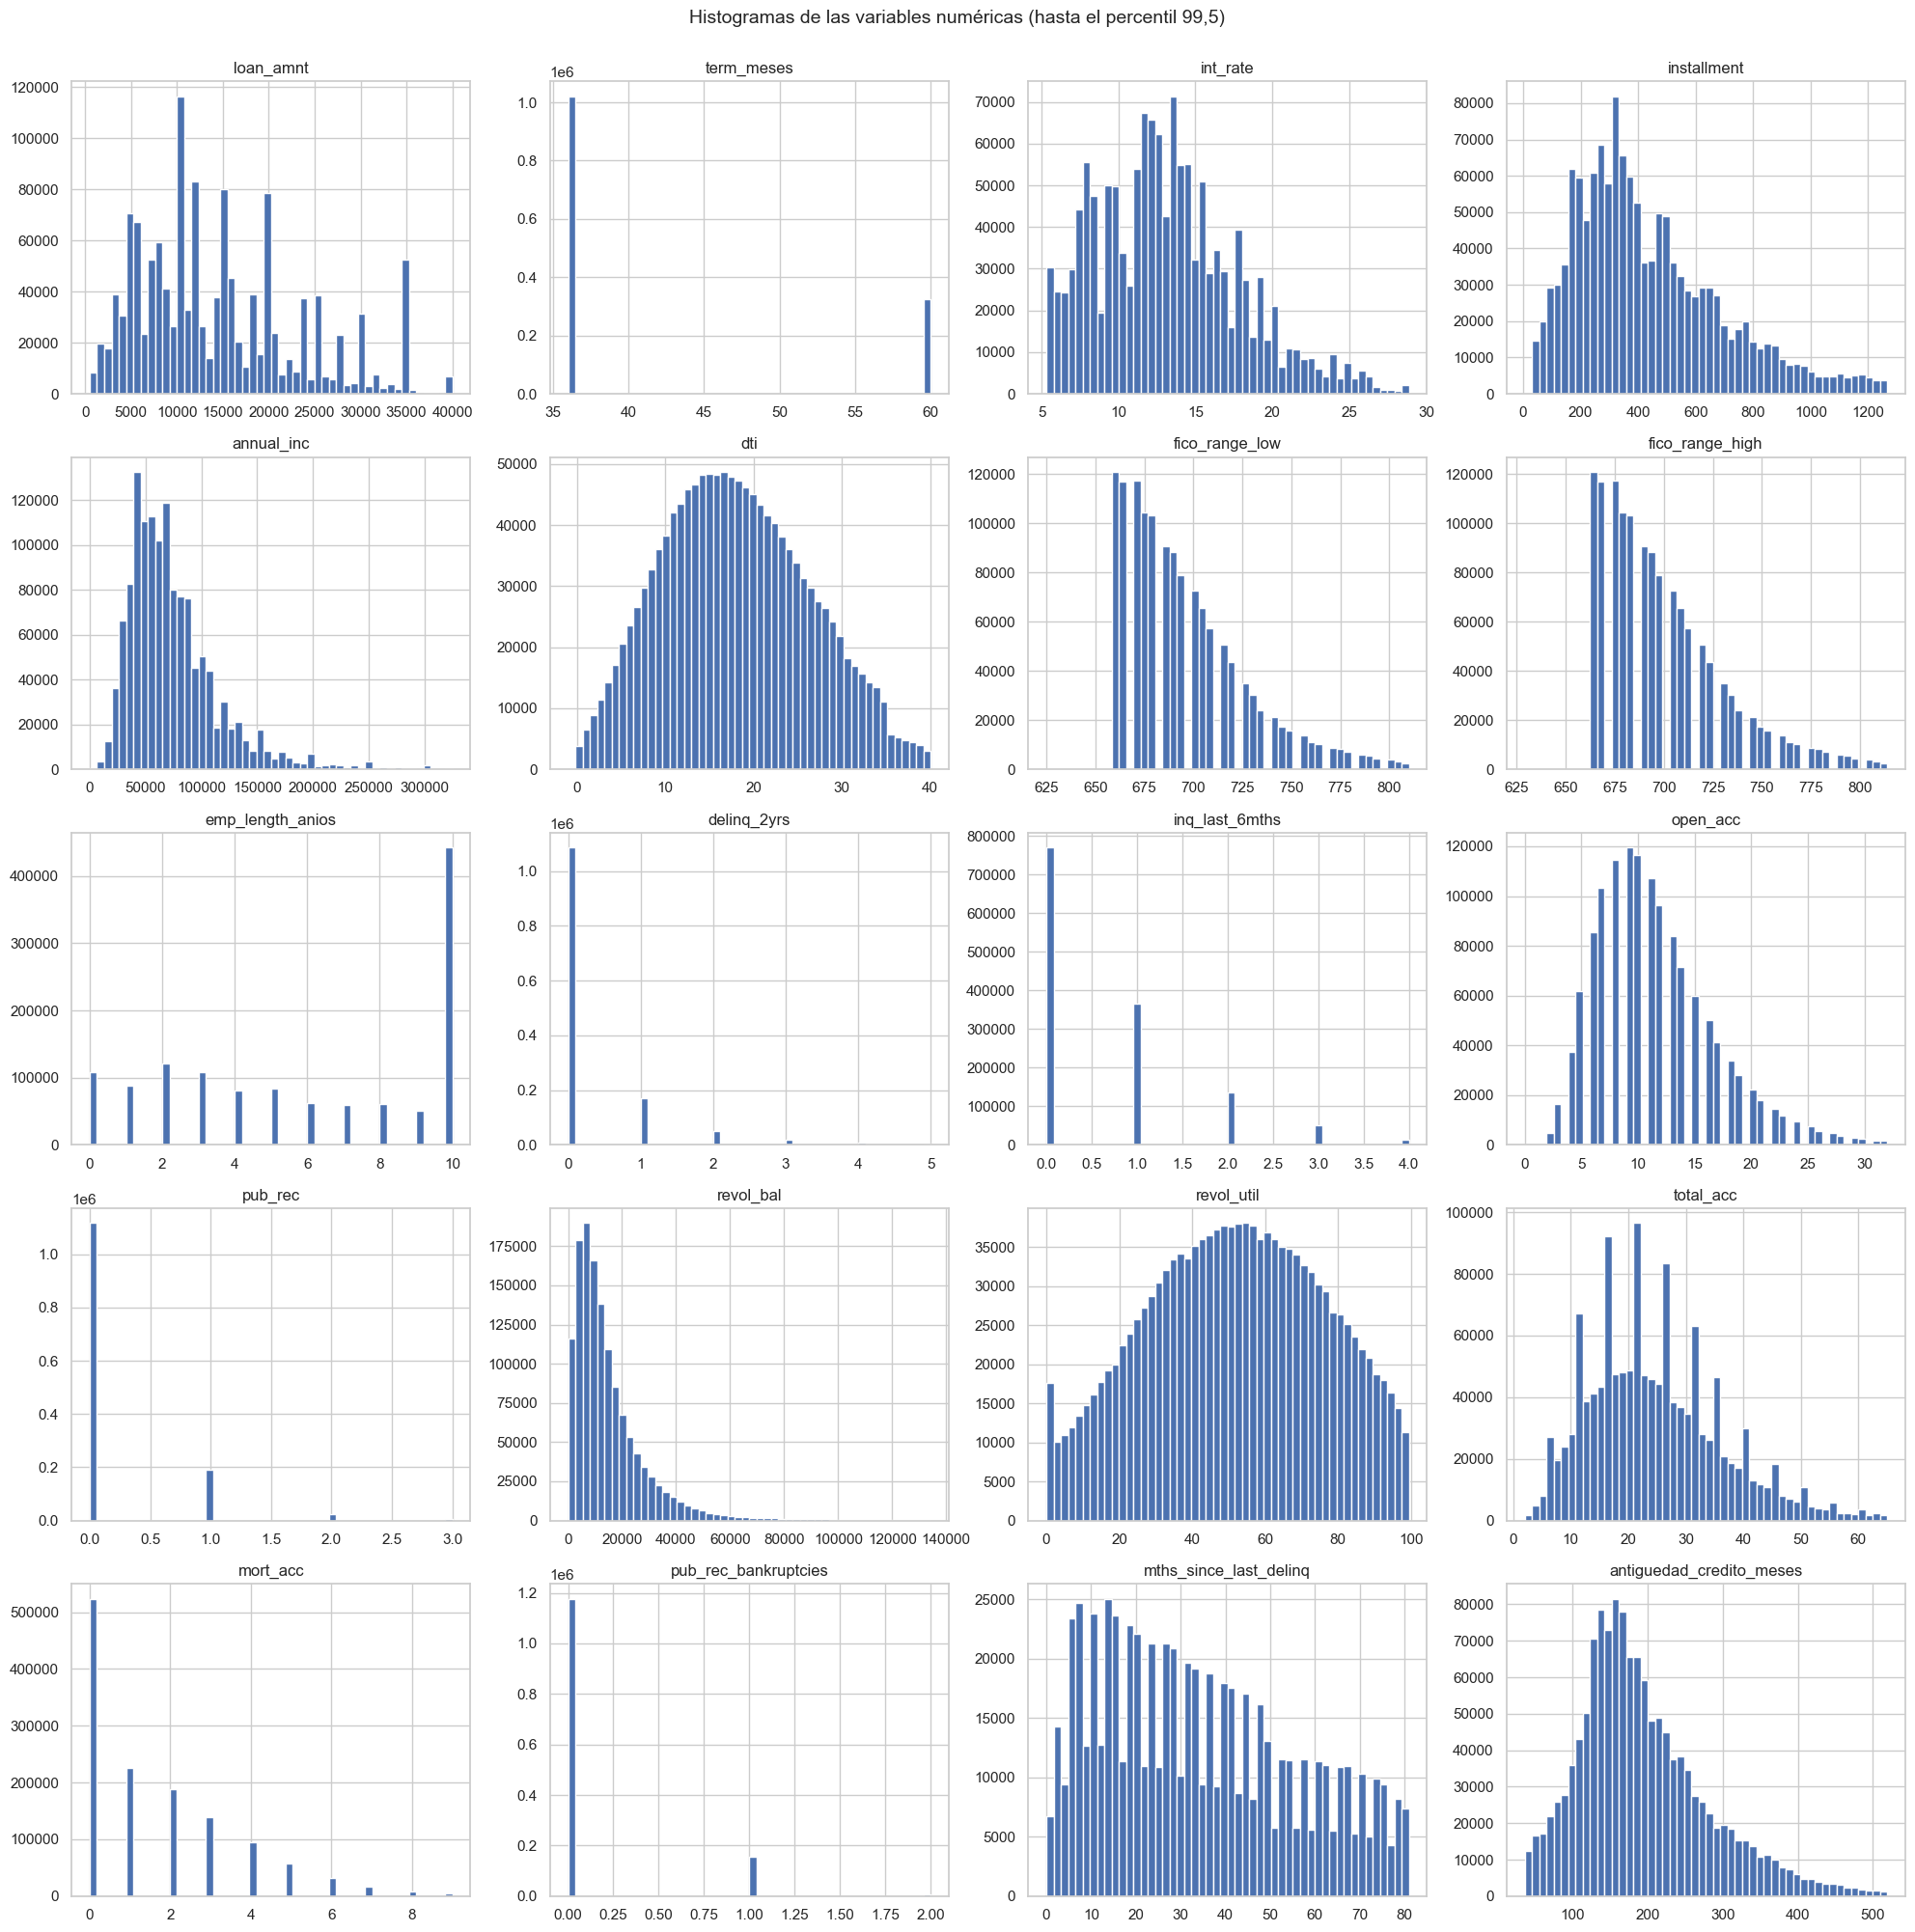

In [11]:
fig, axes = plt.subplots(5, 4, figsize=(20, 20))  # Cuadrícula de 5×4 gráficos
for ax, col in zip(axes.ravel(), cfg.NUMERICAS_EDA):  # Un histograma por variable
    x = df[col].dropna()  # Valores no nulos
    x = x[x <= x.quantile(0.995)]  # Recorta el 0,5 % superior solo para que el gráfico sea legible
    ax.hist(x, bins=50, color="#4C72B0", edgecolor="white")  # Histograma de frecuencias
    ax.set_title(col)  # Título con el nombre de la variable
fig.suptitle("Histogramas de las variables numéricas (hasta el percentil 99,5)", y=1.0, fontsize=14)  # Título general
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_histogramas")  # Exporta la figura
plt.show()  # Muestra la figura

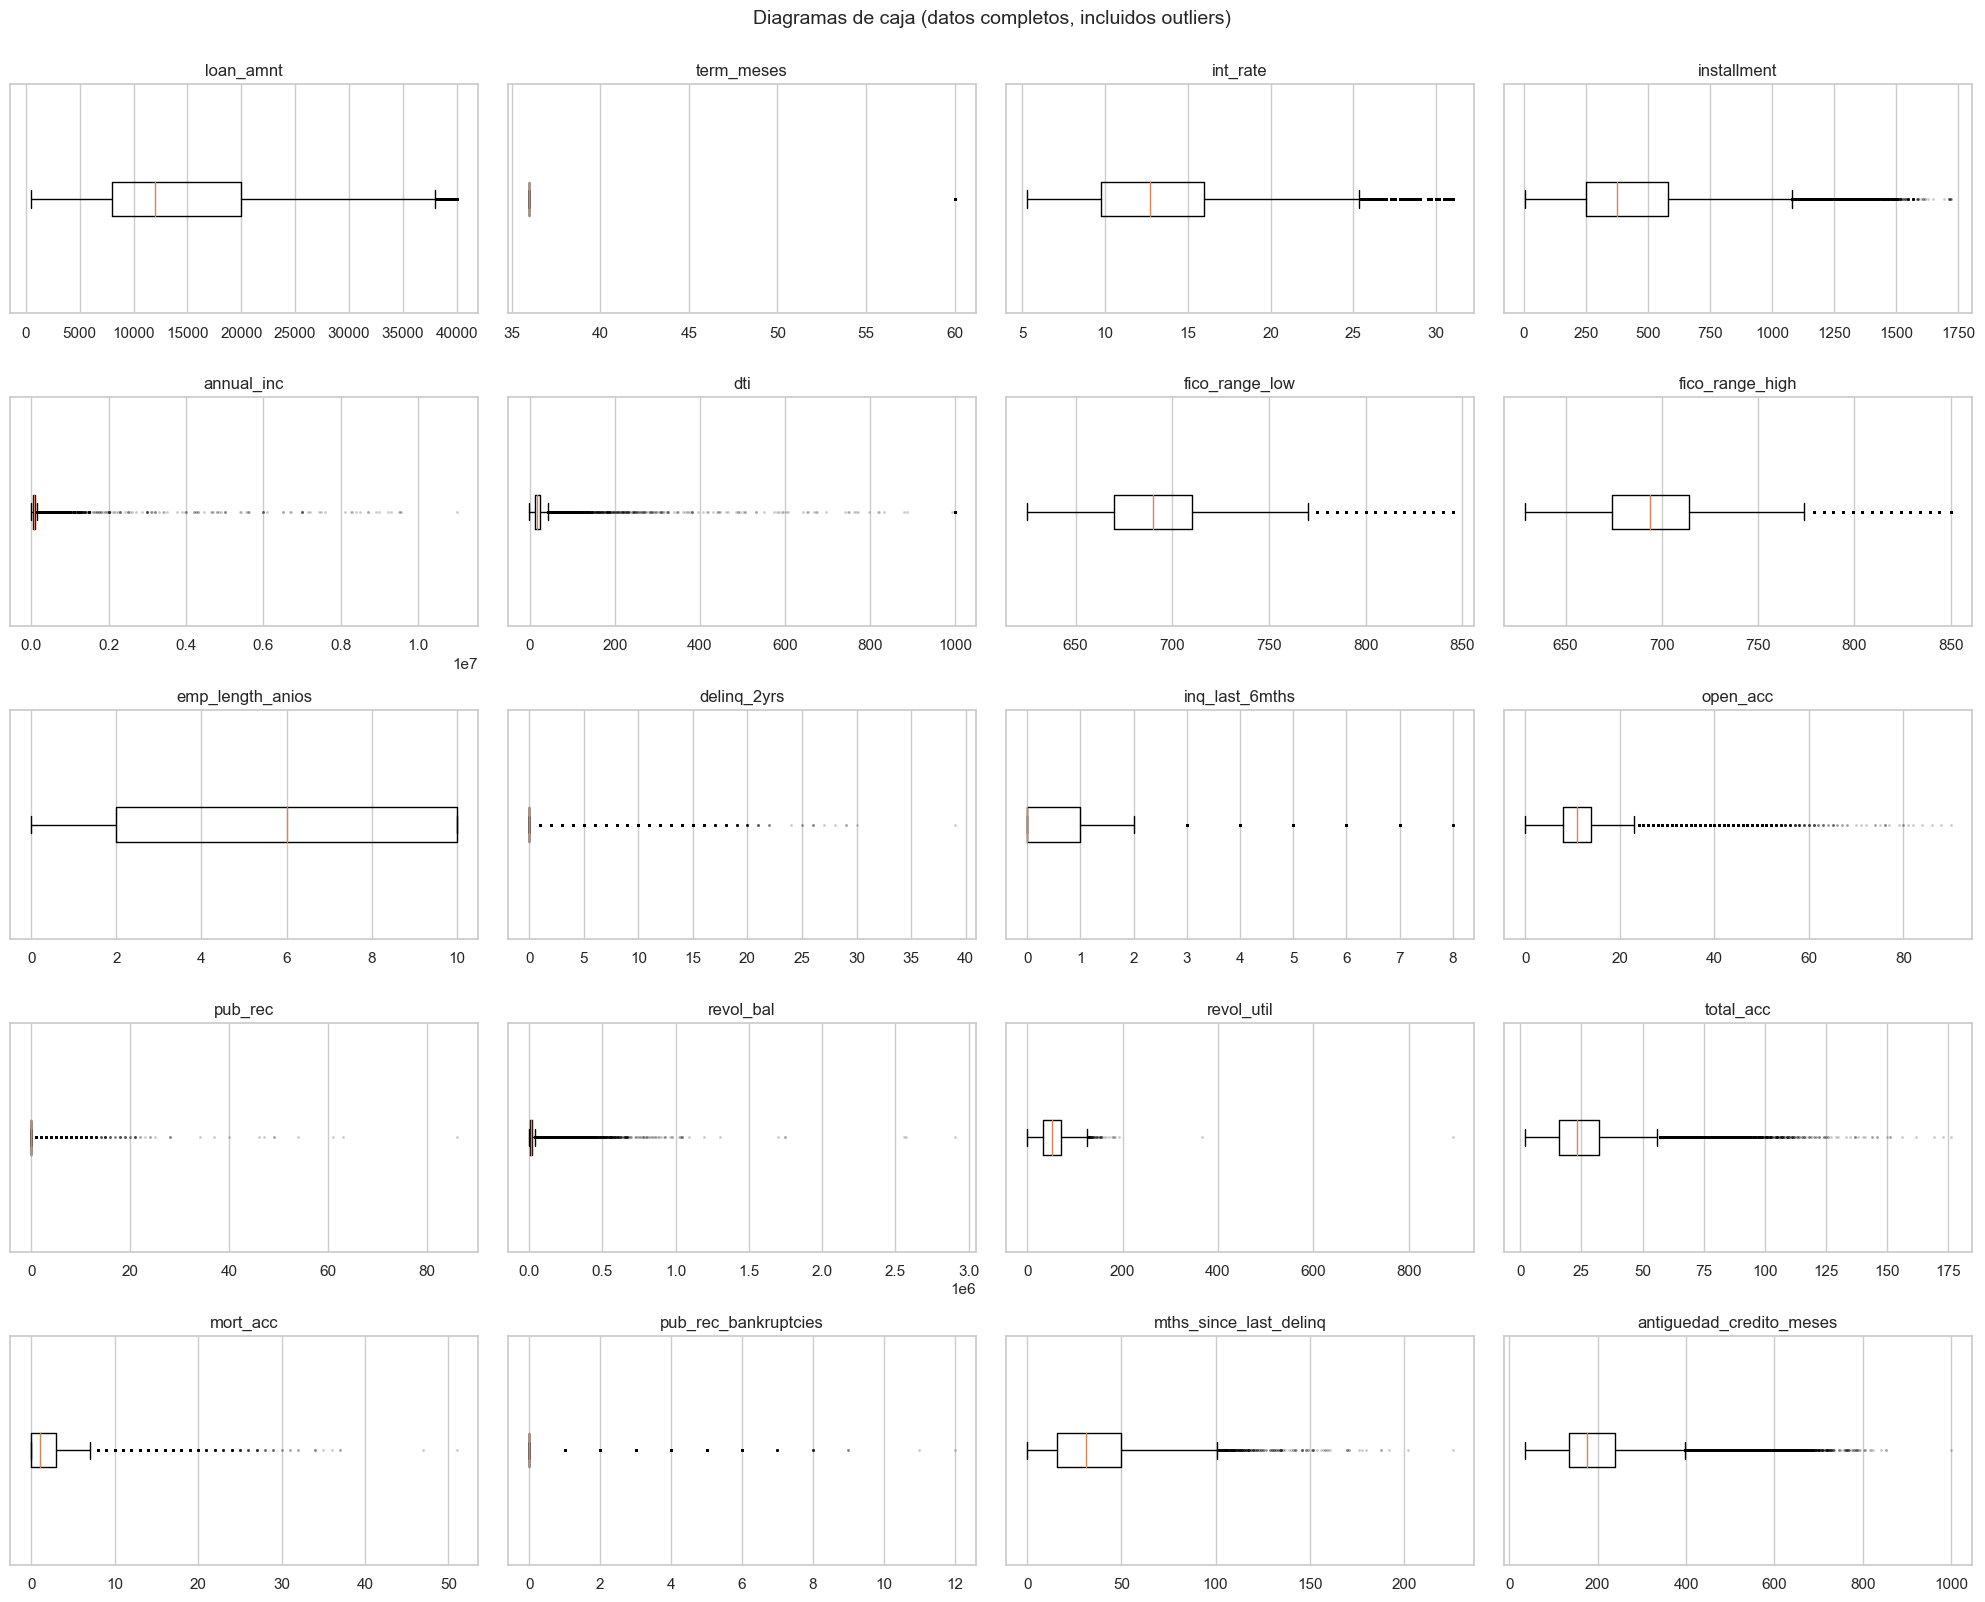

In [12]:
fig, axes = plt.subplots(5, 4, figsize=(20, 16))  # Cuadrícula de 5×4 gráficos
for ax, col in zip(axes.ravel(), cfg.NUMERICAS_EDA):  # Un boxplot por variable
    ax.boxplot(df[col].dropna(), vert=False, flierprops={"markersize": 1, "alpha": 0.2})  # Boxplot horizontal con todos los datos
    ax.set_title(col)  # Título con el nombre de la variable
    ax.set_yticks([])  # Oculta el eje Y (no aporta información)
fig.suptitle("Diagramas de caja (datos completos, incluidos outliers)", y=1.0, fontsize=14)  # Título general
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_boxplots")  # Exporta la figura
plt.show()  # Muestra la figura

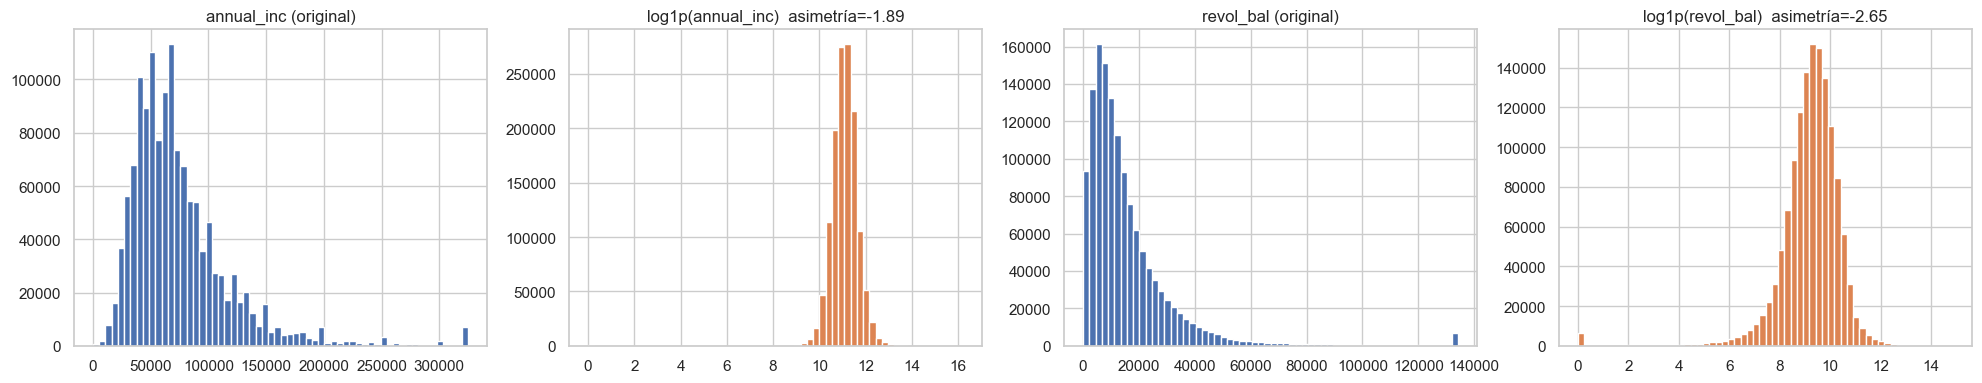

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))  # Cuatro gráficos en una fila
for i, col in enumerate(cfg.VARIABLES_LOG):  # Para cada variable muy asimétrica
    axes[2 * i].hist(df[col].dropna().clip(upper=df[col].quantile(0.995)), bins=60)  # Distribución original (recortada)
    axes[2 * i].set_title(f"{col} (original)")  # Título
    axes[2 * i + 1].hist(np.log1p(df[col].dropna().clip(lower=0)), bins=60, color="#DD8452")  # Distribución con log1p
    axes[2 * i + 1].set_title(f"log1p({col})  asimetría={stats.skew(np.log1p(df[col].dropna().clip(lower=0))):.2f}")  # Título con la nueva asimetría
fig.tight_layout()  # Ajusta los márgenes
plt.show()  # Muestra la figura

**Comentario (numéricas).**

* **Ninguna variable es normal** (p < 0.001 en D'Agostino-Pearson para todas; con 1,3 M de
  observaciones cualquier desviación es significativa). Las asimetrías más extremas son
  `annual_inc` (46, curtosis ≈ 4.800), `dti` (27), `revol_bal` (13,7) y `pub_rec` (11,6).
  `log1p` reduce la asimetría de `annual_inc` (46 → −1,9) y `revol_bal` (13,7 → −2,6; la cola
  izquierda restante se debe a los ceros), por lo que se aplicará en el preprocesamiento (ayuda a la regresión logística, LinearSVC y Naive Bayes;
  a los árboles les es indiferente). Box-Cox no es aplicable directamente porque hay ceros.
* **Outliers (regla IQR):** `delinq_2yrs` (19 %), `pub_rec` (17 %) y `pub_rec_bankruptcies`
  (12 %) tienen IQR = 0, así que cualquier valor distinto de 0 se marca como atípico: no son
  errores sino eventos raros. `term_meses` solo toma 36 o 60. Sí hay valores **implausibles**:
  `dti` = 999, `revol_util` = 892 %, `annual_inc` = 11 M. Se conservan (no se permite
  eliminar filas y los árboles son robustos); el escalado estándar los amortigua para los
  modelos lineales.
* **Faltantes:** solo `mths_since_last_delinq` supera el umbral del 30 % (50,5 %); el resto
  tiene < 6 %. Pese a superar el umbral **no se elimina**: su nulo significa "nunca tuvo
  morosidad" y es informativo (ver sección de faltantes) → indicador + imputación.

### Variables categóricas

In [14]:
tablas_cat = {}  # Diccionario variable → tabla de frecuencias
for col in cfg.CATEGORICAS_EDA:  # Recorre cada variable categórica
    t = df[col].value_counts(dropna=False).to_frame("frecuencia")  # Frecuencia absoluta (incluye nulos)
    t["porcentaje"] = 100 * t["frecuencia"] / len(df)  # Frecuencia relativa
    t["rara_<1%"] = t["porcentaje"] < 100 * cfg.UMBRAL_CATEGORIA_RARA  # Marca categorías con menos del 1 %
    tablas_cat[col] = t  # Guarda la tabla
    print(f"\n=== {col}: {len(t)} categorías, {int(t['rara_<1%'].sum())} raras, nulos = {100 * df[col].isna().mean():.2f} %")  # Resumen
    display(t.head(15))  # Muestra hasta 15 categorías


=== grade: 7 categorías, 1 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
grade,,,
B,392741,29.1933,False
C,381686,28.3716,False
A,235090,17.4748,False
D,200953,14.9373,False
E,93650,6.9612,False
F,32058,2.3829,False
G,9132,0.6788,True



=== sub_grade: 35 categorías, 10 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
sub_grade,,,
C1,85494,6.3550,False
B4,83199,6.1844,False
B5,82538,6.1352,False
B3,81827,6.0824,False
C2,79213,5.8881,False
C3,74998,5.5748,False
C4,74421,5.5319,False
B2,74024,5.5024,False
B1,71153,5.2890,False



=== home_ownership: 6 categorías, 3 raras, nulos = 0.00 %


...

,frecuencia,porcentaje,rara_<1%
addr_state,,,
CA,196528,14.6084,False
TX,110169,8.1891,False
NY,109842,8.1648,False
FL,95606,7.1066,False
IL,51720,3.8445,False
NJ,48449,3.6013,False
PA,45522,3.3838,False
OH,43842,3.2589,False
GA,43376,3.2242,False



=== initial_list_status: 2 categorías, 0 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
initial_list_status,,,
w,784010,58.2773,False
f,561300,41.7227,False



=== application_type: 2 categorías, 0 raras, nulos = 0.00 %


,frecuencia,porcentaje,rara_<1%
application_type,,,
Individual,1319510,98.0822,False
Joint App,25800,1.9178,False


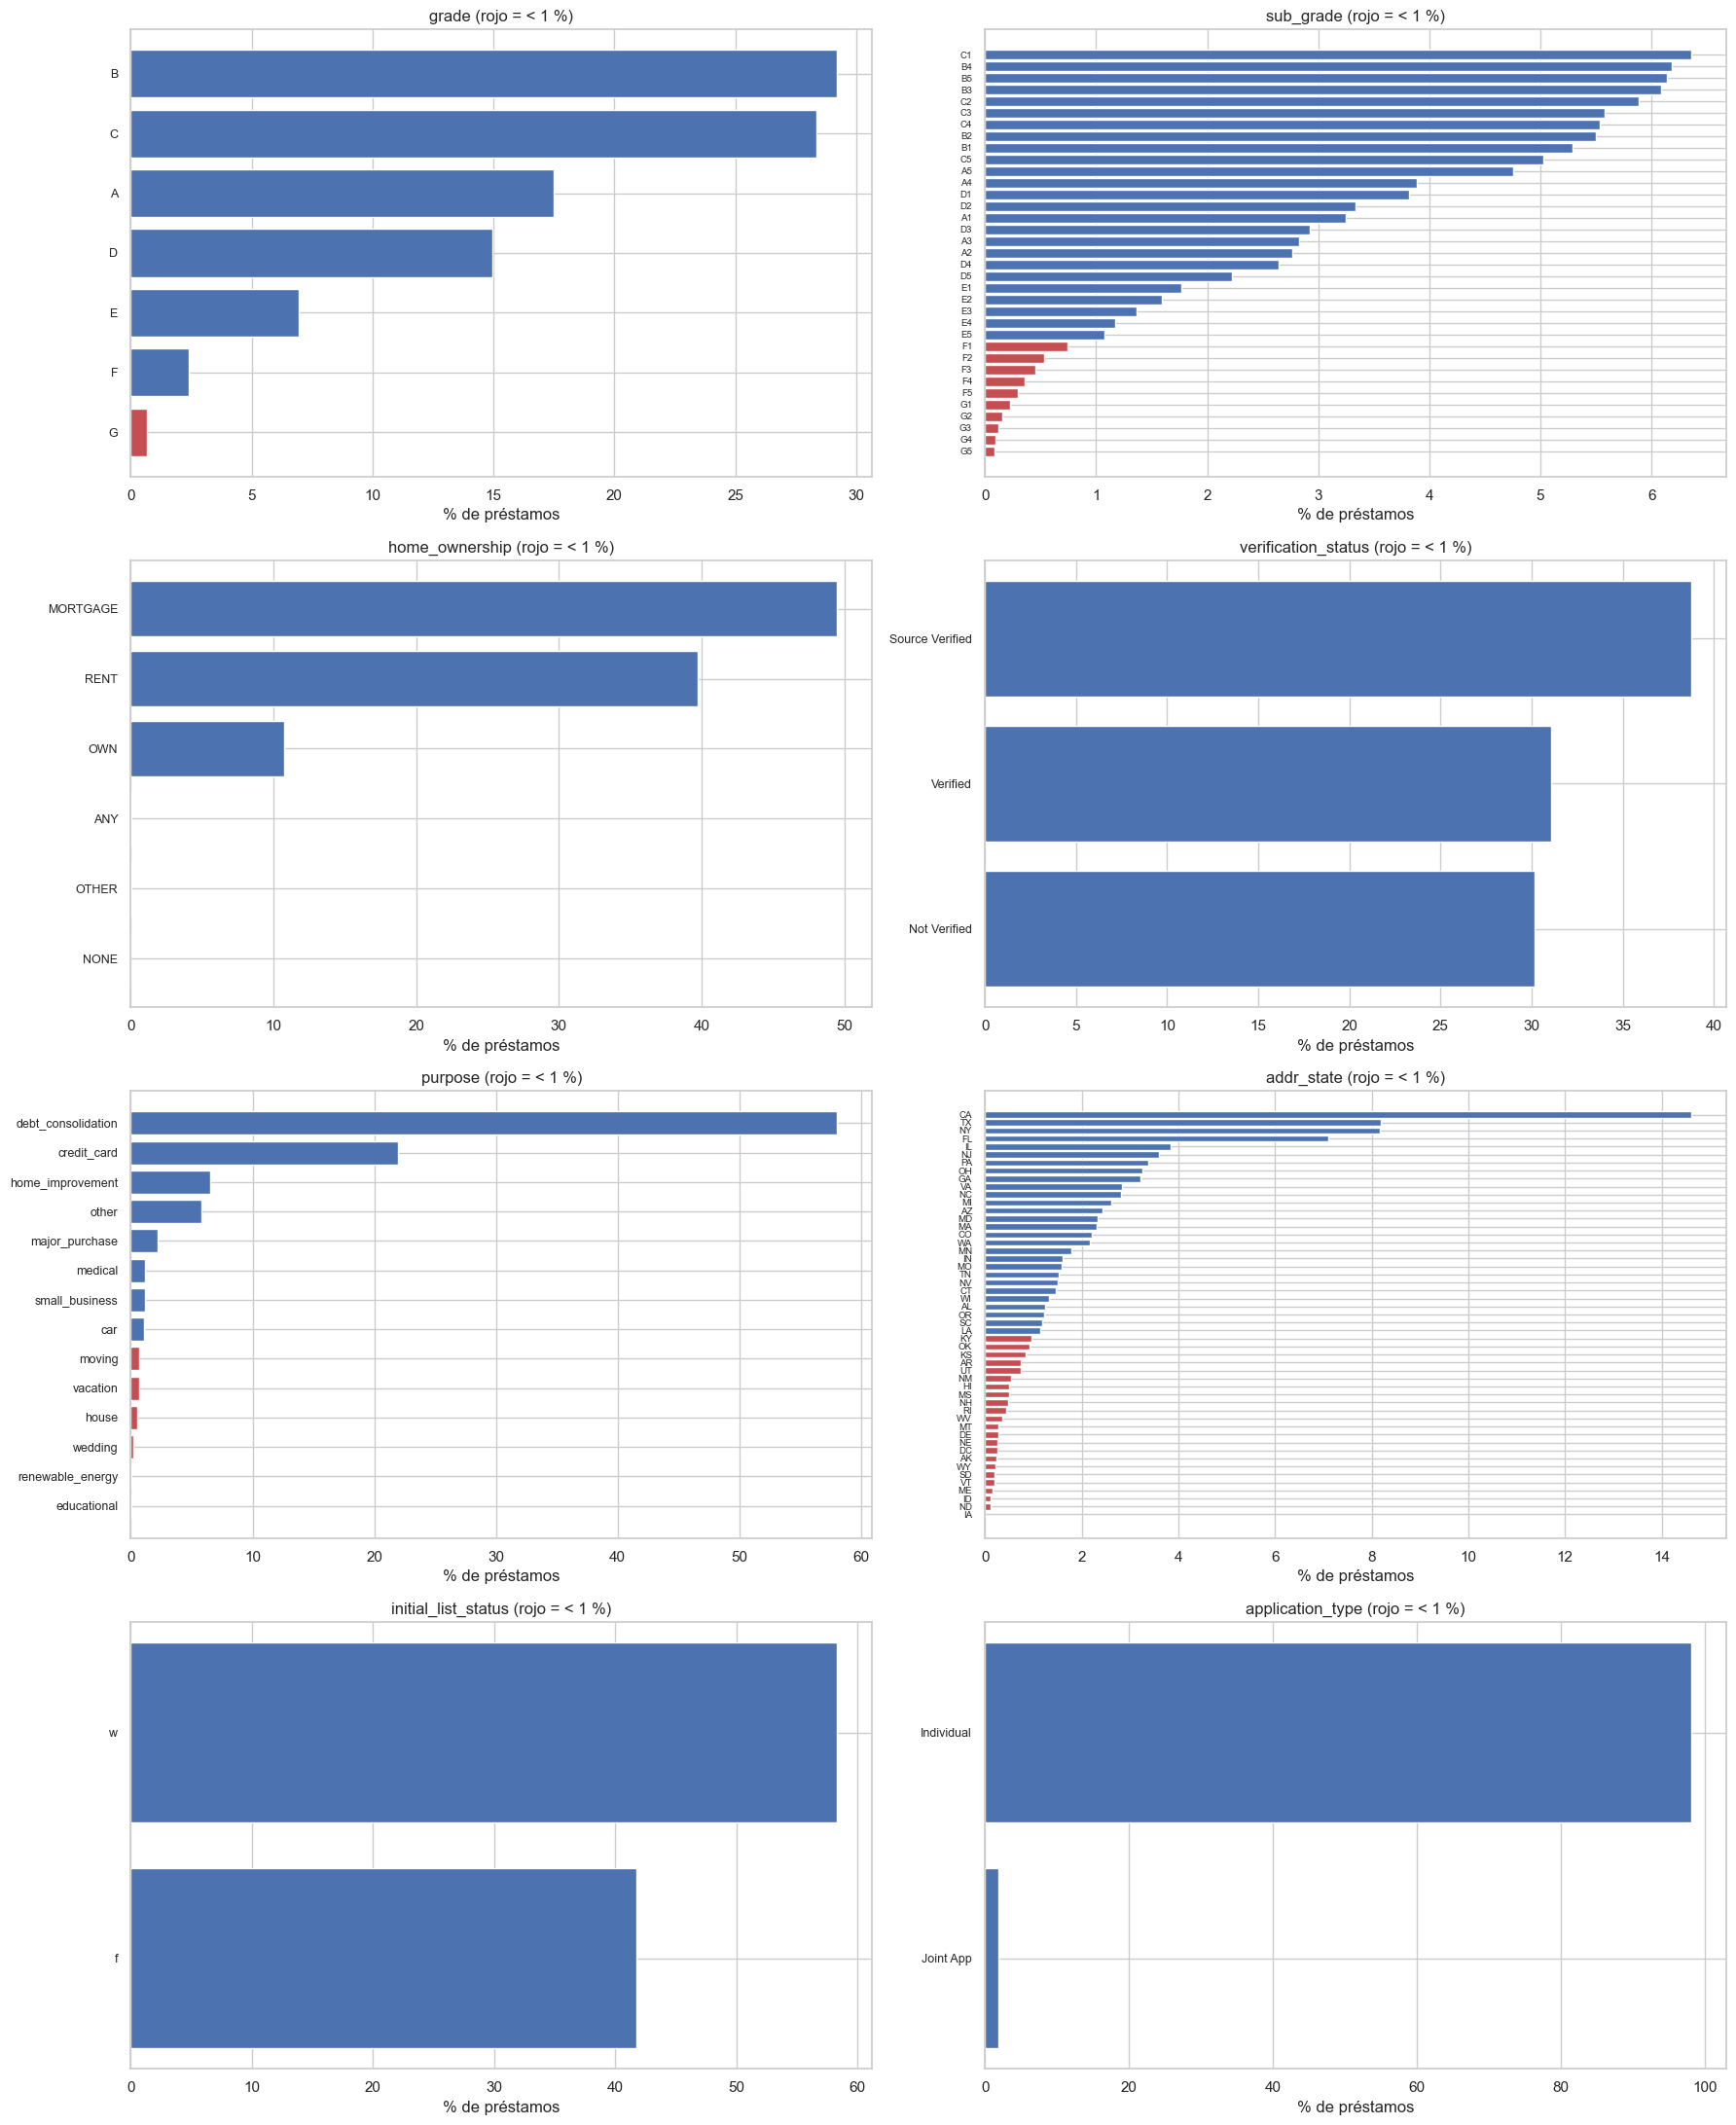

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))  # Cuadrícula de 4×2 gráficos
for ax, col in zip(axes.ravel(), cfg.CATEGORICAS_EDA):  # Un gráfico de barras por variable
    t = tablas_cat[col]["porcentaje"].sort_values()  # Porcentajes ordenados
    colores = ["#C44E52" if p < 1 else "#4C72B0" for p in t.values]  # Rojo para categorías raras
    ax.barh(t.index.astype(str), t.values, color=colores)  # Barras horizontales
    ax.set_title(f"{col} (rojo = < 1 %)")  # Título
    ax.set_xlabel("% de préstamos")  # Etiqueta del eje X
    ax.tick_params(axis="y", labelsize=7 if len(t) > 20 else 9)  # Letra más pequeña si hay muchas categorías
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_barras_categoricas")  # Exporta la figura
plt.show()  # Muestra la figura

**Comentario (categóricas).** No hay nulos en ninguna categórica de trabajo. Categorías con
menos del 1 %: `grade` G (0,68 %), 10 sub-calificaciones, `home_ownership` ANY/OTHER/NONE
(478 préstamos en total, **significado redundante**: las tres indican "otra tenencia"),
seis propósitos (`moving`, `vacation`, `house`, `wedding`, `renewable_energy`, `educational`)
y 23 estados. Decisión: agrupar en `OTROS` toda categoría con < 1 % **en train** (se aprende
solo con train para no filtrar información de test). `sub_grade` es una partición fina de
`grade` (redundante) y `application_type` está muy concentrada (98 % individual).

### Variable objetivo (`default`)

,n,%
0 = Fully Paid,1076751,80.0374
1 = Charged Off,268559,19.9626


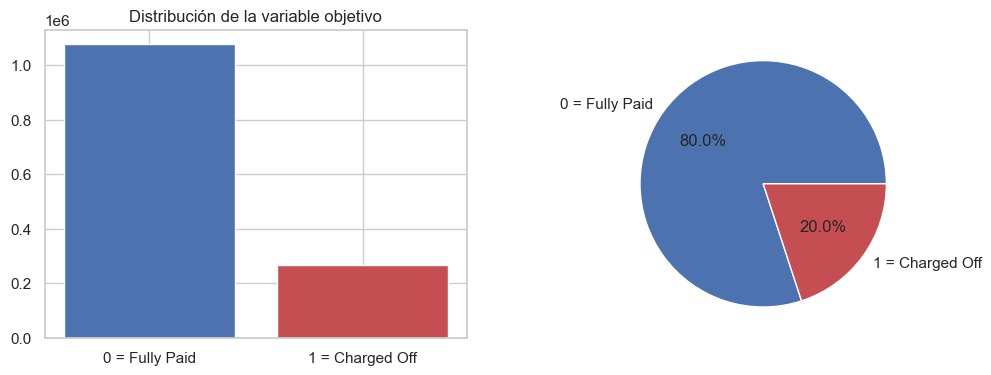

Razón de desbalance: 4.01 : 1


In [16]:
clases = df[cfg.COL_TARGET].value_counts().sort_index().to_frame("n")  # Conteo por clase
clases["%"] = 100 * clases["n"] / clases["n"].sum()  # Porcentaje por clase
clases.index = ["0 = Fully Paid", "1 = Charged Off"]  # Nombres descriptivos
display(clases)  # Muestra la tabla
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # Dos gráficos lado a lado
axes[0].bar(clases.index, clases["n"], color=["#4C72B0", "#C44E52"])  # Gráfico de barras
axes[0].set_title("Distribución de la variable objetivo")  # Título
axes[1].pie(clases["n"], labels=clases.index, autopct="%1.1f%%", colors=["#4C72B0", "#C44E52"])  # Gráfico de pastel
guardar_figura(fig, "01_target")  # Exporta la figura
plt.show()  # Muestra la figura
print(f"Razón de desbalance: {clases['n'].iloc[0] / clases['n'].iloc[1]:.2f} : 1")  # Relación entre clases

**Comentario.** El 80,0 % de los préstamos se pagó y el 20,0 % terminó en default
(desbalance moderado 4:1). Implicaciones: (1) la partición debe ser **estratificada**;
(2) la *accuracy* es engañosa (un modelo trivial obtiene 0,80), por lo que el criterio de
selección es el **AUC ROC** y se reportan también precisión, recall, F1 y AUC-PR; (3) el
umbral 0,5 tenderá a predecir casi siempre "pagado", así que para las decisiones (McNemar,
F1) se optimiza el umbral **con datos de train**. No se aplica sobremuestreo: con 269 mil
defaults la clase minoritaria está bien representada.

## 2.4 Análisis bidimensional

### Numéricas vs. `default`

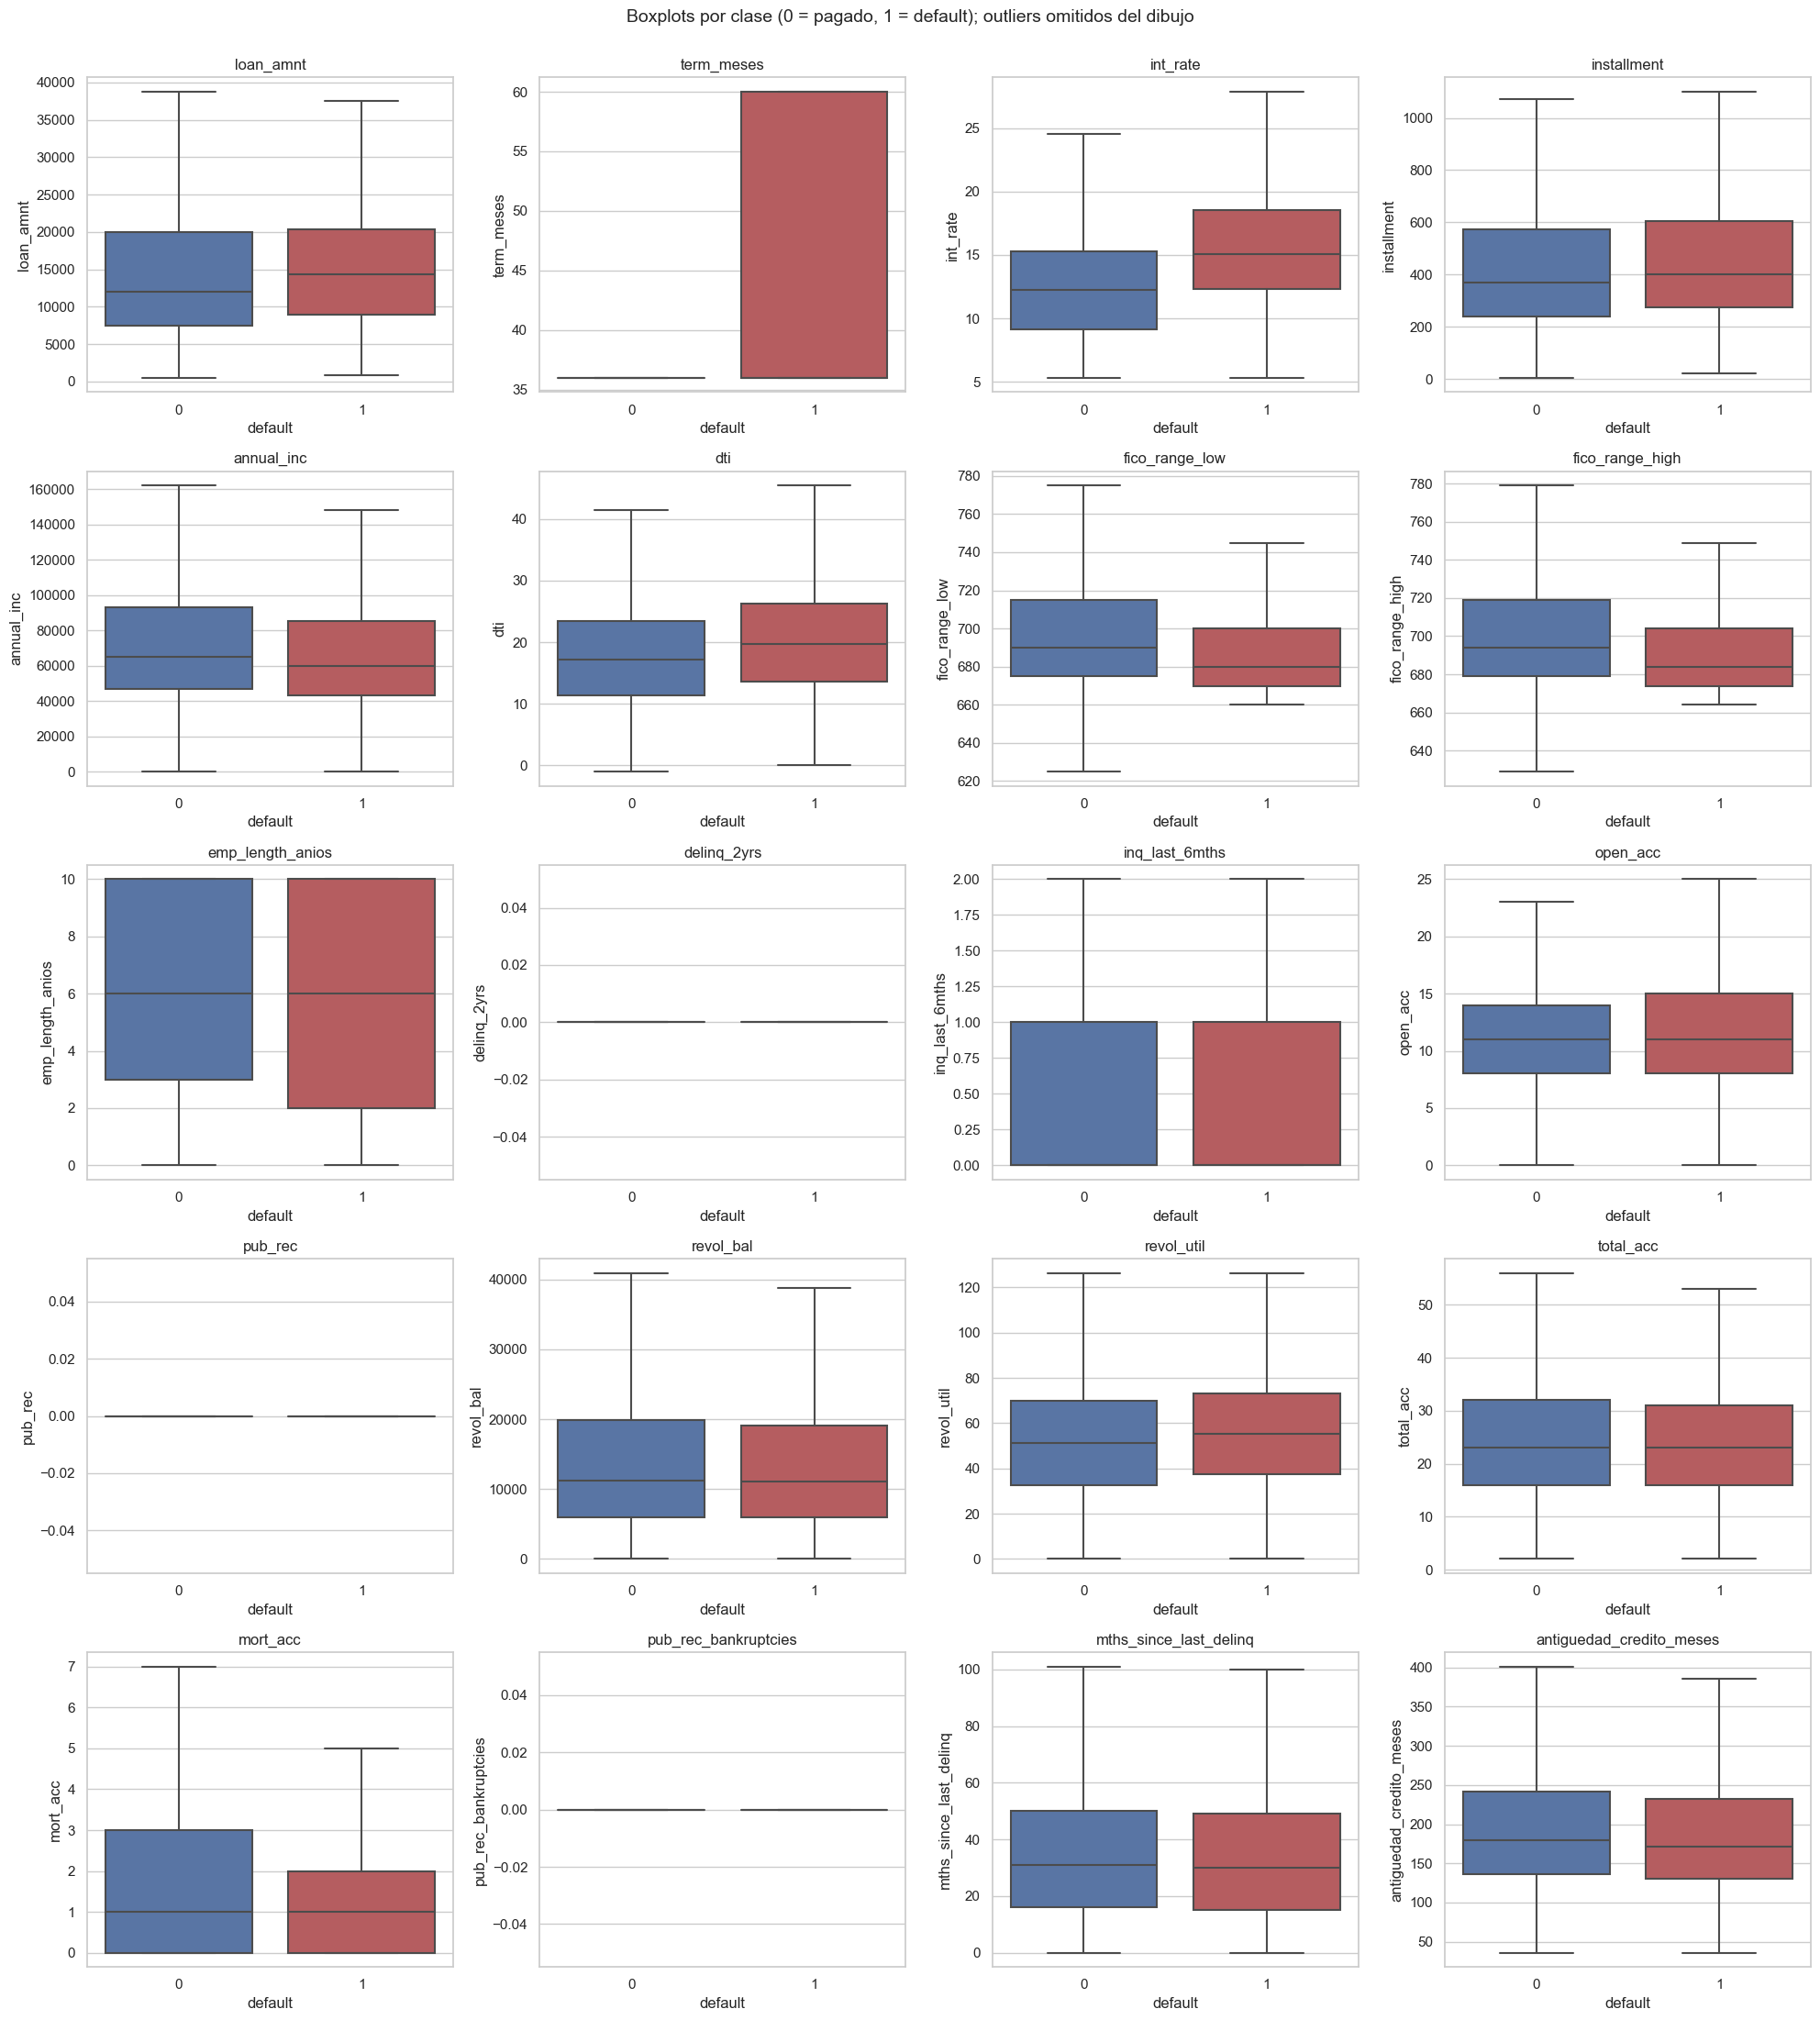

In [17]:
fig, axes = plt.subplots(5, 4, figsize=(20, 22))  # Cuadrícula de 5×4 gráficos
for ax, col in zip(axes.ravel(), cfg.NUMERICAS_EDA):  # Un boxplot comparativo por variable
    sns.boxplot(data=df, x=cfg.COL_TARGET, y=col, ax=ax, showfliers=False,  # Boxplot por clase (sin dibujar outliers para legibilidad)
                palette=["#4C72B0", "#C44E52"])  # Colores por clase
    ax.set_title(col)  # Título
fig.suptitle("Boxplots por clase (0 = pagado, 1 = default); outliers omitidos del dibujo", y=1.0, fontsize=14)  # Título general
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_boxplots_por_clase")  # Exporta la figura
plt.show()  # Muestra la figura

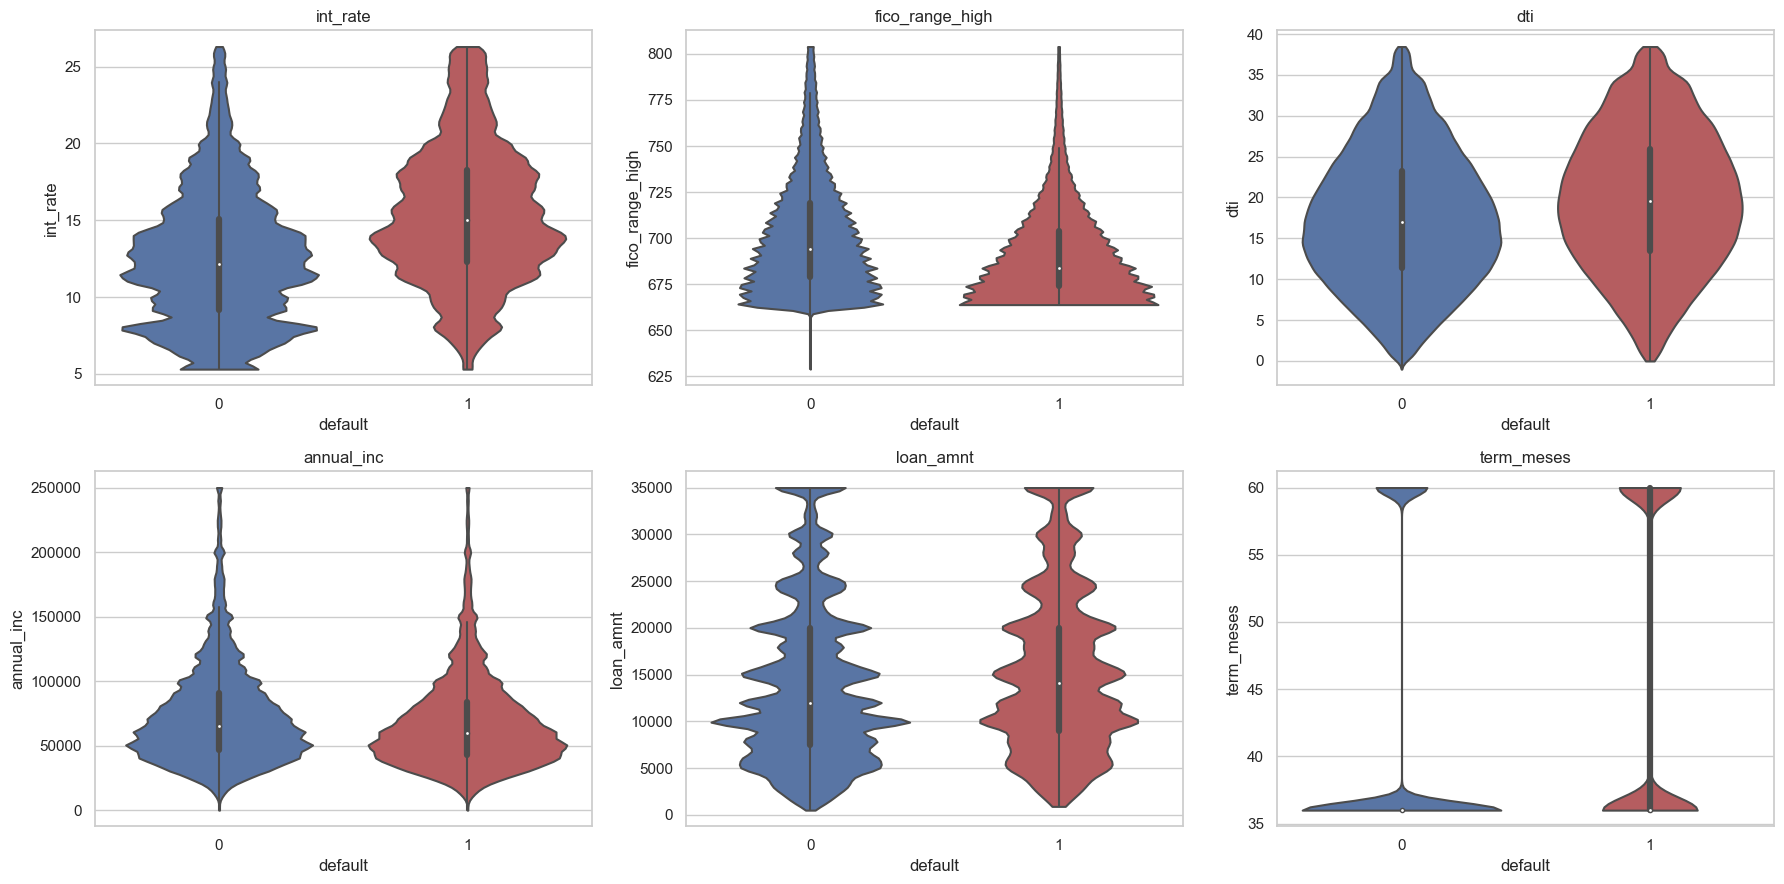

In [18]:
claves = ["int_rate", "fico_range_high", "dti", "annual_inc", "loan_amnt", "term_meses"]  # Variables clave para violines
fig, axes = plt.subplots(2, 3, figsize=(18, 9))  # Cuadrícula de 2×3
for ax, col in zip(axes.ravel(), claves):  # Un violin plot por variable
    datos = df[[col, cfg.COL_TARGET]].dropna()  # Datos sin nulos
    datos = datos[datos[col] <= datos[col].quantile(0.99)]  # Recorta el 1 % superior solo para visualizar
    sns.violinplot(data=datos, x=cfg.COL_TARGET, y=col, ax=ax,  # Violin plot por clase
                   palette=["#4C72B0", "#C44E52"], cut=0)  # Colores y sin extrapolar la densidad
    ax.set_title(col)  # Título
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_violines")  # Exporta la figura
plt.show()  # Muestra la figura

In [19]:
filas = []  # Lista de resultados por variable
for col in cfg.NUMERICAS_EDA:  # Recorre cada variable numérica
    d = df[[col, cfg.COL_TARGET]].dropna()  # Pares sin nulos
    x0 = d.loc[d[cfg.COL_TARGET] == 0, col]  # Valores de la clase 0
    x1 = d.loc[d[cfg.COL_TARGET] == 1, col]  # Valores de la clase 1
    t_stat, p_t = stats.ttest_ind(x1, x0, equal_var=False)  # Prueba t de Welch (varianzas distintas)
    u_stat, p_u = stats.mannwhitneyu(x1, x0, alternative="two-sided")  # Prueba de Mann-Whitney (no paramétrica)
    r_pb, p_pb = stats.pointbiserialr(d[cfg.COL_TARGET], d[col])  # Correlación punto-biserial
    filas.append({  # Guarda el resultado
        "media_0": x0.mean(), "media_1": x1.mean(), "dif_medias": x1.mean() - x0.mean(),  # Medias y diferencia
        "mediana_0": x0.median(), "mediana_1": x1.median(),  # Medianas por clase
        "p_t_welch": p_t, "p_mann_whitney": p_u,  # Valores p de ambas pruebas
        "r_punto_biserial": r_pb, "abs_r": abs(r_pb),  # Correlación y su valor absoluto
    })
biv_num = pd.DataFrame(filas, index=cfg.NUMERICAS_EDA).sort_values("abs_r", ascending=False)  # Ordena por fuerza de asociación
biv_num  # Muestra la tabla

,media_0,media_1,dif_medias,mediana_0,mediana_1,p_t_welch,p_mann_whitney,r_punto_biserial,abs_r
int_rate,12.6233,15.7107,3.0874,12.2300,15.0500,0.0000,0.0000,0.2588,0.2588
term_meses,40.8871,45.4108,4.5237,36.0000,36.0000,0.0000,0.0000,0.1761,0.1761
fico_range_low,698.2639,687.8501,-10.4138,690.0000,680.0000,0.0000,0.0000,-0.1307,0.1307
fico_range_high,702.2641,691.8502,-10.4139,694.0000,684.0000,0.0000,0.0000,-0.1307,0.1307
dti,17.8116,20.1712,2.3596,17.1100,19.7600,0.0000,0.0000,0.0845,0.0845
mort_acc,1.7465,1.3710,-0.3754,1.0000,1.0000,0.0000,0.0000,-0.0753,0.0753
loan_amnt,"14,134.3698","15,565.0554","1,430.6856","12,000.0000","14,350.0000",0.0000,0.0000,0.0656,0.0656
inq_last_6mths,0.6244,0.7780,0.1536,0.0000,0.0000,0.0000,0.0000,0.0655,0.0655
revol_util,51.0747,54.7584,3.6838,51.3000,55.5000,0.0000,0.0000,0.0600,0.0600
installment,431.3232,465.1480,33.8248,368.2600,402.8300,0.0000,0.0000,0.0517,0.0517


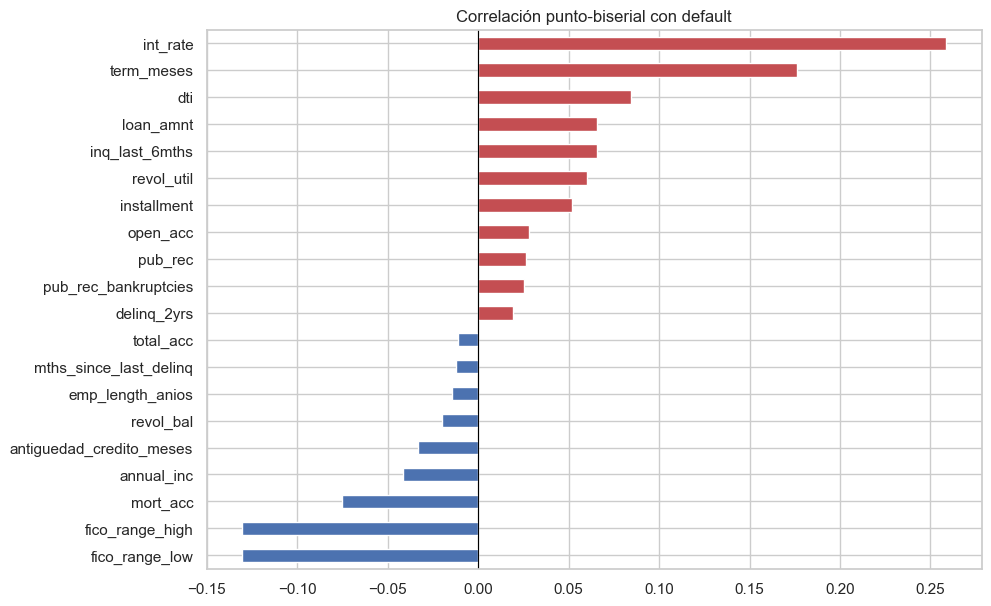

In [20]:
fig, ax = plt.subplots(figsize=(10, 7))  # Figura para la correlación punto-biserial
biv_num["r_punto_biserial"].sort_values().plot.barh(ax=ax, color=["#C44E52" if v > 0 else "#4C72B0" for v in biv_num["r_punto_biserial"].sort_values()])  # Barras por signo
ax.set_title("Correlación punto-biserial con default")  # Título
ax.axvline(0, color="black", lw=0.8)  # Línea de referencia en cero
guardar_figura(fig, "01_punto_biserial")  # Exporta la figura
plt.show()  # Muestra la figura

**Comentario.** Todas las diferencias de medias son significativas (p < 0.001 en Welch y
Mann-Whitney), algo esperable con 1,3 M de filas; por eso se ordena por la **magnitud** de la
correlación punto-biserial. Las numéricas más asociadas al default son `int_rate`
(r = 0,26; media 15,7 % en defaults vs 12,6 %), `term_meses` (0,18: los préstamos a 60
meses son más riesgosos), `fico_range_high` (−0,13; 10 puntos menos en defaults), `dti`
(0,08), `mort_acc` (−0,08), `loan_amnt`, `inq_last_6mths` y `revol_util` (≈ 0,06). El
resto tiene |r| < 0,05: aportan poco de forma individual, aunque pueden interactuar en
modelos no lineales.

### Categóricas vs. `default`

In [21]:
def v_cramer(x, y):  # Coeficiente V de Cramér entre dos variables categóricas
    tabla = pd.crosstab(x, y)  # Tabla de contingencia
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]  # Estadístico chi-cuadrado
    n = tabla.values.sum()  # Total de observaciones
    k = min(tabla.shape) - 1  # Grados de libertad mínimos
    return np.sqrt(chi2 / (n * k)) if k > 0 else 0.0  # V = sqrt(χ² / (n·k))

filas = []  # Resultados de la prueba chi-cuadrado
tasas_cat = {}  # Tasa de default por categoría
for col in cfg.CATEGORICAS_EDA:  # Recorre cada categórica
    x = df[col].fillna(cfg.CATEGORIA_FALTANTE)  # Nulos como categoría propia
    tabla = pd.crosstab(x, df[cfg.COL_TARGET])  # Tabla de contingencia
    chi2, p, gl, _ = stats.chi2_contingency(tabla)  # Prueba de independencia
    tasa = pd.crosstab(x, df[cfg.COL_TARGET], normalize="index")[1].sort_values(ascending=False)  # Proporción de default por categoría
    tasas_cat[col] = tasa  # Guarda las tasas
    filas.append({"chi2": chi2, "gl": gl, "p_valor": p, "V_cramer": v_cramer(x, df[cfg.COL_TARGET]),  # Estadísticos
                  "categoria_mayor_tasa": tasa.index[0], "mayor_tasa": tasa.iloc[0],  # Categoría más riesgosa
                  "categoria_menor_tasa": tasa.index[-1], "menor_tasa": tasa.iloc[-1]})  # Categoría menos riesgosa
biv_cat = pd.DataFrame(filas, index=cfg.CATEGORICAS_EDA).sort_values("V_cramer", ascending=False)  # Tabla ordenada
biv_cat  # Muestra la tabla

,chi2,gl,p_valor,V_cramer,categoria_mayor_tasa,mayor_tasa,categoria_menor_tasa,menor_tasa
sub_grade,"96,525.3877",34,0.0000,0.2679,G5,0.5360,A1,0.0322
grade,"92,284.2511",6,0.0000,0.2619,G,0.4993,A,0.0604
verification_status,"11,387.4390",2,0.0000,0.0920,Verified,0.2385,Not Verified,0.1467
home_ownership,"6,743.1900",5,0.0000,0.0708,RENT,0.2322,NONE,0.1458
purpose,"4,144.1960",13,0.0000,0.0555,small_business,0.2971,wedding,0.1216
addr_state,"3,403.5833",50,0.0000,0.0503,MS,0.2608,DC,0.1321
application_type,352.1009,1,0.0000,0.0162,Joint App,0.2459,Individual,0.1987
initial_list_status,71.3174,1,0.0000,0.0073,w,0.2021,f,0.1962


In [22]:
for col in ["grade", "home_ownership", "verification_status", "purpose", "initial_list_status", "application_type"]:  # Tablas cruzadas de las categóricas más legibles
    ct = pd.crosstab(df[col].fillna(cfg.CATEGORIA_FALTANTE), df[cfg.COL_TARGET], margins=True)  # Frecuencias con totales
    ct["tasa_default_%"] = 100 * ct[1] / ct["All"]  # Tasa de impago por categoría
    display(ct.sort_values("tasa_default_%", ascending=False))  # Muestra la tabla ordenada por riesgo

default,0,1,All,tasa_default_%
grade,,,,
G,4572,4560,9132,49.9343
F,17567,14491,32058,45.2024
E,57615,36035,93650,38.4784
D,139899,61054,200953,30.3822
C,296037,85649,381686,22.4396
All,1076751,268559,1345310,19.9626
B,340172,52569,392741,13.3852
A,220889,14201,235090,6.0407


default,0,1,All,tasa_default_%
home_ownership,,,,
RENT,410347,124074,534421,23.2165
OWN,114968,29864,144832,20.6198
All,1076751,268559,1345310,19.9626
ANY,230,56,286,19.5804
OTHER,117,27,144,18.7500
MORTGAGE,551048,114531,665579,17.2077
NONE,41,7,48,14.5833


default,0,1,All,tasa_default_%
verification_status,,,,
Verified,318544,99792,418336,23.8545
Source Verified,412041,109232,521273,20.9549
All,1076751,268559,1345310,19.9626
Not Verified,346166,59535,405701,14.6746


default,0,1,All,tasa_default_%
purpose,,,,
small_business,10836,4580,15416,29.7094
renewable_energy,712,221,933,23.6870
moving,7266,2214,9480,23.3544
house,5666,1587,7253,21.8806
medical,12167,3387,15554,21.7757
debt_consolidation,615307,165014,780321,21.1469
other,61490,16385,77875,21.0401
All,1076751,268559,1345310,19.9626
vacation,7327,1738,9065,19.1726


default,0,1,All,tasa_default_%
initial_list_status,,,,
w,625570,158440,784010,20.2089
All,1076751,268559,1345310,19.9626
f,451181,110119,561300,19.6186


default,0,1,All,tasa_default_%
application_type,,,,
Joint App,19456,6344,25800,24.5891
All,1076751,268559,1345310,19.9626
Individual,1057295,262215,1319510,19.8721


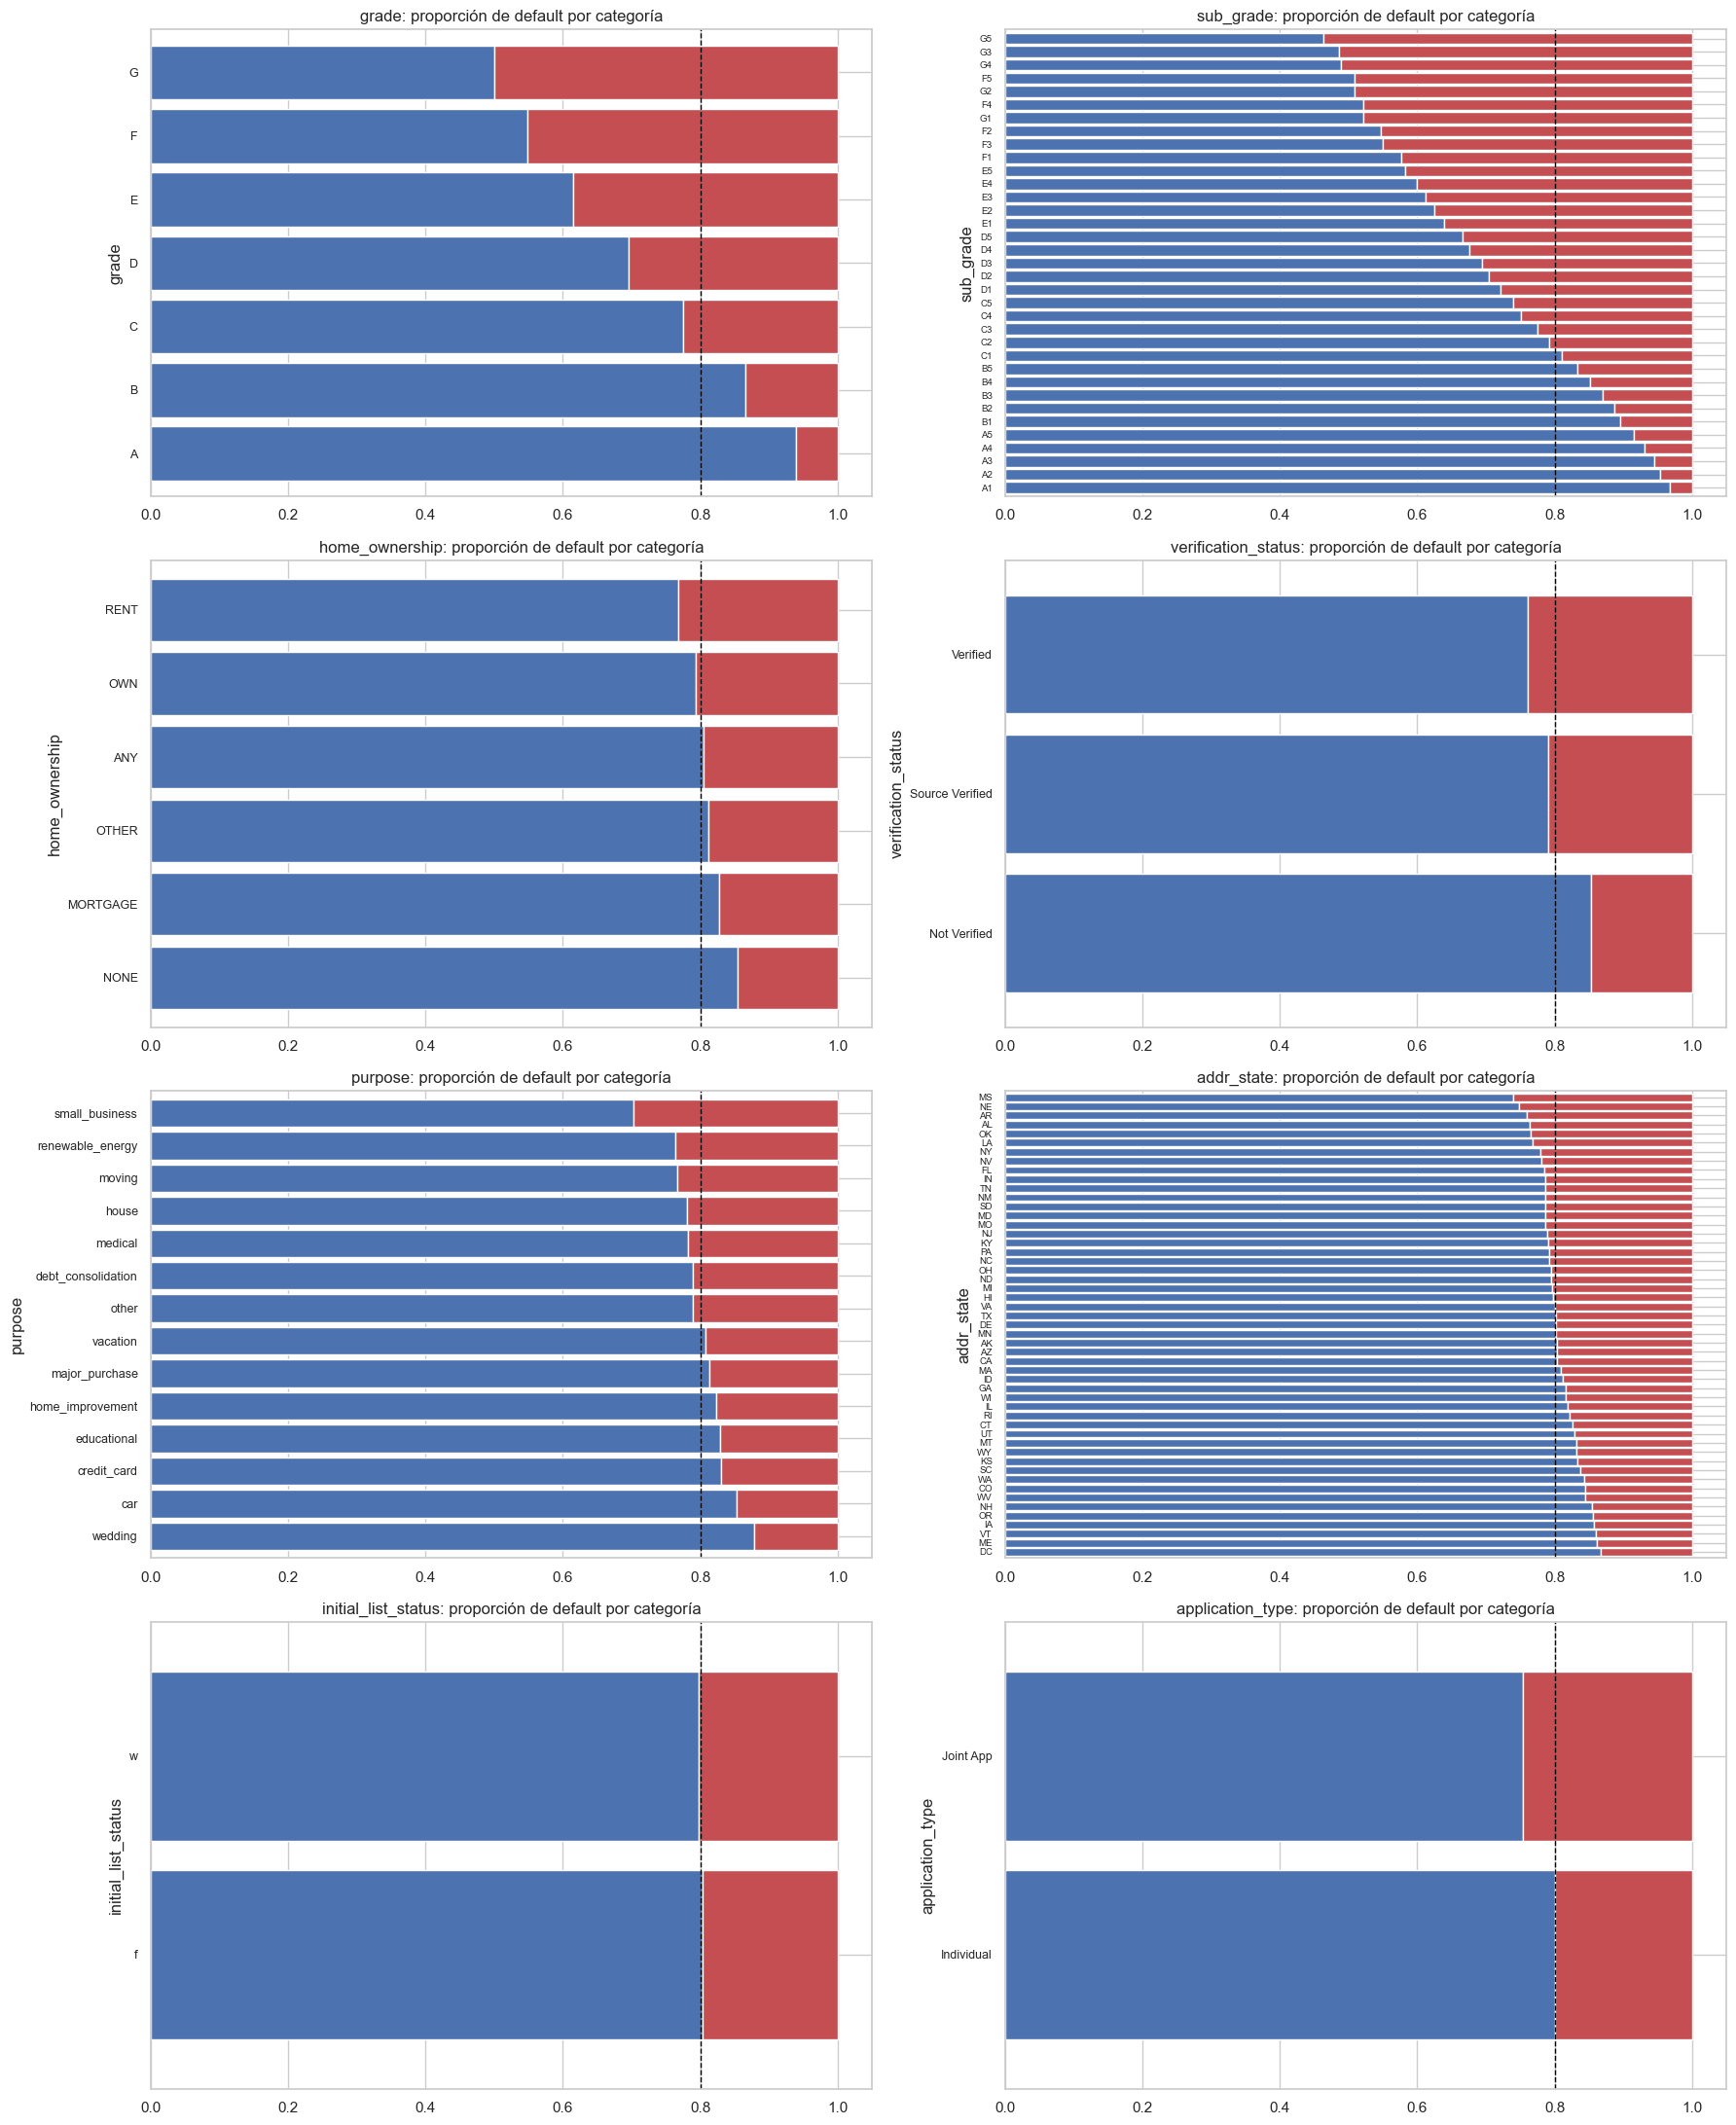

In [23]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))  # Cuadrícula de 4×2
tasa_global = df[cfg.COL_TARGET].mean()  # Tasa de default global
for ax, col in zip(axes.ravel(), cfg.CATEGORICAS_EDA):  # Un gráfico de barras apiladas por variable
    prop = pd.crosstab(df[col].fillna(cfg.CATEGORIA_FALTANTE), df[cfg.COL_TARGET], normalize="index")  # Proporciones por categoría
    prop = prop.sort_values(1)  # Ordena por tasa de default
    prop.plot.barh(stacked=True, ax=ax, color=["#4C72B0", "#C44E52"], width=0.85, legend=False)  # Barras apiladas 0/1
    ax.axvline(1 - tasa_global, color="black", ls="--", lw=1)  # Línea de la tasa global
    ax.set_title(f"{col}: proporción de default por categoría")  # Título
    ax.tick_params(axis="y", labelsize=7 if len(prop) > 20 else 9)  # Letra más pequeña si hay muchas categorías
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_barras_apiladas")  # Exporta la figura
plt.show()  # Muestra la figura

**Comentario.** La prueba chi-cuadrado rechaza la independencia para todas las categóricas
(p < 0.001), pero la fuerza de asociación (V de Cramér) es muy distinta: `sub_grade`
(0,27) y `grade` (0,26) dominan — la tasa de default crece de forma monótona de 6 % en A a
50 % en G —; siguen `verification_status` (0,09; los ingresos *verificados* tienen más
default, 23,9 %, porque Lending Club verifica sobre todo a los solicitantes más riesgosos),
`home_ownership` (RENT 23,2 %), `purpose` (small_business 29,7 %) y `addr_state` (0,05).
`initial_list_status` y `application_type` son casi independientes del target (V < 0,02).

### Multicolinealidad

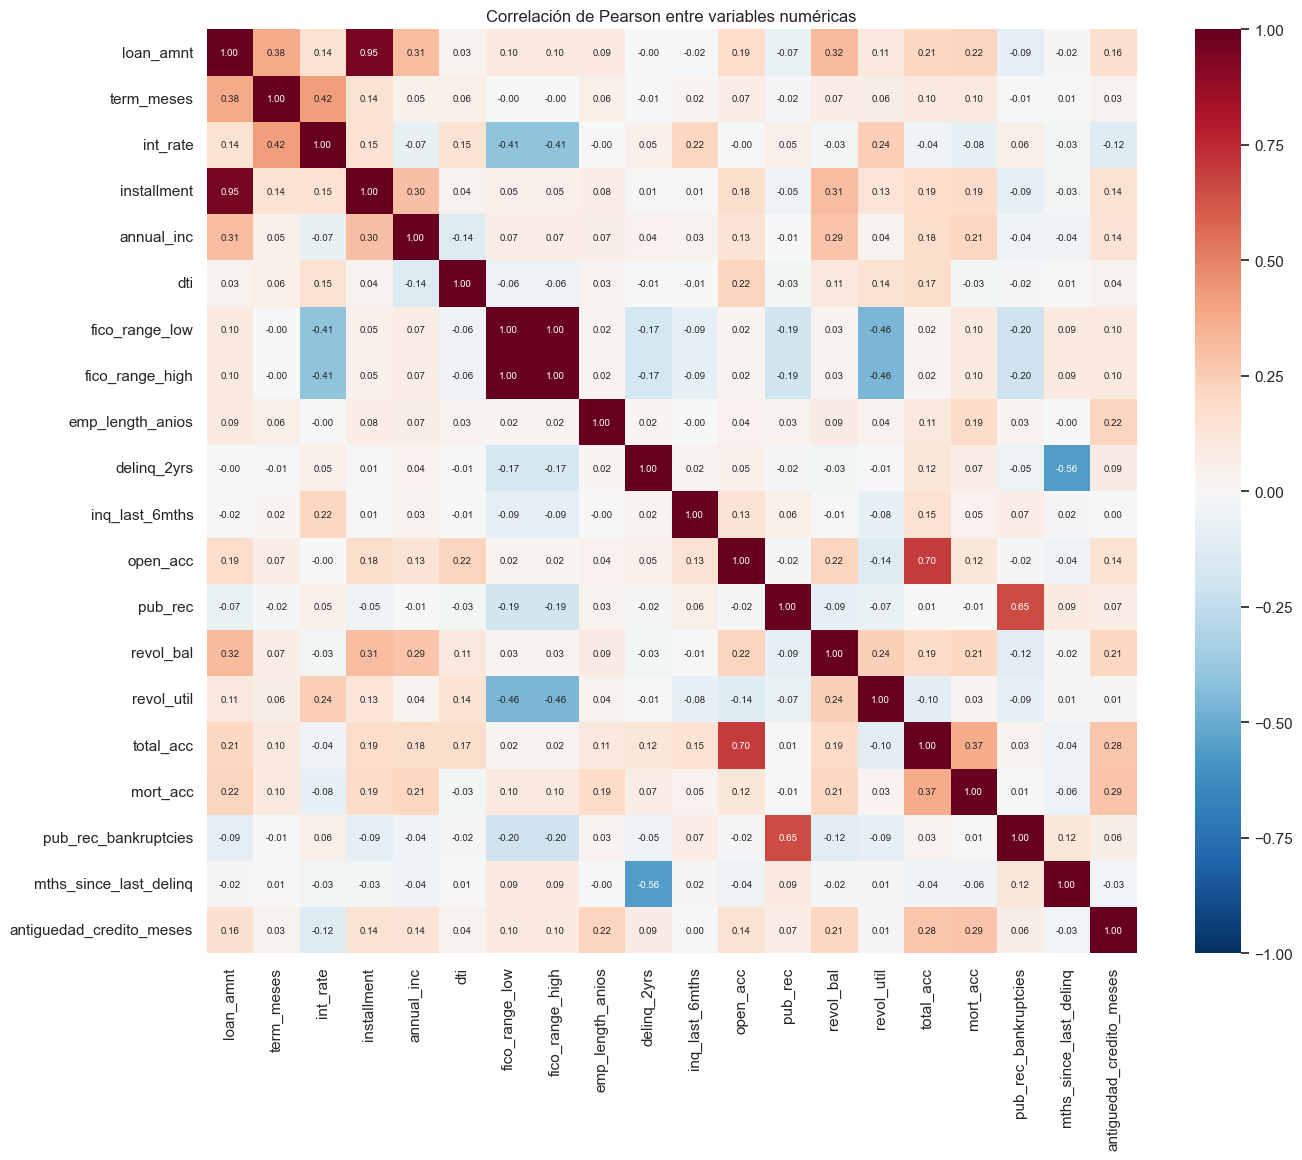

r
fico_range_low  fico_range_high         1.0000
loan_amnt       installment             0.9534
open_acc        total_acc               0.7013
pub_rec         pub_rec_bankruptcies    0.6496
delinq_2yrs     mths_since_last_delinq -0.5560
fico_range_low  revol_util             -0.4600
fico_range_high revol_util             -0.4600
term_meses      int_rate                0.4172
int_rate        fico_range_low         -0.4054
                fico_range_high        -0.4054
loan_amnt       term_meses              0.3809
total_acc       mort_acc                0.3679

In [24]:
corr = df[cfg.NUMERICAS_EDA].corr(method="pearson")  # Matriz de correlación de Pearson
fig, ax = plt.subplots(figsize=(15, 12))  # Figura grande para el mapa de calor
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})  # Mapa de calor
ax.set_title("Correlación de Pearson entre variables numéricas")  # Título
guardar_figura(fig, "01_correlacion")  # Exporta la figura
plt.show()  # Muestra la figura
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()  # Pares únicos (triángulo superior)
pares.reindex(pares.abs().sort_values(ascending=False).index).head(12).to_frame("r")  # Pares más correlacionados

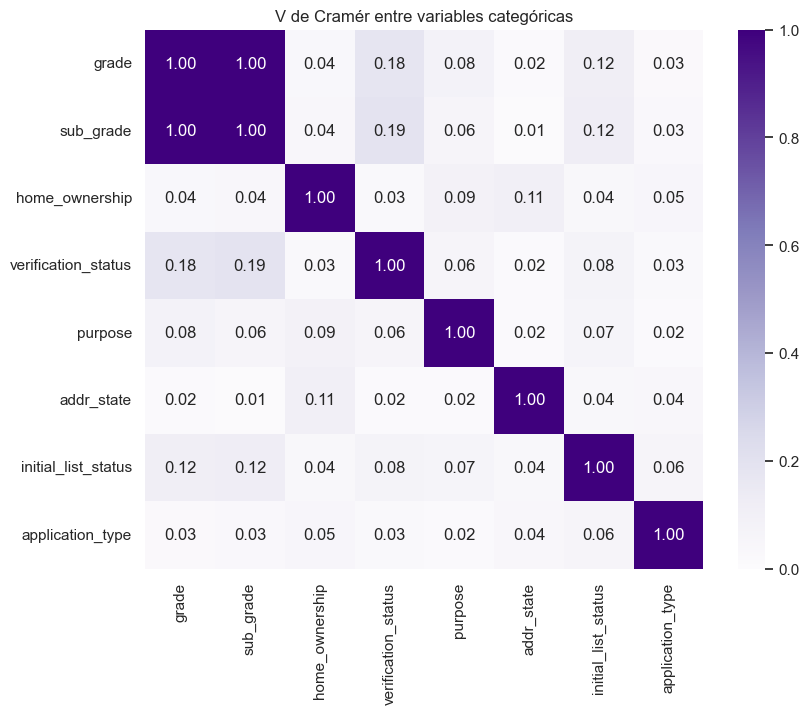

In [25]:
matriz_v = pd.DataFrame(index=cfg.CATEGORICAS_EDA, columns=cfg.CATEGORICAS_EDA, dtype=float)  # Matriz vacía de V de Cramér
for a in cfg.CATEGORICAS_EDA:  # Primera variable del par
    for b in cfg.CATEGORICAS_EDA:  # Segunda variable del par
        matriz_v.loc[a, b] = 1.0 if a == b else v_cramer(df[a].fillna(cfg.CATEGORIA_FALTANTE), df[b].fillna(cfg.CATEGORIA_FALTANTE))  # V de Cramér del par
fig, ax = plt.subplots(figsize=(9, 7))  # Figura para el mapa de calor
sns.heatmap(matriz_v, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=ax)  # Mapa de calor de V de Cramér
ax.set_title("V de Cramér entre variables categóricas")  # Título
guardar_figura(fig, "01_cramer")  # Exporta la figura
plt.show()  # Muestra la figura

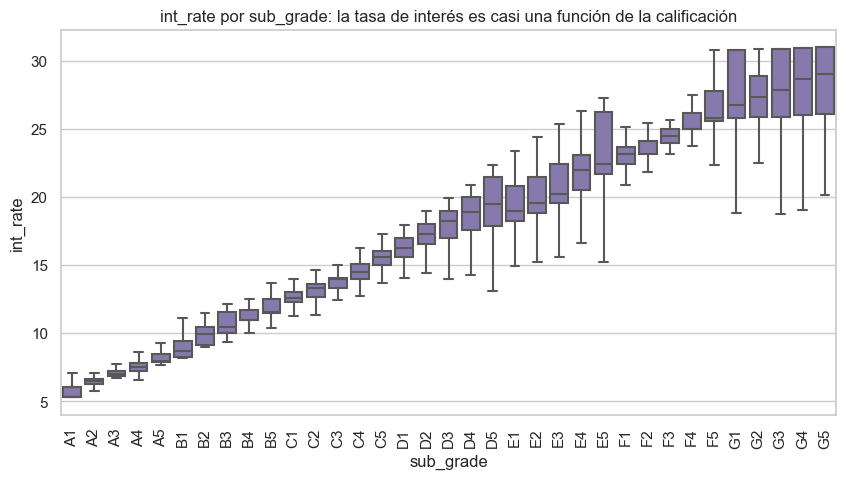

Correlación de Spearman entre fico_range_high e int_rate: -0.416


In [26]:
fig, ax = plt.subplots(figsize=(10, 5))  # Relación entre sub-calificación y tasa de interés
orden = sorted(df["sub_grade"].unique())  # Sub-calificaciones en orden A1…G5
sns.boxplot(data=df, x="sub_grade", y="int_rate", order=orden, showfliers=False, ax=ax, color="#8172B3")  # Tasa de interés por sub-calificación
ax.tick_params(axis="x", rotation=90)  # Rota las etiquetas
ax.set_title("int_rate por sub_grade: la tasa de interés es casi una función de la calificación")  # Título
plt.show()  # Muestra la figura
print("Correlación de Spearman entre fico_range_high e int_rate:", round(stats.spearmanr(df["fico_range_high"], df["int_rate"])[0], 3))  # Redundancia sugerida por el enunciado

**Comentario (multicolinealidad).** Pares con |r| > 0,7: `fico_range_low`–`fico_range_high`
(r = 1,00: el rango siempre mide 4 puntos), `loan_amnt`–`installment` (0,95: la cuota es
función del monto, la tasa y el plazo) y `open_acc`–`total_acc` (0,70, justo en el límite).
Entre categóricas, `grade`–`sub_grade` tiene V ≈ 1 (una determina a la otra) y la tasa de
interés es prácticamente una función de la sub-calificación. La redundancia sugerida por el
enunciado `fico_range_high`–`int_rate` es moderada (ρ = −0,42), no suficiente para excluir.

**Decisión:** se excluyen `fico_range_low`, `installment` y `sub_grade`; se conservan
`open_acc` y `total_acc` (r en el límite y significado distinto) e `int_rate` junto a
`grade` (la tasa aporta variación dentro de cada grado).

### Visualizaciones avanzadas

El *pairplot* y la matriz de dispersión dibujan cada punto, por lo que (como permite el
enunciado) se usa una **muestra aleatoria de 5.000 filas solo para estos dos gráficos**.
Ningún cálculo ni modelo usa la muestra.

C:\Users\user-pc\.conda\envs\ml_venv\lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


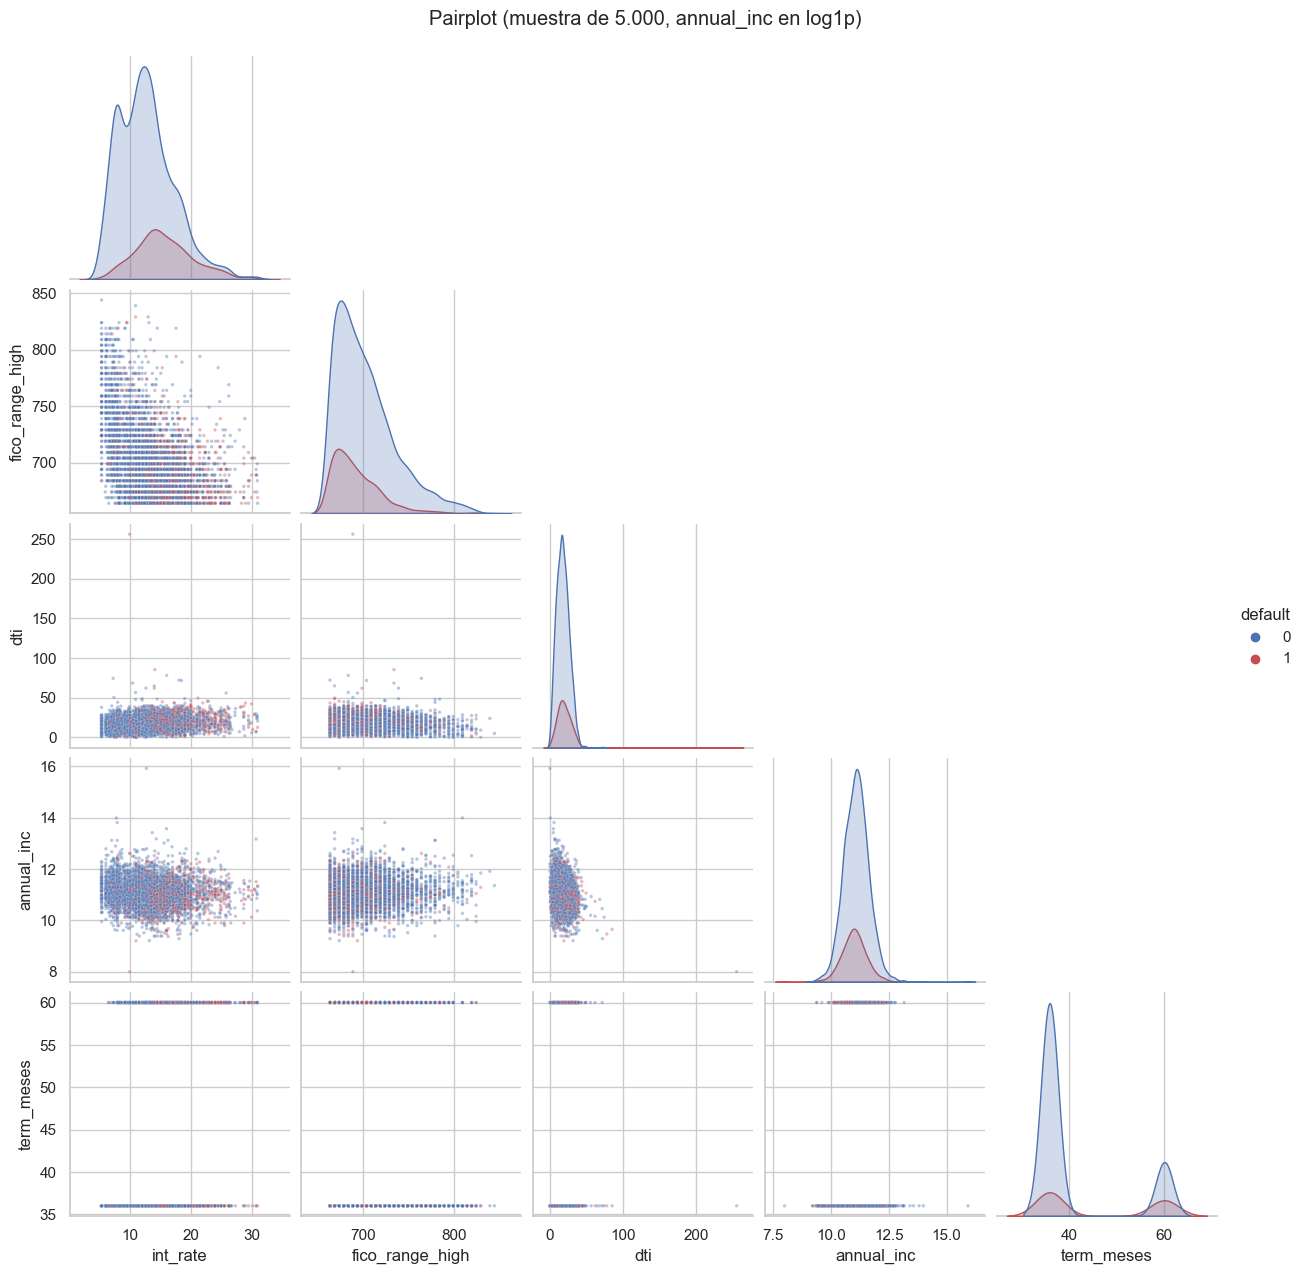

In [27]:
top_vars = ["int_rate", "fico_range_high", "dti", "annual_inc", "term_meses"]  # Variables más relevantes
muestra_viz = df[top_vars + [cfg.COL_TARGET]].dropna().sample(5000, random_state=cfg.SEMILLA)  # Muestra solo para visualización
muestra_viz["annual_inc"] = np.log1p(muestra_viz["annual_inc"])  # Escala logarítmica para el ingreso
g = sns.pairplot(muestra_viz, hue=cfg.COL_TARGET, palette=["#4C72B0", "#C44E52"], plot_kws={"s": 6, "alpha": 0.4}, corner=True)  # Pairplot por clase
g.fig.suptitle("Pairplot (muestra de 5.000, annual_inc en log1p)", y=1.02)  # Título
plt.show()  # Muestra la figura

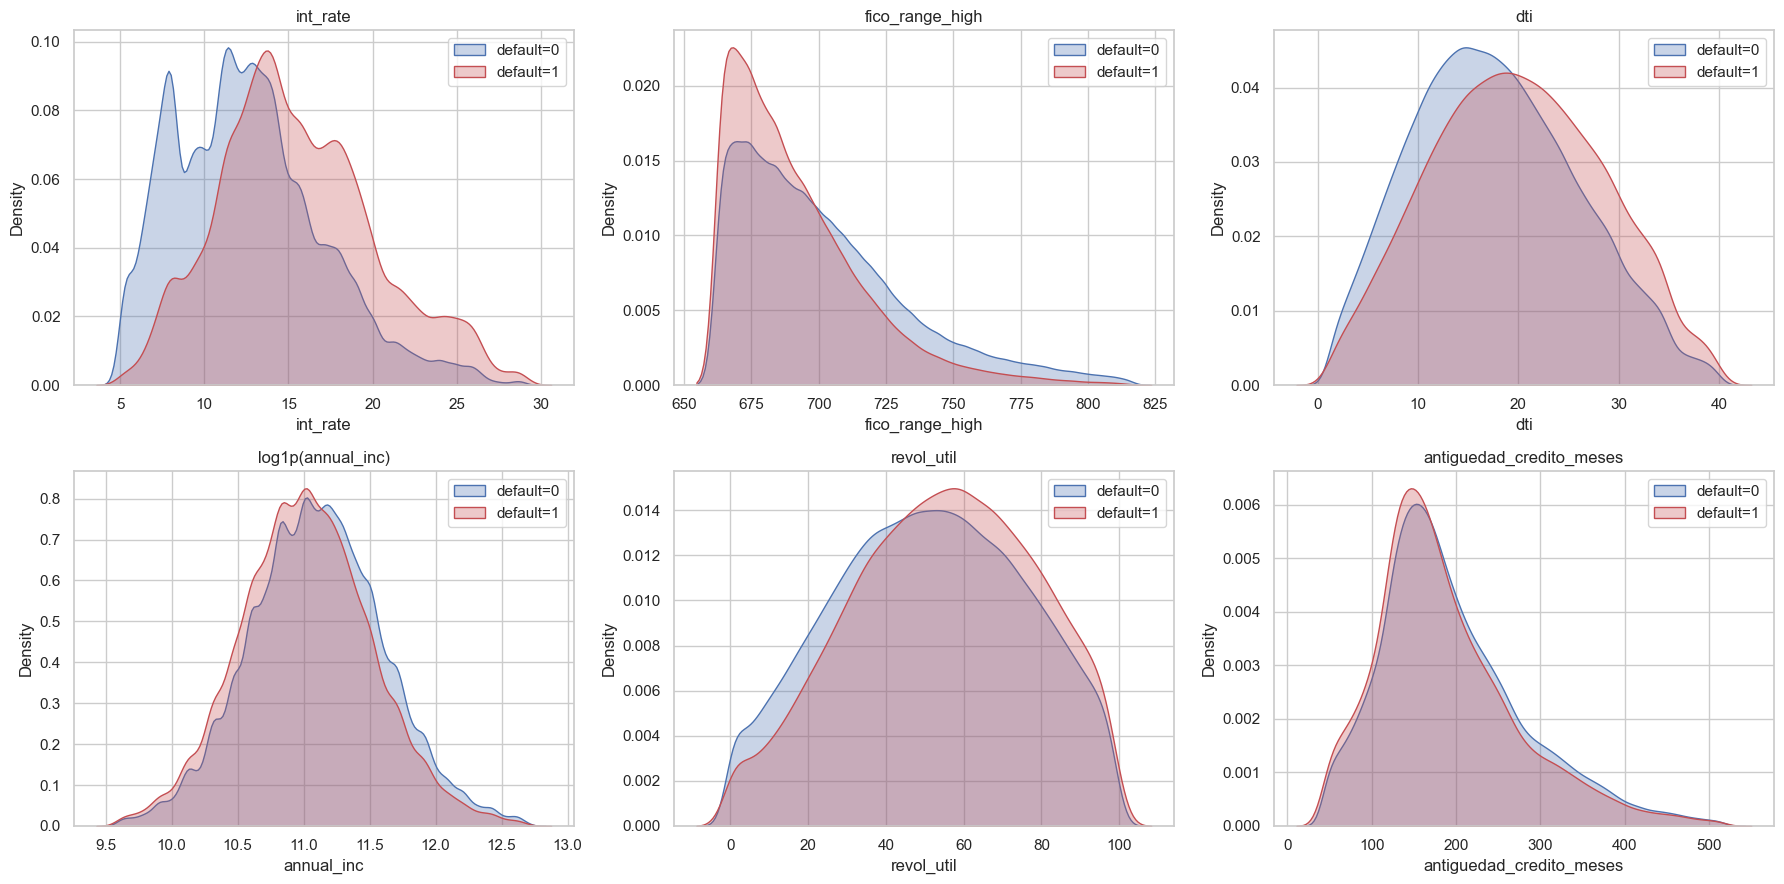

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))  # KDE comparativos por clase (datos completos)
for ax, col in zip(axes.ravel(), ["int_rate", "fico_range_high", "dti", "annual_inc", "revol_util", "antiguedad_credito_meses"]):  # Variables relevantes
    d = df[[col, cfg.COL_TARGET]].dropna()  # Datos sin nulos
    if col == "annual_inc":  # El ingreso se grafica en escala log
        d[col] = np.log1p(d[col])  # Transformación log1p
    d = d[d[col].between(d[col].quantile(0.005), d[col].quantile(0.995))]  # Recorta colas extremas solo para visualizar
    for clase, color in [(0, "#4C72B0"), (1, "#C44E52")]:  # Una curva por clase
        sns.kdeplot(d.loc[d[cfg.COL_TARGET] == clase, col], ax=ax, color=color, fill=True, alpha=0.3, label=f"default={clase}", bw_adjust=1.5)  # Densidad
    ax.set_title(col if col != "annual_inc" else "log1p(annual_inc)")  # Título
    ax.legend()  # Leyenda
fig.tight_layout()  # Ajusta los márgenes
guardar_figura(fig, "01_kde")  # Exporta la figura
plt.show()  # Muestra la figura

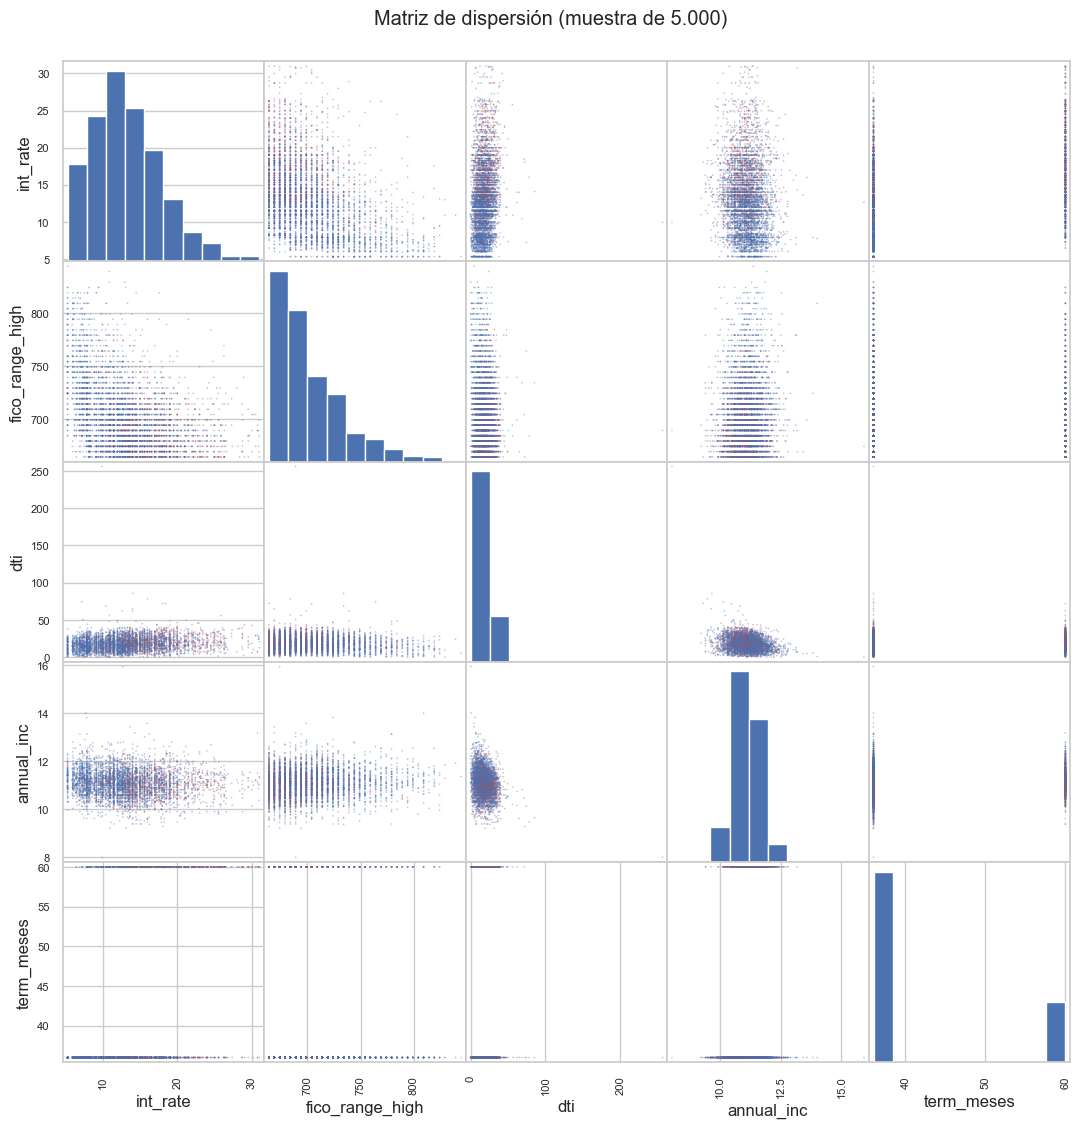

In [29]:
colores = muestra_viz[cfg.COL_TARGET].map({0: "#4C72B0", 1: "#C44E52"})  # Color de cada punto según la clase
pd.plotting.scatter_matrix(muestra_viz[top_vars], c=colores, figsize=(13, 13), s=6, alpha=0.4, diagonal="hist")  # Matriz de dispersión de 5 variables
plt.suptitle("Matriz de dispersión (muestra de 5.000)", y=0.92)  # Título
plt.show()  # Muestra la figura

**Comentario.** Las densidades muestran solapamiento amplio entre clases: ninguna variable
separa por sí sola. Las diferencias más visibles son el desplazamiento de `int_rate` hacia
la derecha y de `fico_range_high` hacia la izquierda en los defaults. En el *pairplot* y la
matriz de dispersión no aparecen fronteras no lineales claras; sí se aprecia la estructura
discreta de `term_meses` y de FICO, y la relación decreciente entre FICO y tasa de interés.

## Valores faltantes (análisis detallado)

In [30]:
print(f"Columnas sin nulos: {(nulos_todas['pct_nulos'] == 0).sum()} | con nulos: {(nulos_todas['pct_nulos'] > 0).sum()} | "
      f"> 30 %: {(nulos_todas['pct_nulos'] > 30).sum()} | > 70 %: {(nulos_todas['pct_nulos'] > 70).sum()}")  # Resumen de las 151 columnas
nulos_todas.head(40)  # Las 40 columnas con más nulos

Columnas sin nulos: 46 | con nulos: 105 | > 30 %: 58 | > 70 %: 42


,n_nulos,pct_nulos
next_pymnt_d,1345310,100.0000
member_id,1345310,100.0000
orig_projected_additional_accrued_interest,1341551,99.7206
hardship_start_date,1339556,99.5723
hardship_length,1339556,99.5723
hardship_type,1339556,99.5723
hardship_reason,1339556,99.5723
hardship_status,1339556,99.5723
deferral_term,1339556,99.5723
hardship_amount,1339556,99.5723


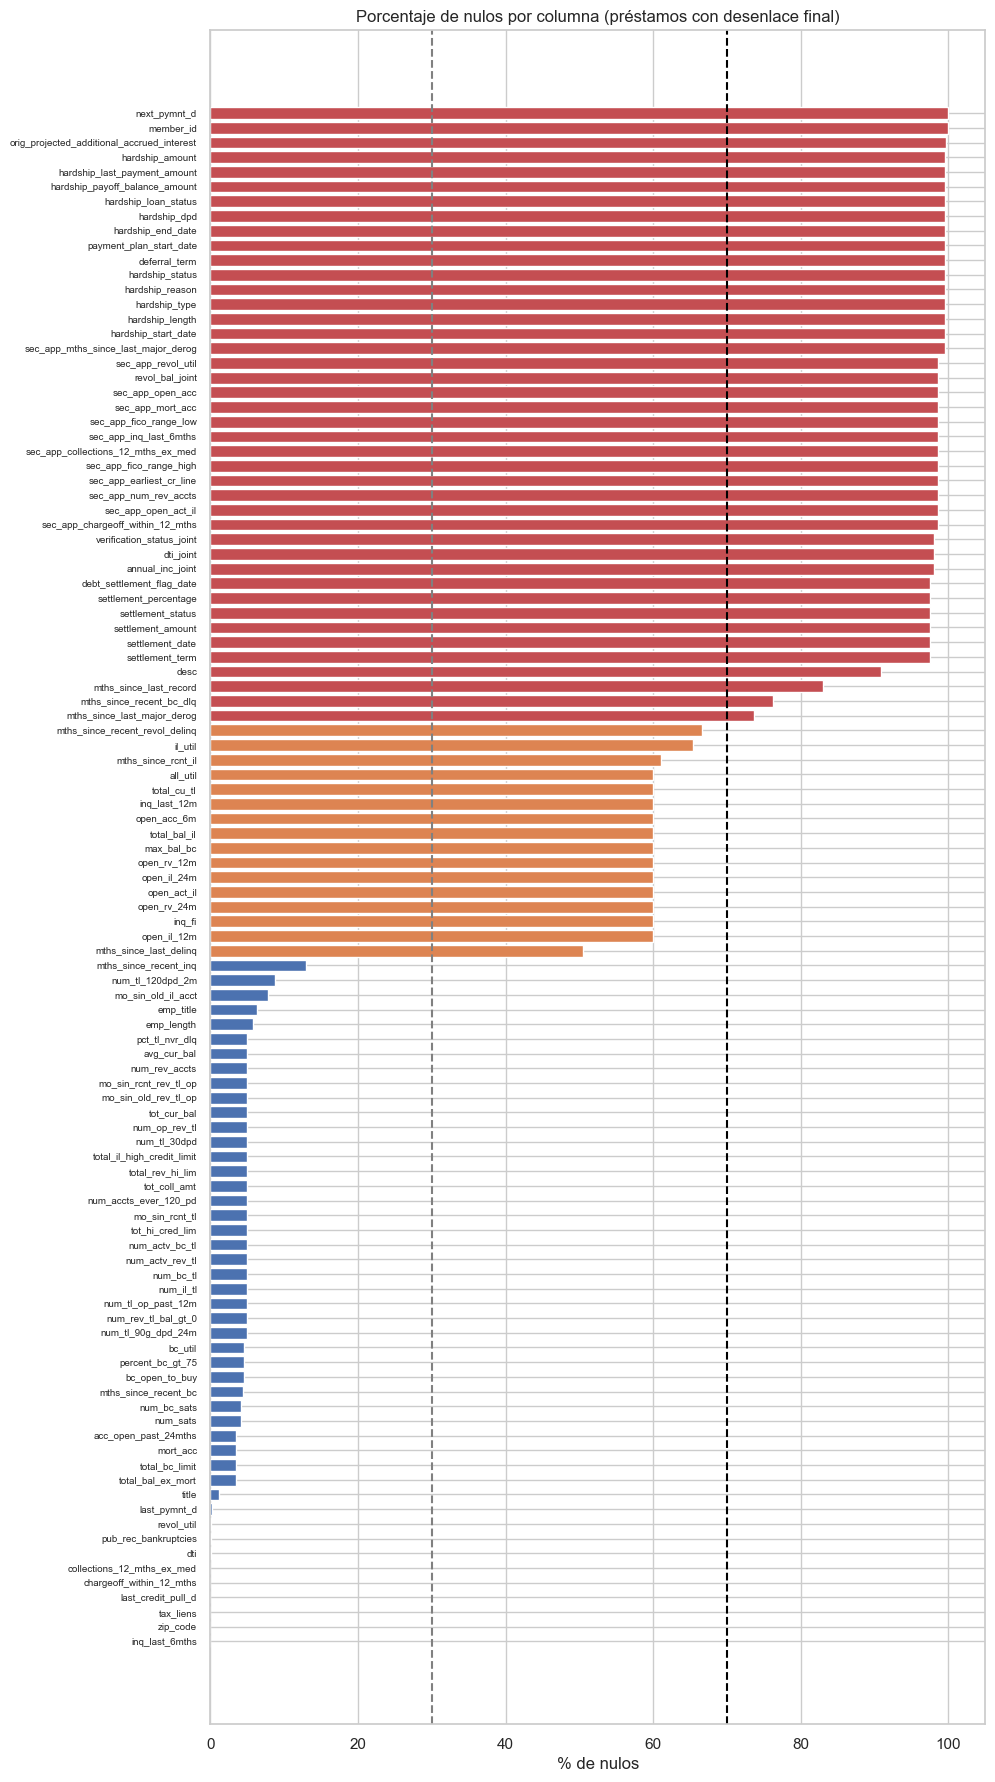

In [31]:
fig, ax = plt.subplots(figsize=(10, 22))  # Figura alta para las columnas con nulos
d = nulos_todas.loc[nulos_todas["pct_nulos"] > 0, "pct_nulos"].sort_values()  # Columnas con nulos
ax.barh(d.index, d.values, color=["#C44E52" if v > 70 else "#DD8452" if v > 30 else "#4C72B0" for v in d.values])  # Barras por severidad
ax.axvline(30, color="gray", ls="--"); ax.axvline(70, color="black", ls="--")  # Umbrales 30 % y 70 %
ax.set_xlabel("% de nulos"); ax.tick_params(axis="y", labelsize=7)  # Etiquetas
ax.set_title("Porcentaje de nulos por columna (préstamos con desenlace final)")  # Título
guardar_figura(fig, "01_nulos_columnas")  # Exporta la figura
plt.show()  # Muestra la figura

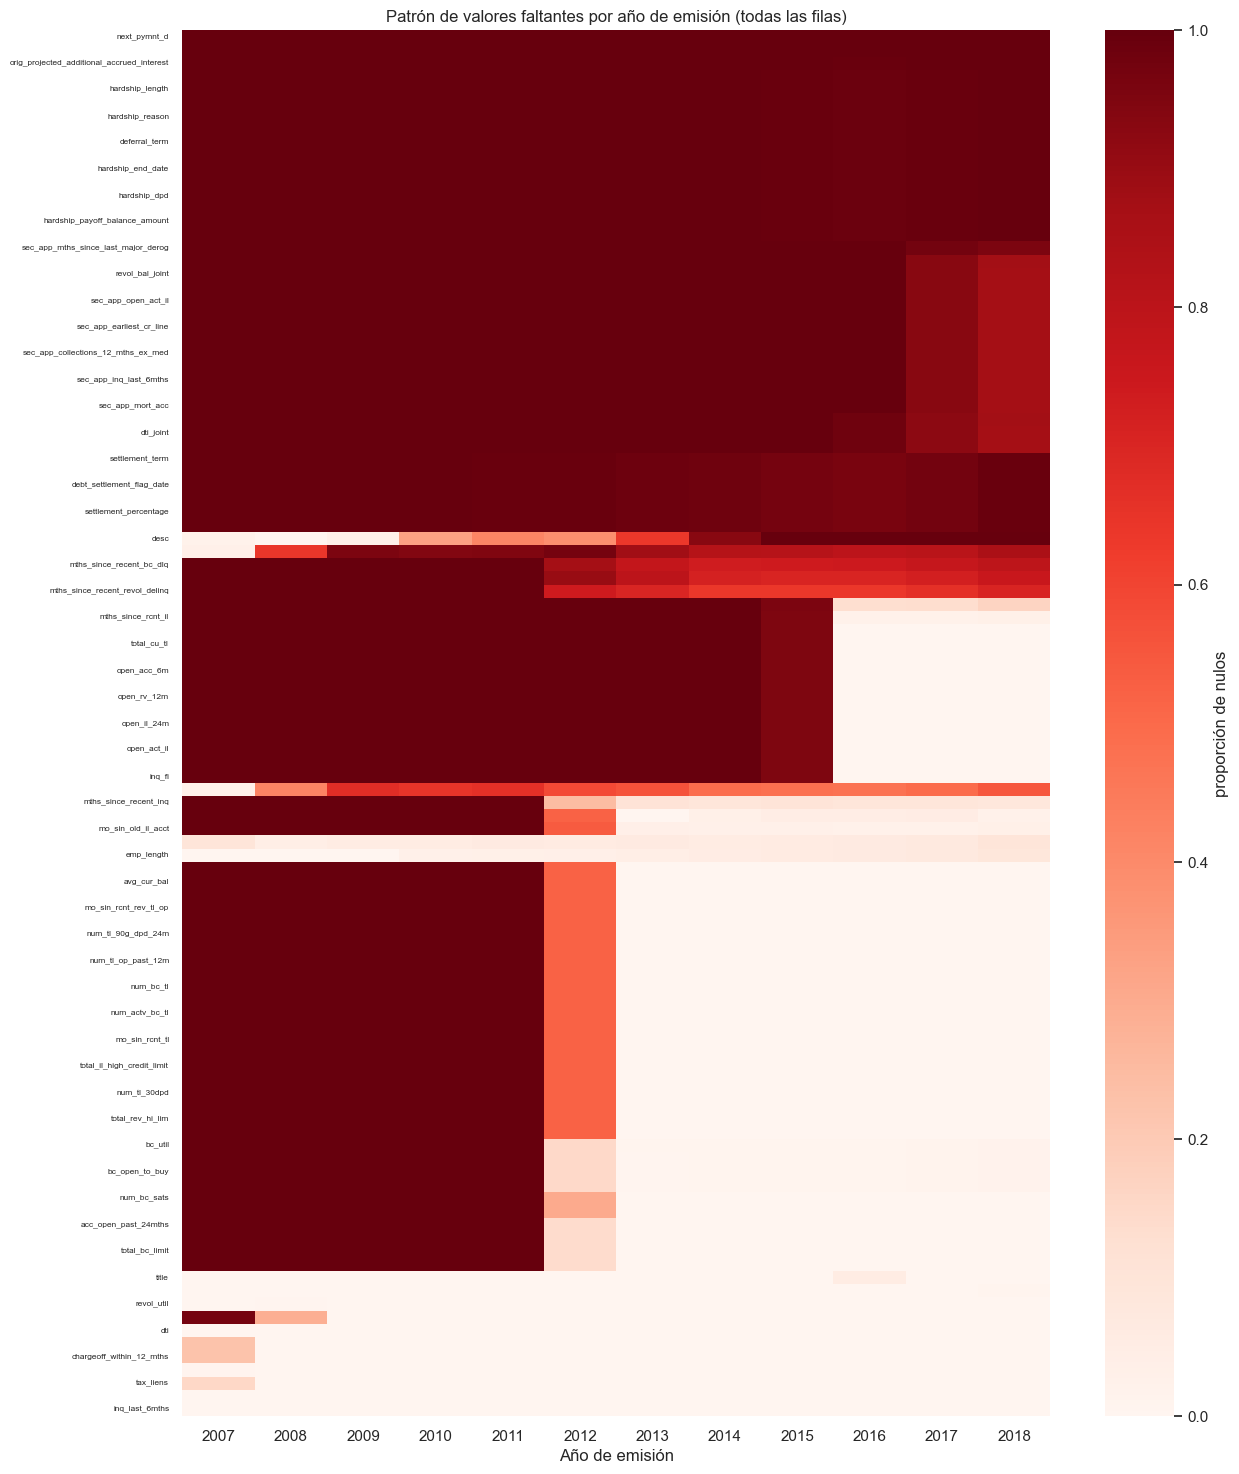

In [32]:
fig, ax = plt.subplots(figsize=(14, 18))  # Mapa de calor del patrón de nulos a lo largo del tiempo
sns.heatmap(nulos_por_anio.T, cmap="Reds", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "proporción de nulos"})  # Filas = columnas, columnas = año
ax.set_xlabel("Año de emisión"); ax.tick_params(axis="y", labelsize=6)  # Etiquetas
ax.set_title("Patrón de valores faltantes por año de emisión (todas las filas)")  # Título
guardar_figura(fig, "01_nulos_por_anio")  # Exporta la figura
plt.show()  # Muestra la figura

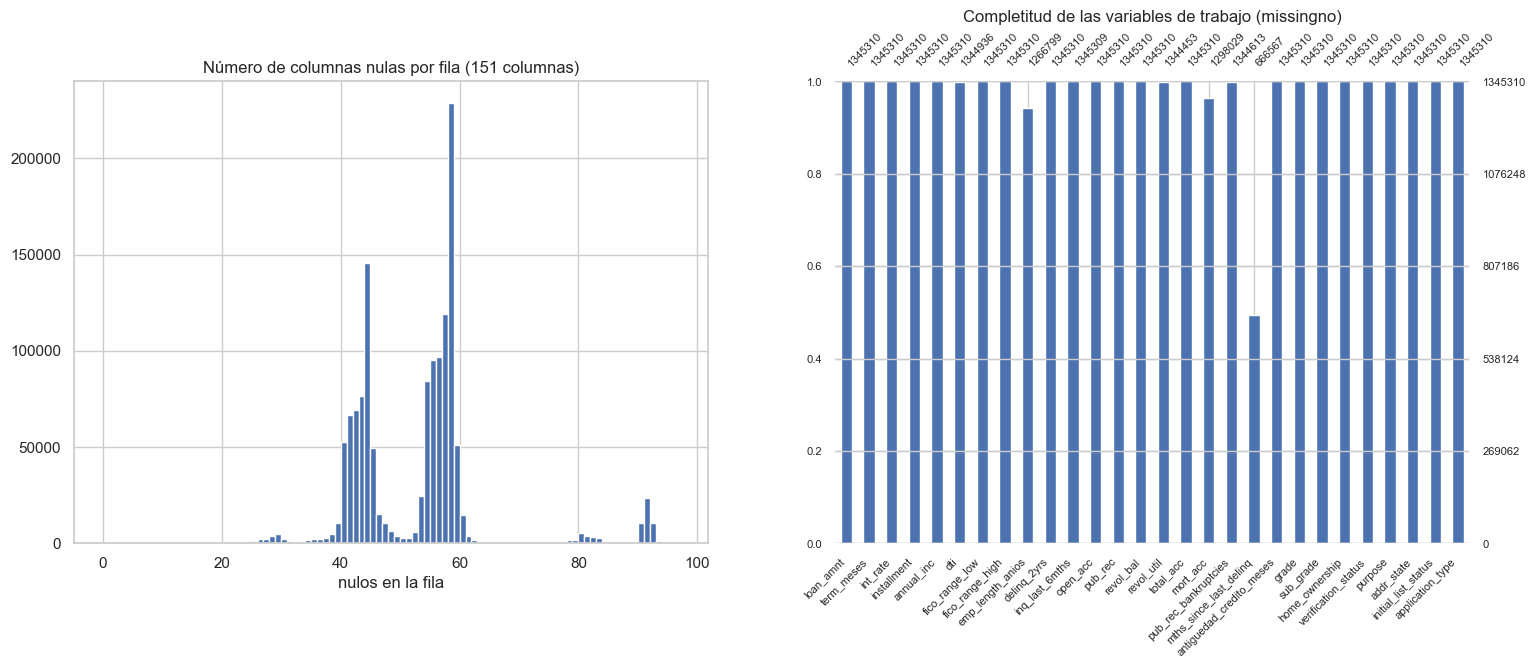

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))  # Concentración de nulos por fila + missingno
axes[0].hist(nulos_por_fila, bins=range(0, int(nulos_por_fila.max()) + 2), color="#4C72B0")  # Número de nulos por fila
axes[0].set_title("Número de columnas nulas por fila (151 columnas)"); axes[0].set_xlabel("nulos en la fila")  # Títulos
msno.bar(df[cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA], ax=axes[1], fontsize=8, color="#4C72B0")  # Completitud de las variables de trabajo
axes[1].set_title("Completitud de las variables de trabajo (missingno)")  # Título
plt.show()  # Muestra la figura

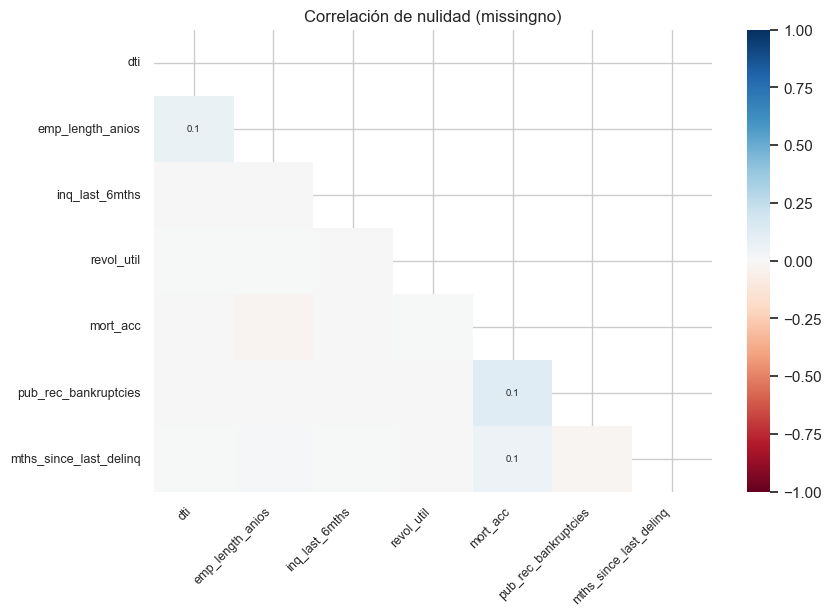

In [34]:
con_nulos = [c for c in cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA if df[c].isna().any()]  # Variables de trabajo con algún nulo
msno.heatmap(df[con_nulos], figsize=(9, 6), fontsize=9)  # Correlación de nulidad entre variables (datos completos)
plt.title("Correlación de nulidad (missingno)")  # Título
plt.show()  # Muestra la figura

In [35]:
mcar_todas["relacion_con_default"] = np.where(mcar_todas["p_valor"] < cfg.ALFA, "NO MCAR (p < 0.05)", "compatible con MCAR")  # Interpretación
mcar_trabajo = mcar_todas.reindex([c for c in ["emp_length", "mths_since_last_delinq", "mort_acc", "revol_util", "dti", "pub_rec_bankruptcies", "earliest_cr_line", "inq_last_6mths"] if c in mcar_todas.index])  # Columnas de trabajo con nulos
display(mcar_trabajo)  # Prueba sobre las variables de trabajo
print("Resumen sobre las", len(mcar_todas), "columnas con nulos parciales:")  # Resumen general
mcar_todas["relacion_con_default"].value_counts()  # Cuántas columnas muestran nulos relacionados con el target

,pct_nulos,tasa_default_si_nulo,tasa_default_si_presente,chi2,p_valor,relacion_con_default
columna,,,,,,
emp_length,5.8359,0.2691,0.1953,"2,520.7329",0.0000,NO MCAR (p < 0.05)
mths_since_last_delinq,50.4525,0.1926,0.2068,420.3151,0.0000,NO MCAR (p < 0.05)
mort_acc,3.5145,0.1456,0.2016,893.5316,0.0000,NO MCAR (p < 0.05)
revol_util,0.0637,0.2100,0.1996,0.5181,0.4716,compatible con MCAR
dti,0.0278,0.1898,0.1996,0.1672,0.6826,compatible con MCAR
pub_rec_bankruptcies,0.0518,0.1693,0.1996,3.8272,0.0504,compatible con MCAR
inq_last_6mths,0.0001,0.0000,0.1996,0.0000,1.0000,compatible con MCAR


Resumen sobre las 103 columnas con nulos parciales:


relacion_con_default
NO MCAR (p < 0.05)     95
compatible con MCAR     8
Name: count, dtype: int64

La prueba anterior contrasta, para cada columna, si **estar nulo** es independiente del
target (chi-cuadrado sobre la tabla 2×2 nulo × default). Un valor p < 0.05 indica que
los nulos **no son completamente al azar (no MCAR)**: su presencia aporta información sobre
el riesgo. Con 1,3 millones de filas casi cualquier diferencia resulta significativa, por lo
que también se reporta la magnitud (tasa de default con y sin dato).

In [36]:
plan = pd.DataFrame({  # Plan de tratamiento de nulos para las variables de trabajo
    "pct_nulos": [100 * df[c].isna().mean() for c in cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA],  # % de nulos
}, index=cfg.NUMERICAS_EDA + cfg.CATEGORICAS_EDA)  # Índice = variables
plan = plan[plan["pct_nulos"] > 0].sort_values("pct_nulos", ascending=False)  # Solo las que tienen nulos
plan["tratamiento"] = [  # Regla de tratamiento por variable
    "Indicador de nulo + imputación con mediana de train (nulo = sin morosidad registrada)" if c == "mths_since_last_delinq"  # Caso no MCAR con 30–70 % de nulos
    else "Indicador de nulo + imputación con mediana de train (nulos no MCAR)" if c in cfg.VARIABLES_CON_INDICADOR  # Pocos nulos pero informativos
    else "Imputación con mediana de train" if c in cfg.NUMERICAS_EDA  # Numéricas con pocos nulos
    else "Categoría 'DESCONOCIDO'"  # Categóricas
    for c in plan.index]  # Recorre cada variable
plan  # Muestra el plan

,pct_nulos,tratamiento
mths_since_last_delinq,50.4525,Indicador de nulo + imputación con mediana de ...
emp_length_anios,5.8359,Indicador de nulo + imputación con mediana de ...
mort_acc,3.5145,Indicador de nulo + imputación con mediana de ...
revol_util,0.0637,Imputación con mediana de train
pub_rec_bankruptcies,0.0518,Imputación con mediana de train
dti,0.0278,Imputación con mediana de train
inq_last_6mths,0.0001,Imputación con mediana de train


Para las 151 columnas originales el criterio es: **> 70 % de nulos → eliminar**; 30–70 % →
imputación avanzada o indicador; < 30 % → mediana/moda o categoría "DESCONOCIDO". Además,
se excluyen **por fuga de información** todas las variables registradas después de la
originación (pagos, recuperaciones, `last_*`, `hardship_*`, `settlement_*`, `out_prncp`, etc.),
porque solo se conocen cuando el préstamo ya está en curso o terminado.

**Comentario (faltantes).** De las 151 columnas, 46 no tienen nulos, 58 superan el 30 % y
42 el 70 % (datos de co-solicitante, *hardship*, *settlement*, `desc`, `member_id` al 100 %).
El mapa por año muestra que los nulos son **sistemáticos por época**: muchas variables de
buró (`open_acc_6m`, `il_util`, `mths_since_rcnt_il`…) solo existen desde finales de 2015
(95 % nulos en 2015, ≈ 0 % desde 2016), las de co-solicitante aparecen desde 2016 (solicitudes
conjuntas) y `mort_acc` falta en todos los préstamos anteriores a 2012. Es decir,
los nulos se concentran en columnas y periodos, no en filas aisladas. En 95 de las 103
columnas con nulos parciales la probabilidad de faltar está relacionada con el default
(**no MCAR**). Entre las variables de trabajo: sin `emp_length` el default sube a 26,9 %
(vs 19,5 %), sin `mort_acc` baja a 14,6 % (préstamos antiguos) y sin
`mths_since_last_delinq` es 19,3 % (vs 20,7 %). Por eso esas tres reciben un **indicador de
nulo** además de la imputación con la mediana de train.

## 2.5 Resumen ejecutivo del EDA

| Aspecto | Hallazgo | Decisión para el preprocesamiento |
|---|---|---|
| Tamaño y target | 2.260.701 filas; 1.345.310 con desenlace final; 20,0 % default (4:1) | Filtrar a `Fully Paid`/`Charged Off`; partición 80/20 estratificada; AUC como criterio; umbral optimizado en train |
| Calidad | `id` sin duplicados; 2 filas de totales al final; valores implausibles (`dti` = 999, `revol_util` = 892) | Se conservan todas las filas (sin muestreo ni eliminación); escalado estándar |
| Asimetría | Ninguna variable normal; `annual_inc` y `revol_bal` extremadamente asimétricas | `log1p` en ambas |
| Predictores más prometedores | `grade`/`int_rate`, `term`, FICO, `dti`, `verification_status`, `home_ownership`, `purpose`, `revol_util`, `inq_last_6mths`, `mort_acc` | Se incluyen todas las variables conocidas al originar el préstamo (17 numéricas + 7 categóricas) |
| Multicolinealidad | FICO bajo/alto (r = 1), monto/cuota (0,95), `grade`/`sub_grade` (V ≈ 1) | Excluir `fico_range_low`, `installment`, `sub_grade` |
| Categorías raras | < 1 % en `grade`, `home_ownership`, `purpose`, `addr_state` | Agrupar en `OTROS` (aprendido en train) |
| Faltantes | 42 columnas > 70 %; nulos por época; `mths_since_last_delinq` 50 %; nulos no MCAR | Eliminar columnas > 70 % y de fuga; indicador + mediana en 3 variables |
| Fuga de información | Pagos, recuperaciones, `last_*`, *hardship*, *settlement* | Excluidas |
| Balanceo | Desbalance moderado | Sin remuestreo; métricas y umbral adecuados |

---

# 2. Partición común y preprocesamiento con scikit-learn

Secciones 3.1 y 3.2 del enunciado.

* La partición 80/20 estratificada se define **una sola vez** (semilla 42) y se guarda en
  `data/particion_train_test.parquet` con las columnas `id` y `split`. PySpark leerá
  exactamente ese archivo (no se usa `randomSplit`).
* Todos los transformadores que aprenden parámetros (imputador, escalador, codificador y la
  agrupación de categorías raras) se ajustan **solo con train** y luego se aplican a test.
* El tiempo total de preprocesamiento (lectura + construcción de variables + partición +
  transformación) se mide para compararlo con PySpark.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import json  # Escritura de metadatos
import joblib  # Serialización de los transformadores ajustados
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
from sklearn.impute import SimpleImputer  # Imputación de nulos
from sklearn.model_selection import train_test_split  # Partición estratificada
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # Codificación y escalado
from src import config as cfg  # Configuración central
from src import preparacion as prep  # Construcción de variables con pandas
from src.utilidades import actualizar_json, cronometro, info_hardware  # Utilidades

tiempos = {}  # Diccionario donde se acumulan los tiempos de cada etapa
print(info_hardware())  # Hardware utilizado

{'sistema': 'Windows 10', 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD', 'nucleos_fisicos': 6, 'nucleos_logicos': 12, 'ram_total_gb': 13.8, 'ram_disponible_gb': 7.3, 'python': '3.9.25'}


## Lectura y construcción de variables

Se leen del CSV completo (todas las filas) solo las columnas necesarias.

In [2]:
with cronometro(tiempos, "lectura_csv"):  # Mide el tiempo de lectura
    df_raw = pd.read_csv(cfg.RUTA_CSV, usecols=prep.COLUMNAS_ORIGINALES, low_memory=False)  # Lee todas las filas del CSV
with cronometro(tiempos, "construccion_variables"):  # Mide el tiempo de construcción de variables
    df = prep.construir_variables(df_raw).drop(columns=["issue_d"])  # Filtra estados finales y deriva variables
del df_raw  # Libera memoria
df.to_parquet(cfg.RUTA_MODELADO, index=False)  # Guarda el dataset de trabajo en el espacio original (lo usa LIME)
print(df.shape, tiempos)  # Dimensión y tiempos parciales
df.head()  # Primeras filas

(1345310, 30) {'lectura_csv': 21.665446043014526, 'construccion_variables': 2.339240074157715}


,id,loan_amnt,term_meses,int_rate,installment,annual_inc,dti,fico_range_low,fico_range_high,emp_length_anios,...,antiguedad_credito_meses,grade,sub_grade,home_ownership,verification_status,purpose,addr_state,initial_list_status,application_type,default
0,68407277,3600.0,36.0,13.99,123.03,55000.0,5.91,675.0,679.0,10.0,...,148.0,C,C4,MORTGAGE,Not Verified,debt_consolidation,PA,w,Individual,0
1,68355089,24700.0,36.0,11.99,820.28,65000.0,16.06,715.0,719.0,10.0,...,192.0,C,C1,MORTGAGE,Not Verified,small_business,SD,w,Individual,0
2,68341763,20000.0,60.0,10.78,432.66,63000.0,10.78,695.0,699.0,10.0,...,184.0,B,B4,MORTGAGE,Not Verified,home_improvement,IL,w,Joint App,0
3,68476807,10400.0,60.0,22.45,289.91,104433.0,25.37,695.0,699.0,3.0,...,210.0,F,F1,MORTGAGE,Source Verified,major_purchase,PA,w,Individual,0
4,68426831,11950.0,36.0,13.44,405.18,34000.0,10.20,690.0,694.0,4.0,...,338.0,C,C3,RENT,Source Verified,debt_consolidation,GA,w,Individual,0


## 3.1 Partición común 80/20 estratificada

In [3]:
with cronometro(tiempos, "particion"):  # Mide el tiempo de la partición
    ids_train, ids_test = train_test_split(  # Divide los identificadores
        df[cfg.COL_ID],  # Identificador único de cada préstamo
        test_size=cfg.PROPORCION_TEST,  # 20 % para prueba
        stratify=df[cfg.COL_TARGET],  # Estratifica por clase
        random_state=cfg.SEMILLA,  # Semilla fija
    )
    particion = pd.DataFrame({cfg.COL_ID: df[cfg.COL_ID]})  # Tabla con todos los id
    particion["split"] = np.where(particion[cfg.COL_ID].isin(set(ids_test)), "test", "train")  # Asigna train o test
    particion.to_parquet(cfg.RUTA_PARTICION, index=False)  # Guarda la asignación en Parquet
resumen = particion.merge(df[[cfg.COL_ID, cfg.COL_TARGET]], on=cfg.COL_ID).groupby("split")[cfg.COL_TARGET].agg(["count", "mean"])  # Tamaño y tasa de default por conjunto
resumen.columns = ["n", "tasa_default"]  # Nombres descriptivos
resumen  # Muestra que la estratificación conserva la proporción de clases

,n,tasa_default
split,,
test,269062,0.199627
train,1076248,0.199626


In [4]:
es_test = df[cfg.COL_ID].isin(set(ids_test)).to_numpy()  # Máscara de filas de test
train = df.loc[~es_test].reset_index(drop=True)  # Conjunto de entrenamiento
test = df.loc[es_test].reset_index(drop=True)  # Conjunto de prueba
print(f"train: {len(train):,}  test: {len(test):,}")  # Tamaños

train: 1,076,248  test: 269,062


## 3.2 Preprocesamiento (ajustado solo con train)

1. Transformaciones deterministas: `log1p` en `annual_inc` y `revol_bal` (asimetría muy alta)
   e indicadores de nulo de `mths_since_last_delinq`, `emp_length_anios` y `mort_acc` (nulos no MCAR, ver EDA).
2. Categóricas: nulos → `DESCONOCIDO`; categorías con < 1 % en train → `OTROS`; `OneHotEncoder`.
3. Numéricas: imputación con la mediana de train y `StandardScaler` (necesario para la
   regresión logística y LinearSVC; los árboles son invariantes a esta transformación).

Se excluyen `fico_range_low`, `installment` y `sub_grade` por multicolinealidad (EDA).

In [5]:
with cronometro(tiempos, "ajuste_y_transformacion"):  # Mide el tiempo de ajuste y transformación
    frecuentes = prep.categorias_frecuentes(train, cfg.CATEGORICAS_MODELO)  # Categorías frecuentes aprendidas en train
    train_t = prep.transformar_numericas(prep.agrupar_categorias(train, frecuentes))  # Aplica reglas a train
    test_t = prep.transformar_numericas(prep.agrupar_categorias(test, frecuentes))  # Aplica las mismas reglas a test
    numericas = cfg.NUMERICAS_MODELO + cfg.INDICADORES_NULO  # Columnas numéricas finales (incluye indicadores de nulo)
    imputador = SimpleImputer(strategy="median").fit(train_t[numericas])  # Aprende la mediana de cada numérica en train
    escalador = StandardScaler().fit(imputador.transform(train_t[numericas]))  # Aprende media y desviación en train
    codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32).fit(train_t[cfg.CATEGORICAS_MODELO])  # Aprende las categorías en train

    def transformar(d):  # Aplica los transformadores ajustados a un conjunto
        num = escalador.transform(imputador.transform(d[numericas])).astype(np.float32)  # Imputa y escala las numéricas
        cat = codificador.transform(d[cfg.CATEGORICAS_MODELO])  # Codifica las categóricas
        return np.hstack([num, cat])  # Une ambas partes en una matriz densa

    X_train = transformar(train_t)  # Matriz de entrenamiento
    X_test = transformar(test_t)  # Matriz de prueba
nombres = numericas + codificador.get_feature_names_out(cfg.CATEGORICAS_MODELO).tolist()  # Nombres de las columnas finales
print("X_train:", X_train.shape, " X_test:", X_test.shape)  # Dimensiones
print("Categorías conservadas:", json.dumps(frecuentes, ensure_ascii=False)[:1500])  # Categorías tras agrupar raras
tiempos  # Tiempos de cada etapa

X_train: (1076248, 77)  X_test: (269062, 77)
Categorías conservadas: {"grade": ["A", "B", "C", "D", "E", "F"], "home_ownership": ["MORTGAGE", "OWN", "RENT"], "verification_status": ["Not Verified", "Source Verified", "Verified"], "purpose": ["car", "credit_card", "debt_consolidation", "home_improvement", "major_purchase", "medical", "other", "small_business"], "addr_state": ["AL", "AZ", "CA", "CO", "CT", "FL", "GA", "IL", "IN", "LA", "MA", "MD", "MI", "MN", "MO", "NC", "NJ", "NV", "NY", "OH", "OR", "PA", "SC", "TN", "TX", "VA", "WA", "WI"], "initial_list_status": ["f", "w"], "application_type": ["Individual", "Joint App"]}


{'lectura_csv': 21.665446043014526,
 'construccion_variables': 2.339240074157715,
 'particion': 0.5838937759399414,
 'ajuste_y_transformacion': 4.716569900512695}

In [6]:
pd.DataFrame(X_train[:5], columns=nombres)  # Vista de las primeras filas ya transformadas

,loan_amnt,term_meses,int_rate,annual_inc,dti,fico_range_high,emp_length_anios,delinq_2yrs,inq_last_6mths,open_acc,...,addr_state_SC,addr_state_TN,addr_state_TX,addr_state_VA,addr_state_WA,addr_state_WI,initial_list_status_f,initial_list_status_w,application_type_Individual,application_type_Joint App
0,-1.241053,-0.563901,0.156822,-0.292642,-1.092169,-0.664946,1.126204,-0.361833,0.367422,-0.838320,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0.639861,1.773359,-0.515998,-0.054400,-0.662392,-0.037437,1.126204,-0.361833,-0.698334,-1.020825,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,-0.283393,-0.563901,0.041541,-1.136426,-0.713577,-0.194314,-0.549122,-0.361833,-0.698334,-1.203329,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3,0.639861,-0.563901,-0.853456,1.787357,-0.319099,-0.508069,1.126204,-0.361833,-0.698334,0.074202,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,0.639861,-0.563901,-0.995985,0.471055,-0.059644,0.276318,1.126204,0.776533,-0.698334,-0.655816,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [7]:
pd.DataFrame({"media_train": X_train[:, :len(numericas)].mean(axis=0), "desv_train": X_train[:, :len(numericas)].std(axis=0),  # Verifica que train quede estandarizado
              "media_test": X_test[:, :len(numericas)].mean(axis=0)}, index=numericas)  # En test la media es ≈ 0 pero no exacta (no hay fuga)

,media_train,desv_train,media_test
loan_amnt,7.921913e-06,0.999943,-0.000559
term_meses,2.709119e-05,0.997800,-0.000083
int_rate,3.164150e-05,0.999747,-0.002307
annual_inc,1.627299e-06,0.999656,-0.000004
dti,-1.962163e-08,0.999688,-0.001487
fico_range_high,1.558067e-05,1.000371,-0.001259
emp_length_anios,-3.991100e-06,0.998668,0.001733
delinq_2yrs,-1.366328e-04,0.998681,-0.000323
inq_last_6mths,-2.800880e-04,1.001737,-0.000885
open_acc,8.545276e-06,0.999256,0.000091


## Guardado de los datos preprocesados

In [8]:
np.save(cfg.DIR_SKLEARN_PREP / "X_train.npy", X_train)  # Matriz de entrenamiento
np.save(cfg.DIR_SKLEARN_PREP / "X_test.npy", X_test)  # Matriz de prueba
np.save(cfg.DIR_SKLEARN_PREP / "y_train.npy", train[cfg.COL_TARGET].to_numpy())  # Etiquetas de entrenamiento
np.save(cfg.DIR_SKLEARN_PREP / "y_test.npy", test[cfg.COL_TARGET].to_numpy())  # Etiquetas de prueba
np.save(cfg.DIR_SKLEARN_PREP / "id_train.npy", train[cfg.COL_ID].to_numpy())  # Identificadores de entrenamiento
np.save(cfg.DIR_SKLEARN_PREP / "id_test.npy", test[cfg.COL_ID].to_numpy())  # Identificadores de prueba
joblib.dump({"frecuentes": frecuentes, "imputador": imputador, "escalador": escalador,  # Transformadores ajustados (para LIME)
             "codificador": codificador, "numericas": numericas, "nombres": nombres},  # Metadatos de columnas
            cfg.DIR_SKLEARN_PREP / "transformadores.joblib")  # Archivo de salida
tiempos["total"] = sum(tiempos.values())  # Tiempo total de preprocesamiento
actualizar_json(cfg.RUTA_TIEMPOS_PREP, "sklearn", tiempos)  # Guarda los tiempos para la comparación final
print({k: round(v, 1) for k, v in tiempos.items()})  # Muestra los tiempos en segundos

{'lectura_csv': 21.7, 'construccion_variables': 2.3, 'particion': 0.6, 'ajuste_y_transformacion': 4.7, 'total': 29.3}


---

# 3. Modelado con scikit-learn

Sección 4.2 del enunciado: seis modelos, `GridSearchCV` **sin Pipeline** con `cv=3`,
`scoring="roc_auc"` y `n_jobs=-1`, sobre los espacios de búsqueda de la sección 4.
Para cada modelo se miden los tiempos de entrenamiento (incluida la validación cruzada) y
de predicción, se calculan las métricas en test y se guardan las puntuaciones continuas
(`id`, `default`, `score`) para la prueba de DeLong.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos con time.time()
import joblib  # Guardado de los modelos ajustados (se usan en LIME)
import warnings  # Control de advertencias
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
from sklearn.exceptions import ConvergenceWarning  # Advertencia de convergencia de LinearSVC
from sklearn.model_selection import GridSearchCV  # Búsqueda de hiperparámetros con validación cruzada
from sklearn.linear_model import LogisticRegression  # Regresión logística
from sklearn.tree import DecisionTreeClassifier  # Árbol de decisión
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier  # Ensambles
from sklearn.svm import LinearSVC  # SVM lineal
from sklearn.naive_bayes import GaussianNB  # Naive Bayes gaussiano
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay  # Curva ROC y gráfico de matriz de confusión
from src import config as cfg  # Configuración central
from src.pruebas import metricas, umbral_optimo_f1  # Métricas y umbral
from src.utilidades import guardar_json, guardar_figura, info_hardware  # Utilidades

warnings.filterwarnings("ignore", category=ConvergenceWarning)  # Se registra aparte el número de iteraciones de LinearSVC
hardware = info_hardware()  # Información del equipo
hardware  # Declaración del hardware (requisito de la sección 4.2)

{'sistema': 'Windows 10',
 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD',
 'nucleos_fisicos': 6,
 'nucleos_logicos': 12,
 'ram_total_gb': 13.8,
 'ram_disponible_gb': 6.2,
 'python': '3.9.25'}

In [2]:
P = cfg.DIR_SKLEARN_PREP  # Carpeta de los datos preprocesados
X_train, X_test = np.load(P / "X_train.npy"), np.load(P / "X_test.npy")  # Matrices de características
y_train, y_test = np.load(P / "y_train.npy"), np.load(P / "y_test.npy")  # Etiquetas
id_test = np.load(P / "id_test.npy")  # Identificadores de test
n = X_train.shape[0]  # Tamaño del conjunto de entrenamiento
print("X_train:", X_train.shape, "X_test:", X_test.shape)  # Dimensiones

X_train: (1076248, 77) X_test: (269062, 77)


## Equivalencia de la regularización

PySpark pondera el **promedio** de las pérdidas y scikit-learn la **suma**; por eso
`C = 1 / (regParam × n)`, con `n` = tamaño de train. La relación es aproximada.

In [3]:
C_valores = [cfg.c_desde_regparam(r, n) for r in cfg.REG_PARAMS]  # C equivalente a cada regParam
pd.DataFrame({"regParam (PySpark)": cfg.REG_PARAMS, "C (scikit-learn)": C_valores})  # Tabla de equivalencias

,regParam (PySpark),C (scikit-learn)
0,0.000001,0.929154
1,0.000010,0.092915
2,0.000100,0.009292


## ¿Es viable `GradientBoostingClassifier` con el dataset completo?

Se mide el costo de ajustar solo 5 árboles de profundidad 5 sobre **todo** train y se
extrapola al espacio de búsqueda completo (4 combinaciones × 3 pliegues + reajuste final).

In [4]:
inicio = time.time()  # Marca de tiempo inicial
GradientBoostingClassifier(n_estimators=5, max_depth=5, learning_rate=0.1, random_state=cfg.SEMILLA).fit(X_train, y_train)  # Ajuste de prueba
seg_por_arbol = (time.time() - inicio) / 5  # Segundos por árbol (profundidad 5, n completo)
arboles_cv = sum(it * 2 / 3 for it in cfg.GB_ITERACIONES for _ in cfg.GB_PROFUNDIDADES) * cfg.PLIEGUES_CV  # Árboles de la CV (cada pliegue usa 2/3 de train)
arboles_refit = max(cfg.GB_ITERACIONES)  # Árboles del reajuste final (peor caso)
estimacion_h = seg_por_arbol * (arboles_cv + arboles_refit) / 3600  # Horas-núcleo estimadas (cota superior: profundidad 5)
print(f"{seg_por_arbol:.1f} s por árbol → ≈ {estimacion_h:.1f} horas-núcleo para la búsqueda completa")  # Reporte

8.4 s por árbol → ≈ 1.6 horas-núcleo para la búsqueda completa


### Decisión: `HistGradientBoostingClassifier` en lugar de `GradientBoostingClassifier`

**Costo medido.** `GradientBoostingClassifier` construye cada árbol evaluando **todos los
cortes exactos** de cada variable y no se paraleliza internamente. Con el dataset completo
cada árbol de profundidad 5 tardó ≈ 8,4 s, lo que equivale a ≈ 1,6 horas-núcleo para la
búsqueda completa. Además, el reajuste final (100 árboles en secuencia) no se puede
paralelizar y por sí solo tomaría ≈ 14 minutos, de modo que la búsqueda completa llevaría
≈ 23 minutos aun repartiendo la validación cruzada en 12 procesos. La alternativa con
histogramas resolvió **toda** la búsqueda (12 ajustes de validación cruzada + reajuste) en
≈ 71 s, unas 20 veces menos. Por ese costo desproporcionado, y como autoriza la sección 4.1
del enunciado, en scikit-learn se usa **`HistGradientBoostingClassifier`**. En PySpark se
mantiene `GBTClassifier`, tal como pide la tabla de modelos.

**Qué tienen en común los tres algoritmos.** Los tres son *gradient boosting* con árboles de
regresión para la pérdida logística: parten de una predicción inicial y, en cada iteración,
ajustan un árbol a la dirección de descenso de la pérdida y suman su salida multiplicada por
la tasa de aprendizaje (0,1). El espacio de búsqueda es el mismo en todos: número de
iteraciones ∈ {50, 100} y profundidad ∈ {3, 5}.

**Diferencias algorítmicas.**

| Aspecto | `GradientBoostingClassifier` (tabla del enunciado) | `HistGradientBoostingClassifier` (usado) | `GBTClassifier` de PySpark |
|---|---|---|---|
| Búsqueda de cortes | Exacta: ordena cada variable y evalúa todos los umbrales posibles | Discretiza cada variable en ≤ 255 intervalos (cuantiles) y evalúa solo esos cortes | Discretiza en ≤ `maxBins` = 32 intervalos (cuantiles aproximados) |
| Estadísticos por nodo | Recorre las filas del nodo | **Histogramas** de gradientes y hessianos por intervalo; el hijo mayor se obtiene restando el hermano al padre (truco de sustracción) | Histogramas de estadísticas agregadas entre particiones |
| Criterio de corte | Reducción de error cuadrático (Friedman MSE) sobre los pseudo-residuos (1.er orden) | **Ganancia de segundo orden** con gradiente y hessiano (como XGBoost/LightGBM) | Reducción de varianza de los pseudo-residuos (1.er orden) |
| Valor de cada hoja | Paso de Newton: Σ residuos / Σ p(1 − p) | Paso de Newton: −G / H | Media de los pseudo-residuos (sin paso de Newton) |
| Predicción inicial | Log-odds de la tasa de default en train | Log-odds de la tasa de default en train | Primer árbol ajustado directamente a la etiqueta |
| Crecimiento del árbol | Nivel por nivel hasta `max_depth` | *Best-first* limitado por hojas; aquí `max_leaf_nodes=None` para que lo limite solo `max_depth` | Nivel por nivel hasta `maxDepth` |
| Tamaño mínimo de hoja | 1 observación | 20 observaciones (valor por defecto) | 1 observación |
| Parada temprana | No (por defecto) | Automática si n > 10.000; **aquí se desactivó** (`early_stopping=False`) | No |
| Paralelismo | Un solo hilo | Multihilo (OpenMP) | Distribuido entre tareas de Spark |
| Nulos | No los admite | Los maneja de forma nativa (aquí ya estaban imputados) | No los admite |

**Consecuencias para la comparación.**
* Con 1,07 M de filas, 255 intervalos por variable apenas pierden precisión frente a los cortes
  exactos: los cortes candidatos quedan cada ≈ 0,4 percentiles. Las variables discretas (plazo,
  FICO, conteos) tienen menos de 255 valores distintos y conservan **todos** sus cortes. Por eso
  `HistGradientBoostingClassifier` es una sustitución fiel, y en discretización se parece más a
  `GBTClassifier` que el propio `GradientBoostingClassifier`.
* La ganancia de segundo orden y el paso de Newton hacen que cada árbol avance más por
  iteración que en `GBTClassifier` (primer orden). Con 100 iteraciones y tasa 0,1 esto podría
  favorecer a scikit-learn, pero el resultado final muestra el mismo AUC en ambos entornos
  (0,7207 vs 0,7208; DeLong p = 0,82): con este número de iteraciones ambos convergen a
  funciones prácticamente iguales.
* El mínimo de 20 observaciones por hoja actúa como una regularización leve: con 1,07 M de
  filas y profundidad ≤ 5 (a lo sumo 32 hojas por árbol) casi todas las hojas contienen miles
  de observaciones, así que la restricción solo puede afectar a hojas extremas y su efecto es
  despreciable.
* Se desactiva la parada temprana para que ambos entornos usen exactamente el número de
  iteraciones de la malla, como exige la equivalencia de espacios de búsqueda.

**Configuración usada:** `learning_rate=0.1`, `max_iter` ∈ {50, 100} (equivale a
`n_estimators`), `max_depth` ∈ {3, 5}, `max_leaf_nodes=None`, `early_stopping=False`,
`random_state=42`.

In [5]:
modelos = {  # Estimador base y espacio de búsqueda de cada modelo
    "LogisticRegression": (LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000),  # Regresión logística L2
                           {"C": C_valores}),  # C equivalente a regParam ∈ {1e-6, 1e-5, 1e-4}
    "DecisionTree": (DecisionTreeClassifier(random_state=cfg.SEMILLA),  # Árbol de decisión (cortes exactos)
                     {"max_depth": cfg.PROFUNDIDADES_ARBOL}),  # max_depth ∈ {5, 10, 15}
    "RandomForest": (RandomForestClassifier(random_state=cfg.SEMILLA, n_jobs=1),  # Bosque (el paralelismo lo da GridSearchCV)
                     {"n_estimators": cfg.RF_ARBOLES, "max_depth": cfg.RF_PROFUNDIDADES}),  # 3 × 3 combinaciones
    "GradientBoosting": (HistGradientBoostingClassifier(learning_rate=cfg.GB_TASA_APRENDIZAJE, max_leaf_nodes=None,  # Boosting con histogramas
                                                        early_stopping=False, random_state=cfg.SEMILLA),  # Sin parada temprana
                         {"max_iter": cfg.GB_ITERACIONES, "max_depth": cfg.GB_PROFUNDIDADES}),  # 2 × 2 combinaciones
    "LinearSVC": (LinearSVC(loss="hinge", dual=True, max_iter=5000, random_state=cfg.SEMILLA),  # SVM lineal con pérdida hinge (como PySpark)
                  {"C": C_valores}),  # Mismo criterio que la regresión logística
    "NaiveBayes": (GaussianNB(), {}),  # Sin búsqueda de hiperparámetros (configuración por defecto)
}

## Entrenamiento con `GridSearchCV`

Cada modelo se guarda en disco apenas termina. El umbral de decisión para McNemar y el F1
del bootstrap se elige **solo con train**: el que maximiza F1 sobre las puntuaciones de
entrenamiento del mejor modelo.

In [6]:
resultados = {}  # Métricas, tiempos e hiperparámetros por modelo
busquedas = {}  # Objetos GridSearchCV ajustados
for nombre, (estimador, grid) in modelos.items():  # Recorre los seis modelos
    print(f"→ {nombre} ...", flush=True)  # Progreso
    gs = GridSearchCV(estimador, grid, cv=cfg.PLIEGUES_CV, scoring="roc_auc", n_jobs=-1, refit=True)  # Búsqueda con CV de 3 pliegues
    t0 = time.time()  # Inicio del entrenamiento
    gs.fit(X_train, y_train)  # Validación cruzada + reajuste del mejor modelo con todo train
    t_entrenamiento = time.time() - t0  # Tiempo de entrenamiento (incluye la CV)
    mejor = gs.best_estimator_  # Mejor modelo según AUC de validación
    t0 = time.time()  # Inicio de la predicción
    pred = mejor.predict(X_test)  # Clase predicha (umbral por defecto: 0.5 o 0)
    score = mejor.decision_function(X_test) if nombre == "LinearSVC" else mejor.predict_proba(X_test)[:, 1]  # Puntuación continua
    t_prediccion = time.time() - t0  # Tiempo de predicción
    score_train = mejor.decision_function(X_train) if nombre == "LinearSVC" else mejor.predict_proba(X_train)[:, 1]  # Puntuación en train
    umbral, f1_train = umbral_optimo_f1(y_train, score_train)  # Umbral que maximiza F1 en train
    m = metricas(y_test, pred, score)  # Métricas de test con el umbral por defecto
    m_umbral = metricas(y_test, (score >= umbral).astype(int), score)  # Métricas de test con el umbral elegido en train
    resultados[nombre] = {  # Guarda todo lo relevante del modelo
        "mejores_parametros": gs.best_params_, "auc_cv": gs.best_score_,  # Hiperparámetros y AUC de validación
        "tiempo_entrenamiento_s": t_entrenamiento, "tiempo_prediccion_s": t_prediccion,  # Tiempos
        "metricas": m, "umbral": umbral, "f1_train_umbral": f1_train, "metricas_umbral": m_umbral,  # Métricas
        "n_iter": int(np.max(mejor.n_iter_)) if hasattr(mejor, "n_iter_") else None,  # Iteraciones (convergencia)
    }
    busquedas[nombre] = gs  # Guarda la búsqueda
    joblib.dump(mejor, cfg.DIR_MODELOS_SK / f"{nombre}.joblib")  # Guarda el mejor modelo en disco
    pd.DataFrame({cfg.COL_ID: id_test, cfg.COL_TARGET: y_test, "score": score}).to_parquet(cfg.DIR_SCORES_SK / f"{nombre}.parquet", index=False)  # Puntuaciones de test
    guardar_json({"hardware": hardware, "modelos": resultados}, cfg.RUTA_METRICAS_SK)  # Guarda las métricas acumuladas
    print(f"   AUC test={m['roc_auc']:.4f}  entrenamiento={t_entrenamiento:.1f}s  predicción={t_prediccion:.2f}s  {gs.best_params_}", flush=True)  # Resumen

→ LogisticRegression ...


   AUC test=0.7141  entrenamiento=63.3s  predicción=0.14s  {'C': 0.009291538753149831}


→ DecisionTree ...


   AUC test=0.7043  entrenamiento=36.7s  predicción=0.09s  {'max_depth': 10}


→ RandomForest ...


...

   AUC test=0.7207  entrenamiento=70.6s  predicción=1.44s  {'max_depth': 5, 'max_iter': 100}


→ LinearSVC ...


   AUC test=0.5293  entrenamiento=3549.4s  predicción=0.15s  {'C': 0.9291538753149833}


→ NaiveBayes ...


   AUC test=0.6792  entrenamiento=3.6s  predicción=0.53s  {}


## Resultados

In [7]:
tabla = pd.DataFrame({n: {"AUC_cv": r["auc_cv"], **{k: v for k, v in r["metricas"].items() if k != "matriz_confusion"},  # Métricas por modelo
                          "F1_umbral_train": r["metricas_umbral"]["f1"], "umbral": r["umbral"],  # F1 con umbral elegido en train
                          "t_entrenamiento_s": r["tiempo_entrenamiento_s"], "t_prediccion_s": r["tiempo_prediccion_s"],  # Tiempos
                          "mejores_parametros": r["mejores_parametros"]} for n, r in resultados.items()}).T  # Hiperparámetros
tabla  # Muestra la tabla resumen

,AUC_cv,accuracy,precision,recall,f1,roc_auc,F1_umbral_train,umbral,t_entrenamiento_s,t_prediccion_s,mejores_parametros
LogisticRegression,0.712038,0.802793,0.552205,0.064101,0.114868,0.714102,0.431118,0.214241,63.338732,0.141896,{'C': 0.009291538753149831}
DecisionTree,0.696019,0.801574,0.523901,0.065907,0.117085,0.704262,0.423432,0.21421,36.685204,0.093865,{'max_depth': 10}
RandomForest,0.711896,0.802625,0.580244,0.040792,0.076225,0.715276,0.429191,0.245074,518.896712,5.360159,"{'max_depth': 15, 'n_estimators': 100}"
GradientBoosting,0.716564,0.803867,0.570954,0.070413,0.125365,0.72073,0.437747,0.214676,70.615861,1.443551,"{'max_depth': 5, 'max_iter': 100}"
LinearSVC,0.547909,0.800273,0.492377,0.016235,0.031433,0.529334,0.332509,-1.000005,3549.439369,0.14568,{'C': 0.9291538753149833}
NaiveBayes,0.67479,0.720633,0.342514,0.434372,0.383012,0.679154,0.409513,0.073886,3.636145,0.532384,{}


In [8]:
for nombre, gs in busquedas.items():  # Resultados completos de la validación cruzada
    cv = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]]  # Columnas relevantes
    print(f"\n{nombre}")  # Nombre del modelo
    display(cv.sort_values("rank_test_score"))  # Tabla ordenada por ranking


LogisticRegression


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
2,{'C': 0.009291538753149831},0.712038,0.014141,37.533543,1
1,{'C': 0.09291538753149832},0.711994,0.014202,36.742409,2
0,{'C': 0.9291538753149833},0.709608,0.017381,33.689819,3



DecisionTree


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
1,{'max_depth': 10},0.696019,0.015977,17.284686,1
0,{'max_depth': 5},0.692122,0.016827,10.428554,2
2,{'max_depth': 15},0.663070,0.013500,21.557202,3



RandomForest


...

,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
3,"{'max_depth': 5, 'max_iter': 100}",0.716564,0.014330,49.812308,1
2,"{'max_depth': 5, 'max_iter': 50}",0.713188,0.015242,34.219646,2
1,"{'max_depth': 3, 'max_iter': 100}",0.712544,0.015671,43.722747,3
0,"{'max_depth': 3, 'max_iter': 50}",0.708290,0.016774,27.120324,4



LinearSVC


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,{'C': 0.9291538753149833},0.547909,0.033209,1521.492888,1
2,{'C': 0.009291538753149831},0.508431,0.016134,37.765254,2
1,{'C': 0.09291538753149832},0.482249,0.005395,276.069923,3



NaiveBayes


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,{},0.67479,0.017411,0.625058,1


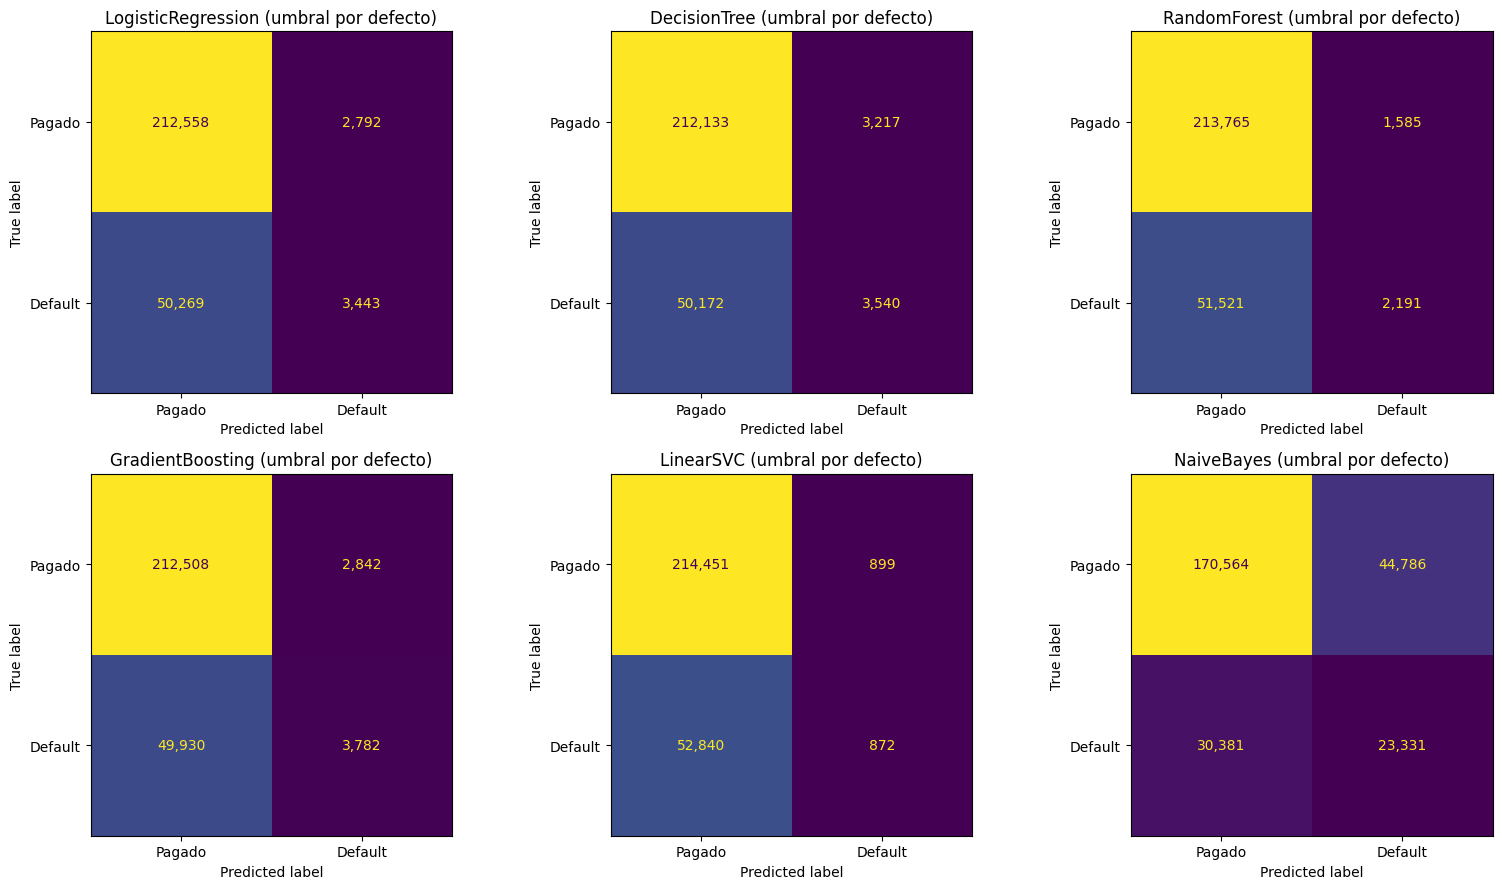

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))  # Una matriz de confusión por modelo
for ax, (nombre, r) in zip(axes.ravel(), resultados.items()):  # Recorre los modelos
    ConfusionMatrixDisplay(np.array(r["metricas"]["matriz_confusion"]), display_labels=["Pagado", "Default"]).plot(ax=ax, colorbar=False, values_format=",")  # Dibuja la matriz
    ax.set_title(f"{nombre} (umbral por defecto)")  # Título
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "03_matrices_confusion_sklearn")  # Exporta la figura
plt.show()  # Muestra la figura

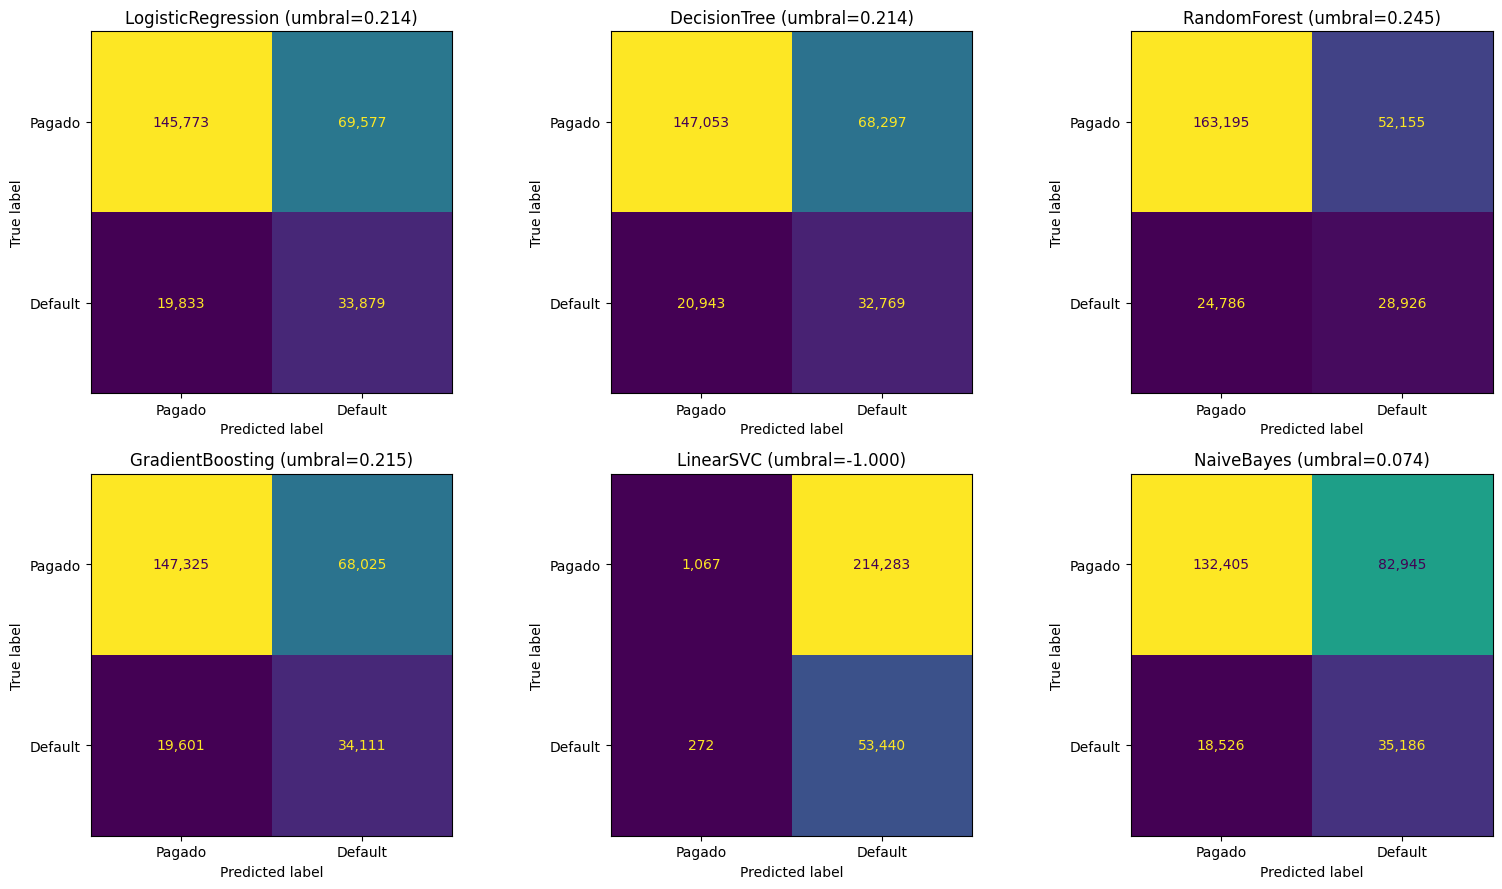

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))  # Matrices de confusión con el umbral elegido en train
for ax, (nombre, r) in zip(axes.ravel(), resultados.items()):  # Recorre los modelos
    ConfusionMatrixDisplay(np.array(r["metricas_umbral"]["matriz_confusion"]), display_labels=["Pagado", "Default"]).plot(ax=ax, colorbar=False, values_format=",")  # Dibuja la matriz
    ax.set_title(f"{nombre} (umbral={r['umbral']:.3f})")  # Título con el umbral
fig.tight_layout()  # Ajusta márgenes
plt.show()  # Muestra la figura

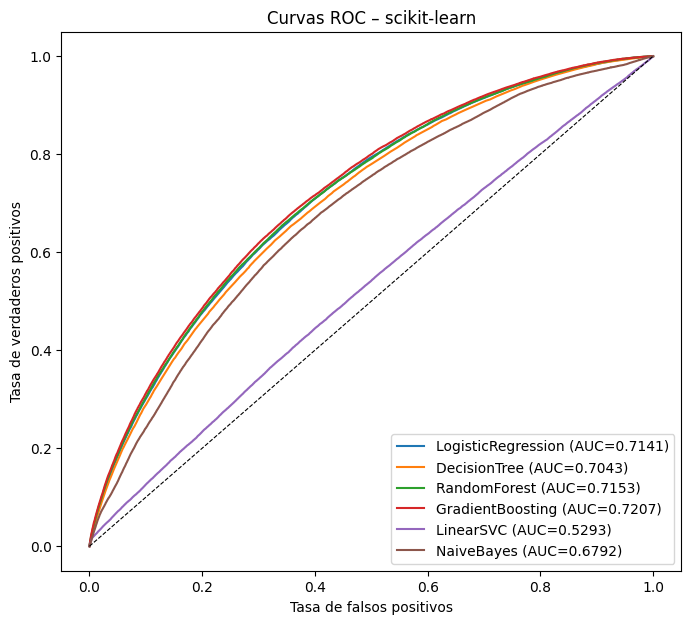

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))  # Curvas ROC de los seis modelos
for nombre in cfg.NOMBRES_MODELOS:  # Recorre los modelos en el orden canónico
    s = pd.read_parquet(cfg.DIR_SCORES_SK / f"{nombre}.parquet")  # Lee las puntuaciones guardadas
    fpr, tpr, _ = roc_curve(s[cfg.COL_TARGET], s["score"])  # Calcula la curva ROC
    ax.plot(fpr, tpr, label=f"{nombre} (AUC={resultados[nombre]['metricas']['roc_auc']:.4f})")  # Dibuja la curva
ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # Diagonal de referencia (azar)
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")  # Ejes
ax.set_title("Curvas ROC – scikit-learn"); ax.legend(loc="lower right")  # Título y leyenda
guardar_figura(fig, "03_roc_sklearn")  # Exporta la figura
plt.show()  # Muestra la figura

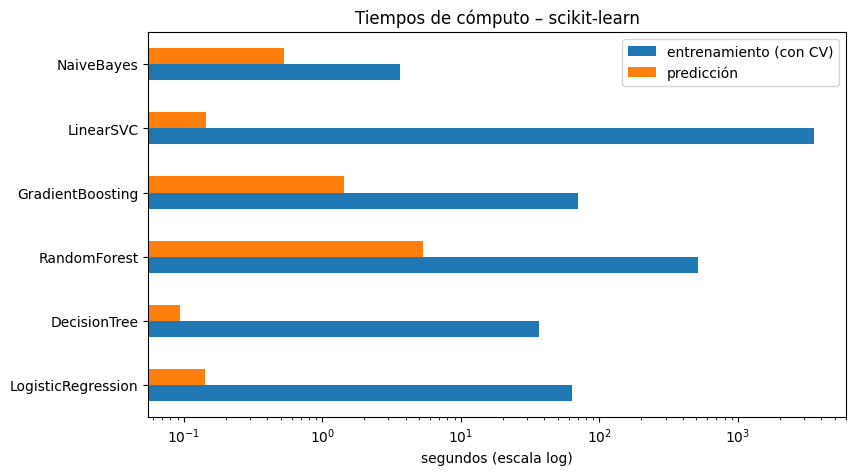

,entrenamiento (con CV),predicción
LogisticRegression,63.338732,0.141896
DecisionTree,36.685204,0.093865
RandomForest,518.896712,5.360159
GradientBoosting,70.615861,1.443551
LinearSVC,3549.439369,0.145680
NaiveBayes,3.636145,0.532384


In [12]:
tiempos = pd.DataFrame({n: {"entrenamiento (con CV)": r["tiempo_entrenamiento_s"], "predicción": r["tiempo_prediccion_s"]} for n, r in resultados.items()}).T  # Tiempos por modelo
ax = tiempos.plot.barh(figsize=(9, 5), logx=True)  # Barras en escala logarítmica
ax.set_xlabel("segundos (escala log)"); ax.set_title("Tiempos de cómputo – scikit-learn")  # Ejes y título
plt.show()  # Muestra la figura
tiempos  # Tabla de tiempos

## Interpretación de los resultados de scikit-learn

**Capacidad discriminante (AUC en test).** El mejor modelo es *gradient boosting*
(`HistGradientBoostingClassifier`, 100 iteraciones, profundidad 5): AUC = 0,7207. Le siguen el
bosque aleatorio (0,7153), la regresión logística (0,7141), el árbol de decisión (0,7043),
Naive Bayes (0,6792) y, muy por detrás, LinearSVC (0,5293). Los AUC de validación cruzada son
muy parecidos a los de test (p. ej., 0,7166 vs 0,7207 en boosting), así que no hay señales de
sobreajuste en la selección de hiperparámetros.

**Hiperparámetros.** El bosque y el boosting eligen el extremo superior de la malla
(100 árboles, profundidad 15; 100 iteraciones, profundidad 5): con 1,07 M de filas, modelos más
complejos todavía mejoran, por lo que una malla más amplia podría ganar algo de AUC. El árbol
de decisión muestra el sobreajuste clásico: profundidad 10 (0,696 en CV) supera a 15 (0,663).
En la regresión logística la regularización casi no importa (0,7096–0,7120 en CV): con un
millón de filas y 77 variables el término de penalización es despreciable.

**Métricas con el umbral por defecto (0,5).** La *accuracy* (≈ 0,80) apenas iguala a un modelo
trivial que siempre predice "pagado", y el *recall* es de solo 4–7 %: con un 20 % de defaults,
pocas probabilidades superan 0,5. Naive Bayes es la excepción (recall 0,43, accuracy 0,72)
porque sus probabilidades están mal calibradas (supone independencia y exagera la confianza).
Con el umbral que maximiza F1 **en train** (≈ 0,21), el F1 en test sube a 0,42–0,44 y el recall a
≈ 0,63 en todos los modelos útiles: el umbral importa tanto como el algoritmo.

**LinearSVC.** Su AUC (0,53 en test; 0,548 ± 0,033 en CV) es apenas mejor que el azar y muy
inestable entre pliegues. No es un problema de convergencia (en una prueba con 100 mil filas el
solucionador convergió en 371 iteraciones con el mismo AUC ≈ 0,48). La causa es la combinación de
la pérdida *hinge* con un 20 % de positivos muy solapados con los negativos: la solución óptima
está cerca de "clasificar todo como pagado" y el margen resultante casi no ordena el riesgo.
Además, `liblinear` penaliza también el intercepto (lo trata como una variable más), lo que
restringe precisamente el término que absorbe el desbalance. El umbral elegido en train (−1)
confirma la degeneración: para maximizar F1 hay que marcar casi todo como default (recall 0,99).
PySpark, que no penaliza el intercepto, obtiene 0,68 con el mismo modelo (notebook 04).

**Tiempos.** LinearSVC domina el costo (≈ 59 min, por el solucionador dual de un solo hilo
con C ≈ 0,93), seguido del bosque aleatorio (519 s). Los demás modelos, incluida la búsqueda de
*gradient boosting*, tardan menos de 75 s con los 12 hilos del equipo.

---

# 4. Preprocesamiento y modelado con PySpark

Secciones 3.2 (PySpark) y 4.3 del enunciado.

**Reglas obligatorias respetadas en este notebook**

* Se lee el CSV completo con `SparkSession`; los datos permanecen como DataFrame de Spark.
* No se usa `.toPandas()` ni `.collect()` sobre el dataset. Solo se traen al driver
  (a) tablas agregadas de pocas filas (conteos de categorías, matriz de confusión) y
  (b) al final, las columnas `id`, `default` y `score` del conjunto de prueba, cuyo tiempo de
  transferencia se reporta por separado.
* La partición común se lee del Parquet generado en el notebook 02 y se filtra por `split`
  (no se usa `randomSplit`).
* `StringIndexer`, `OneHotEncoder`, `Imputer`, `VectorAssembler` y `StandardScaler` se ajustan solo
  con train.
* El DataFrame resultante del `VectorAssembler` se cachea con `persist(MEMORY_AND_DISK)`
  antes de entrenar.
* Búsqueda de hiperparámetros exclusivamente con `ParamGridBuilder` + `CrossValidator`
  (`numFolds=3`) y `BinaryClassificationEvaluator(metricName="areaUnderROC")`.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos con time.time()
import numpy as np  # Cálculo numérico (solo sobre resultados pequeños)
import pandas as pd  # Tablas de resultados (solo resultados pequeños)
import matplotlib.pyplot as plt  # Gráficos
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay  # Curva ROC y gráfico de la matriz de confusión (sobre id/default/score)
from pyspark import StorageLevel  # Nivel de persistencia en memoria y disco
from pyspark.sql import functions as F  # Funciones de columnas de Spark
from pyspark.ml.functions import vector_to_array  # Convierte vectores de Spark en arreglos
from pyspark.ml.classification import (  # Los seis clasificadores de pyspark.ml
    LogisticRegression, DecisionTreeClassifier, RandomForestClassifier,  # Lineal y árboles
    GBTClassifier, LinearSVC, NaiveBayes,  # Boosting, SVM y Naive Bayes
)
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator  # Búsqueda de hiperparámetros
from pyspark.ml.evaluation import BinaryClassificationEvaluator  # Evaluador AUC ROC
from src import config as cfg  # Configuración central
from src import preparacion_spark as prep_sp  # Preparación con Spark
from src.utilidades import actualizar_json, guardar_json, guardar_figura, info_hardware  # Utilidades

hardware = info_hardware()  # Información del equipo
hardware  # Declaración del hardware

{'sistema': 'Windows 10',
 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD',
 'nucleos_fisicos': 6,
 'nucleos_logicos': 12,
 'ram_total_gb': 13.8,
 'ram_disponible_gb': 6.1,
 'python': '3.9.25'}

## Sesión de Spark

Se usa la configuración del enunciado (`memory.fraction` 0.8, `storageFraction` 0.3) en
modo local, con **tres cambios justificados** ("u otros equivalentes debidamente
justificados", sección 4.3):

1. `spark.sql.shuffle.partitions` y `spark.default.parallelism` = **6** (una partición por
   hilo) en vez de 400. El valor 400 está pensado para un clúster con cientos de núcleos; en
   una máquina de 12 hilos cada nivel de cada árbol (RF, GBT) lanza 400 tareas diminutas y el
   costo de planificarlas domina el cálculo. En una prueba preliminar con los mismos datos,
   10 iteraciones de `GBTClassifier` tardaron 21,4 s con 400 particiones, 9,8 s con 48 y 8,7 s
   con 12; 20 árboles de `RandomForestClassifier`, 25,3 s, 5,8 s y 4,4 s. Además, cada
   partición acumula las estadísticas de los nodos en construcción (hasta `maxMemoryInMB` =
   256 MB) y luego se combinan entre particiones.
2. **`local[6]`** (un hilo por núcleo físico) en vez de los 12 hilos lógicos. En cada nivel,
   Spark envía a *cada tarea* una copia serializada de todos los árboles en construcción; con
   100 árboles de profundidad 15 (≈ 1,4 millones de nodos) y 12 tareas simultáneas la JVM se
   quedó sin memoria en tres ejecuciones sobre el dataset completo (con 48 y con 12
   particiones). Con 6 hilos ese mismo bosque se entrenó sin problemas (524 s). Los hilos
   lógicos adicionales (SMT) aportan poco en cálculo numérico intensivo.
3. `spark.driver.memory` = `spark.executor.memory` = **9g** (1 GB más que el enunciado como
   margen). En modo local el driver y el ejecutor son el mismo proceso; el equipo tiene 14 GB.

Consecuencia para la comparación de tiempos: scikit-learn usa 12 hilos (`n_jobs=-1`) y
PySpark 6, lo que se tiene en cuenta en la reflexión final.

El notebook 07 cuantifica el efecto de las particiones y de la caché sobre el dataset completo.

In [2]:
spark = prep_sp.crear_sesion(memoria=cfg.MEMORIA_SPARK, particiones=cfg.PARTICIONES_SPARK)  # Crea la sesión (local[6], 6 particiones, 9g; ver justificación)
conf = spark.sparkContext.getConf()  # Configuración efectiva de la sesión
{k: conf.get(k) for k in ["spark.master", "spark.sql.shuffle.partitions", "spark.default.parallelism", "spark.driver.memory",  # Parámetros relevantes
                          "spark.executor.memory", "spark.memory.fraction", "spark.memory.storageFraction"]}  # Se muestran para el informe

{'spark.master': 'local[6]',
 'spark.sql.shuffle.partitions': '6',
 'spark.default.parallelism': '6',
 'spark.driver.memory': '9g',
 'spark.executor.memory': '9g',
 'spark.memory.fraction': '0.8',
 'spark.memory.storageFraction': '0.3'}

## Preprocesamiento

El archivo `.gz` **no es divisible**, así que Spark lo lee en una única partición. Para
aprovechar los 6 hilos, los datos se reparticionan explícitamente en las mismas
6 particiones (≈ 180 mil filas de train cada una), de modo que cada pasada de los
algoritmos iterativos mantiene ocupados todos los hilos con la mínima sobrecarga.

In [3]:
N_PARTICIONES = cfg.PARTICIONES_SPARK  # 6 particiones de datos, una por hilo (ver justificación)
tiempos_prep = {}  # Tiempos de cada etapa del preprocesamiento
t0 = time.time()  # Inicio del preprocesamiento
df = prep_sp.construir_variables(prep_sp.leer_csv(spark))  # Lee el CSV completo y construye las variables (perezoso)
particion = spark.read.parquet(str(cfg.RUTA_PARTICION))  # Lee la partición común (id, split)
df = df.join(F.broadcast(particion), on=cfg.COL_ID, how="inner")  # Asocia cada préstamo con su split (la tabla pequeña se difunde)
df = prep_sp.transformar_numericas(df)  # log1p e indicador de nulo (deterministas)
df = df.repartition(N_PARTICIONES).persist(StorageLevel.MEMORY_AND_DISK)  # Reparte en 6 particiones y guarda en caché
n_total = df.count()  # Acción que materializa lectura + construcción + unión
tiempos_prep["lectura_y_construccion"] = time.time() - t0  # Tiempo de esta etapa
train_raw = df.filter(F.col("split") == "train")  # Conjunto de entrenamiento (filtro por split)
test_raw = df.filter(F.col("split") == "test")  # Conjunto de prueba (filtro por split)
print(f"Filas: {n_total:,}")  # Total de filas con desenlace final

Filas: 1,345,310


In [4]:
t0 = time.time()  # Inicio del ajuste de transformadores
frecuentes = prep_sp.categorias_frecuentes(train_raw, cfg.CATEGORICAS_MODELO)  # Categorías frecuentes aprendidas solo con train
train_c = prep_sp.agrupar_categorias(train_raw, frecuentes)  # Agrupa categorías raras en train
test_c = prep_sp.agrupar_categorias(test_raw, frecuentes)  # Aplica la misma agrupación a test
modelo_prep = prep_sp.pipeline_preprocesamiento().fit(train_c)  # Ajusta Imputer, StandardScaler, StringIndexer y OneHotEncoder solo con train
columnas = [cfg.COL_ID, cfg.COL_TARGET, "features"]  # Columnas necesarias para modelar
train = modelo_prep.transform(train_c).select(*columnas).persist(StorageLevel.MEMORY_AND_DISK)  # Train transformado y cacheado (tras el VectorAssembler)
test = modelo_prep.transform(test_c).select(*columnas).persist(StorageLevel.MEMORY_AND_DISK)  # Test transformado y cacheado
n_train, n_test = train.count(), test.count()  # Acciones que materializan la caché
df.unpersist()  # Libera la caché intermedia
tiempos_prep["ajuste_y_transformacion"] = time.time() - t0  # Tiempo de esta etapa
tiempos_prep["total"] = sum(tiempos_prep.values())  # Tiempo total de preprocesamiento
actualizar_json(cfg.RUTA_TIEMPOS_PREP, "pyspark", tiempos_prep)  # Guarda los tiempos para la comparación final
print(f"train: {n_train:,}  test: {n_test:,}  particiones train: {train.rdd.getNumPartitions()}")  # Tamaños y particiones
print({k: round(v, 1) for k, v in tiempos_prep.items()})  # Tiempos en segundos
print("Categorías conservadas:", frecuentes)  # Categorías tras agrupar raras

train: 1,076,248  test: 269,062  particiones train: 6
{'lectura_y_construccion': 25.0, 'ajuste_y_transformacion': 13.2, 'total': 38.2}
Categorías conservadas: {'grade': ['A', 'B', 'C', 'D', 'E', 'F'], 'home_ownership': ['MORTGAGE', 'OWN', 'RENT'], 'verification_status': ['Not Verified', 'Source Verified', 'Verified'], 'purpose': ['car', 'credit_card', 'debt_consolidation', 'home_improvement', 'major_purchase', 'medical', 'other', 'small_business'], 'addr_state': ['AL', 'AZ', 'CA', 'CO', 'CT', 'FL', 'GA', 'IL', 'IN', 'LA', 'MA', 'MD', 'MI', 'MN', 'MO', 'NC', 'NJ', 'NV', 'NY', 'OH', 'OR', 'PA', 'SC', 'TN', 'TX', 'VA', 'WA', 'WI'], 'initial_list_status': ['f', 'w'], 'application_type': ['Individual', 'Joint App']}


In [5]:
dim = train.select("features").first()[0].size  # Dimensión del vector de características (una sola fila)
print("Dimensión de 'features':", dim)  # Spark tiene una columna más por categórica que sklearn: StringIndexer(handleInvalid="keep") reserva un índice para categorías no vistas
train.groupBy(cfg.COL_TARGET).count().orderBy(cfg.COL_TARGET).show()  # Distribución de clases en train (tabla agregada)

Dimensión de 'features': 84


+-------+------+
|default| count|
+-------+------+
|      0|861401|
|      1|214847|
+-------+------+



## Modelos, espacios de búsqueda y validación cruzada

* Regresión logística y LinearSVC: `regParam` ∈ {1e-6, 1e-5, 1e-4}, L2 (`elasticNetParam=0`).
* Árboles: `maxBins = 32` (valor por defecto, se reporta). Cada variable continua se
  discretiza en ≤ 32 intervalos por cuantiles aproximados, mientras scikit-learn evalúa
  todos los cortes exactos (o 255 intervalos en `HistGradientBoosting`).
* `GBTClassifier` con `stepSize = 0.1`. `NaiveBayes(modelType="gaussian")` sin búsqueda.
* `BinaryClassificationEvaluator(metricName="areaUnderROC")` se aplica sobre la columna
  `probability` (segundo elemento = P(default)) en todos los modelos salvo LinearSVC, que solo
  ofrece `rawPrediction` (margen). **Motivo:** en los árboles de Spark `rawPrediction` contiene los
  *conteos* de cada clase en la hoja (no proporciones) y en Naive Bayes log-probabilidades
  conjuntas; ordenar por su segundo elemento no equivale a ordenar por riesgo y produce AUC
  erróneos (en una prueba preliminar, 0.35 para un árbol cuyo AUC real era 0.65).
* `CrossValidator(numFolds=3, parallelism=3)`: se evalúan 3 combinaciones a la vez con hilos
  del driver; no cambia los resultados, solo aprovecha mejor los núcleos. En RandomForest y
  GBT se usa `parallelism=1`: con 3 bosques de 100 árboles de profundidad 15 a la vez la JVM
  (8 GB) se quedó sin memoria en una primera ejecución. Por el mismo motivo solo se conserva
  vivo el mejor modelo probabilístico (el que se explica con LIME al final).

In [6]:
def evaluador_para(nombre):  # Evaluador AUC ROC con la columna de puntuación adecuada a cada modelo
    """En árboles, rawPrediction guarda CONTEOS de clase por hoja y en NaiveBayes log-probabilidades conjuntas;
    ninguno es monótono con P(default), así que se evalúa sobre 'probability'. LinearSVC solo tiene rawPrediction (margen)."""
    columna = "rawPrediction" if nombre == "LinearSVC" else "probability"  # Columna con la puntuación ordenable
    return BinaryClassificationEvaluator(labelCol=cfg.COL_TARGET, rawPredictionCol=columna, metricName="areaUnderROC")  # AUC ROC

comunes = dict(featuresCol="features", labelCol=cfg.COL_TARGET)  # Parámetros comunes a todos los modelos
lr = LogisticRegression(elasticNetParam=0.0, maxIter=100, **comunes)  # Regresión logística L2
dt = DecisionTreeClassifier(maxBins=cfg.MAX_BINS_SPARK, seed=cfg.SEMILLA, **comunes)  # Árbol de decisión
rf = RandomForestClassifier(maxBins=cfg.MAX_BINS_SPARK, seed=cfg.SEMILLA, **comunes)  # Bosque aleatorio
gbt = GBTClassifier(stepSize=cfg.GB_TASA_APRENDIZAJE, maxBins=cfg.MAX_BINS_SPARK, seed=cfg.SEMILLA, **comunes)  # Gradient boosting
svc = LinearSVC(maxIter=100, **comunes)  # SVM lineal (pérdida hinge)
nb = NaiveBayes(modelType="gaussian", **comunes)  # Naive Bayes gaussiano
modelos = {  # Estimador y malla de parámetros de cada modelo
    "LogisticRegression": (lr, ParamGridBuilder().addGrid(lr.regParam, cfg.REG_PARAMS).build()),  # 3 combinaciones
    "DecisionTree": (dt, ParamGridBuilder().addGrid(dt.maxDepth, cfg.PROFUNDIDADES_ARBOL).build()),  # 3 combinaciones
    "RandomForest": (rf, ParamGridBuilder().addGrid(rf.numTrees, cfg.RF_ARBOLES).addGrid(rf.maxDepth, cfg.RF_PROFUNDIDADES).build()),  # 9 combinaciones
    "GradientBoosting": (gbt, ParamGridBuilder().addGrid(gbt.maxIter, cfg.GB_ITERACIONES).addGrid(gbt.maxDepth, cfg.GB_PROFUNDIDADES).build()),  # 4 combinaciones
    "LinearSVC": (svc, ParamGridBuilder().addGrid(svc.regParam, cfg.REG_PARAMS).build()),  # 3 combinaciones
    "NaiveBayes": (nb, ParamGridBuilder().build()),  # Sin búsqueda (una sola configuración)
}


def columna_score(nombre):  # Expresión de la puntuación de la clase positiva
    fuente = "rawPrediction" if nombre == "LinearSVC" else "probability"  # LinearSVC no produce probabilidades
    return vector_to_array(F.col(fuente))[1].alias("score")  # Segundo elemento del vector


def umbral_optimo_f1_spark(pred_df, n_candidatos=199):  # Versión distribuida de pruebas.umbral_optimo_f1
    """Candidatos = cuantiles 0.5 %…99.5 % de la puntuación; F1 de todos en una sola agregación."""
    probs = list(np.linspace(0.005, 0.995, n_candidatos))  # Probabilidades de los cuantiles
    candidatos = sorted(set(pred_df.approxQuantile("score", probs, 1e-4)))  # Cuantiles aproximados (lista pequeña)
    y = F.col(cfg.COL_TARGET)  # Etiqueta real
    exprs = [F.sum(F.when(F.col("score") >= u, y).otherwise(0)).alias(f"tp{i}") for i, u in enumerate(candidatos)]  # TP de cada umbral
    exprs += [F.sum(F.when(F.col("score") >= u, 1).otherwise(0)).alias(f"pp{i}") for i, u in enumerate(candidatos)]  # Predichos positivos de cada umbral
    exprs += [F.sum(y).alias("pos")]  # Total de positivos
    fila = pred_df.agg(*exprs).first()  # Una sola fila con todos los conteos
    f1 = [2 * fila[f"tp{i}"] / (fila[f"pp{i}"] + fila["pos"]) for i in range(len(candidatos))]  # F1 = 2TP / (PP + P)
    mejor = int(np.argmax(f1))  # Índice del mejor umbral
    return float(candidatos[mejor]), float(f1[mejor])  # Umbral y F1 en train


def metricas_spark(pred_df, col_pred):  # Métricas a partir de la matriz de confusión agregada en Spark
    conteos = {(r[cfg.COL_TARGET], int(r[col_pred])): r["count"] for r in pred_df.groupBy(cfg.COL_TARGET, col_pred).count().collect()}  # 4 filas como máximo
    tn, fp = conteos.get((0, 0), 0), conteos.get((0, 1), 0)  # Fila de la clase real 0
    fn, tp = conteos.get((1, 0), 0), conteos.get((1, 1), 0)  # Fila de la clase real 1
    precision = tp / (tp + fp) if tp + fp else 0.0  # Precisión
    recall = tp / (tp + fn) if tp + fn else 0.0  # Recall
    return {"accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": precision, "recall": recall,  # Métricas básicas
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,  # F1
            "matriz_confusion": [[tn, fp], [fn, tp]]}  # [[TN, FP], [FN, TP]]

## Entrenamiento con `CrossValidator`

Para cada modelo se mide: (1) entrenamiento = validación cruzada + reajuste del mejor
modelo con todo train; (2) predicción = `transform` del test y cálculo de métricas;
(3) transferencia = traer `id`, `default`, `score` del test al driver (se reporta aparte).

In [7]:
resultados = {}  # Métricas, tiempos e hiperparámetros por modelo
modelo_lime, auc_lime = None, -1.0  # Único modelo que se conserva vivo: el mejor probabilístico (para LIME)
for nombre, (estimador, grid) in modelos.items():  # Recorre los seis modelos
    print(f"→ {nombre} ...", flush=True)  # Progreso
    evaluador = evaluador_para(nombre)  # Evaluador AUC con la columna adecuada
    paralelo = 1 if nombre in ("RandomForest", "GradientBoosting") else 3  # Ensambles de uno en uno (memoria de la JVM)
    cv = CrossValidator(estimator=estimador, estimatorParamMaps=grid, evaluator=evaluador,  # Validación cruzada con AUC
                        numFolds=cfg.PLIEGUES_CV, parallelism=paralelo, seed=cfg.SEMILLA)  # 3 pliegues, semilla fija
    t0 = time.time()  # Inicio del entrenamiento
    modelo_cv = cv.fit(train)  # Validación cruzada + reajuste del mejor modelo
    t_entrenamiento = time.time() - t0  # Tiempo de entrenamiento (incluye la CV)
    mejor = modelo_cv.bestModel  # Mejor modelo según AUC de validación
    t0 = time.time()  # Inicio de la predicción
    col_eval = evaluador.getRawPredictionCol()  # Columna que usa el evaluador (probability o rawPrediction)
    pred = mejor.transform(test).select(cfg.COL_ID, cfg.COL_TARGET, "prediction", col_eval, columna_score(nombre))  # Predicciones de test
    pred = pred.persist(StorageLevel.MEMORY_AND_DISK)  # Cachea para calcular varias métricas
    auc = evaluador.evaluate(pred)  # AUC ROC en test
    m = metricas_spark(pred, "prediction")  # Métricas con el umbral por defecto
    t_prediccion = time.time() - t0  # Tiempo de predicción + métricas
    pred_train = mejor.transform(train).select(cfg.COL_TARGET, columna_score(nombre))  # Puntuaciones en train (para el umbral)
    umbral, f1_train = umbral_optimo_f1_spark(pred_train)  # Umbral que maximiza F1 en train
    m_umbral = metricas_spark(pred.withColumn("pred_umbral", (F.col("score") >= umbral).cast("int")), "pred_umbral")  # Métricas con ese umbral
    t0 = time.time()  # Inicio de la transferencia permitida
    scores = pred.select(cfg.COL_ID, cfg.COL_TARGET, "score").toPandas()  # Solo id, default y score del test
    t_transferencia = time.time() - t0  # Tiempo de transferencia (se reporta aparte)
    pred.unpersist()  # Libera la caché de predicciones
    scores.to_parquet(cfg.DIR_SCORES_SP / f"{nombre}.parquet", index=False)  # Guarda las puntuaciones de test
    idx = int(np.argmax(modelo_cv.avgMetrics))  # Índice de la mejor combinación
    mejores = {p.name: v for p, v in grid[idx].items()}  # Hiperparámetros ganadores
    resultados[nombre] = {  # Guarda todo lo relevante del modelo
        "mejores_parametros": mejores, "auc_cv": float(modelo_cv.avgMetrics[idx]),  # Hiperparámetros y AUC de validación
        "auc_cv_todas": [{"params": {p.name: v for p, v in g.items()}, "auc": float(a)} for g, a in zip(grid, modelo_cv.avgMetrics)],  # Todas las combinaciones
        "tiempo_entrenamiento_s": t_entrenamiento, "tiempo_prediccion_s": t_prediccion, "tiempo_transferencia_s": t_transferencia,  # Tiempos
        "metricas": {**m, "roc_auc": auc}, "umbral": umbral, "f1_train_umbral": f1_train,  # Métricas con umbral por defecto
        "metricas_umbral": {**m_umbral, "roc_auc": auc},  # Métricas con el umbral elegido en train
    }
    if nombre != "LinearSVC" and auc > auc_lime:  # ¿Es el mejor modelo probabilístico hasta ahora?
        modelo_lime, auc_lime = mejor, auc  # Se conserva para LIME
    del modelo_cv, mejor  # Libera los demás modelos de la memoria de la JVM
    guardar_json({"hardware": hardware, "max_bins": cfg.MAX_BINS_SPARK, "particiones_datos": N_PARTICIONES, "modelos": resultados}, cfg.RUTA_METRICAS_SP)  # Guarda las métricas acumuladas
    print(f"   AUC test={auc:.4f}  entrenamiento={t_entrenamiento:.1f}s  predicción={t_prediccion:.1f}s  transferencia={t_transferencia:.1f}s  {mejores}", flush=True)  # Resumen

→ LogisticRegression ...


   AUC test=0.7141  entrenamiento=27.1s  predicción=1.1s  transferencia=1.0s  {'regParam': 1e-05}


→ DecisionTree ...


   AUC test=0.7018  entrenamiento=25.5s  predicción=0.5s  transferencia=0.8s  {'maxDepth': 10}


→ RandomForest ...


...

   AUC test=0.7208  entrenamiento=580.8s  predicción=1.6s  transferencia=0.9s  {'maxIter': 100, 'maxDepth': 5}


→ LinearSVC ...


   AUC test=0.6793  entrenamiento=97.4s  predicción=1.1s  transferencia=0.9s  {'regParam': 1e-05}


→ NaiveBayes ...


   AUC test=0.6795  entrenamiento=6.3s  predicción=1.0s  transferencia=0.7s  {}


## Resultados

In [8]:
tabla = pd.DataFrame({n: {"AUC_cv": r["auc_cv"], **{k: v for k, v in r["metricas"].items() if k != "matriz_confusion"},  # Métricas por modelo
                          "F1_umbral_train": r["metricas_umbral"]["f1"], "umbral": r["umbral"],  # F1 con umbral elegido en train
                          "t_entrenamiento_s": r["tiempo_entrenamiento_s"], "t_prediccion_s": r["tiempo_prediccion_s"],  # Tiempos
                          "t_transferencia_s": r["tiempo_transferencia_s"], "mejores_parametros": r["mejores_parametros"]}  # Transferencia e hiperparámetros
                      for n, r in resultados.items()}).T  # Una fila por modelo
tabla  # Muestra la tabla resumen

,AUC_cv,accuracy,precision,recall,f1,roc_auc,F1_umbral_train,umbral,t_entrenamiento_s,t_prediccion_s,t_transferencia_s,mejores_parametros
LogisticRegression,0.713855,0.802785,0.551516,0.064678,0.115779,0.714109,0.430945,0.212474,27.073861,1.097751,0.982955,{'regParam': 1e-05}
DecisionTree,0.70089,0.801269,0.51849,0.06291,0.112205,0.701812,0.420187,0.215241,25.515612,0.501452,0.766742,{'maxDepth': 10}
RandomForest,0.713959,0.802711,0.580662,0.042151,0.078596,0.714218,0.428694,0.240502,2740.532909,52.799507,10.755929,"{'numTrees': 100, 'maxDepth': 15}"
GradientBoosting,0.719735,0.803896,0.556161,0.087392,0.151049,0.720775,0.437271,0.214045,580.838081,1.622343,0.91918,"{'maxIter': 100, 'maxDepth': 5}"
LinearSVC,0.677934,0.800373,0.0,0.0,0.0,0.679319,0.402729,-1.000016,97.362244,1.056653,0.906327,{'regParam': 1e-05}
NaiveBayes,0.679856,0.720262,0.342529,0.436457,0.38383,0.679456,0.409967,0.076243,6.260258,0.9962,0.736438,{}


In [9]:
for nombre, r in resultados.items():  # AUC de validación de cada combinación
    print(f"\n{nombre}")  # Nombre del modelo
    display(pd.DataFrame(r["auc_cv_todas"]).sort_values("auc", ascending=False))  # Tabla ordenada


LogisticRegression


,params,auc
1,{'regParam': 1e-05},0.713855
2,{'regParam': 0.0001},0.713855
0,{'regParam': 1e-06},0.713855



DecisionTree


,params,auc
1,{'maxDepth': 10},0.700890
2,{'maxDepth': 15},0.674161
0,{'maxDepth': 5},0.654089



RandomForest


...

,params,auc
3,"{'maxIter': 100, 'maxDepth': 5}",0.719735
1,"{'maxIter': 50, 'maxDepth': 5}",0.716376
2,"{'maxIter': 100, 'maxDepth': 3}",0.715892
0,"{'maxIter': 50, 'maxDepth': 3}",0.712023



LinearSVC


,params,auc
1,{'regParam': 1e-05},0.677934
0,{'regParam': 1e-06},0.668390
2,{'regParam': 0.0001},0.648452



NaiveBayes


,params,auc
0,{},0.679856


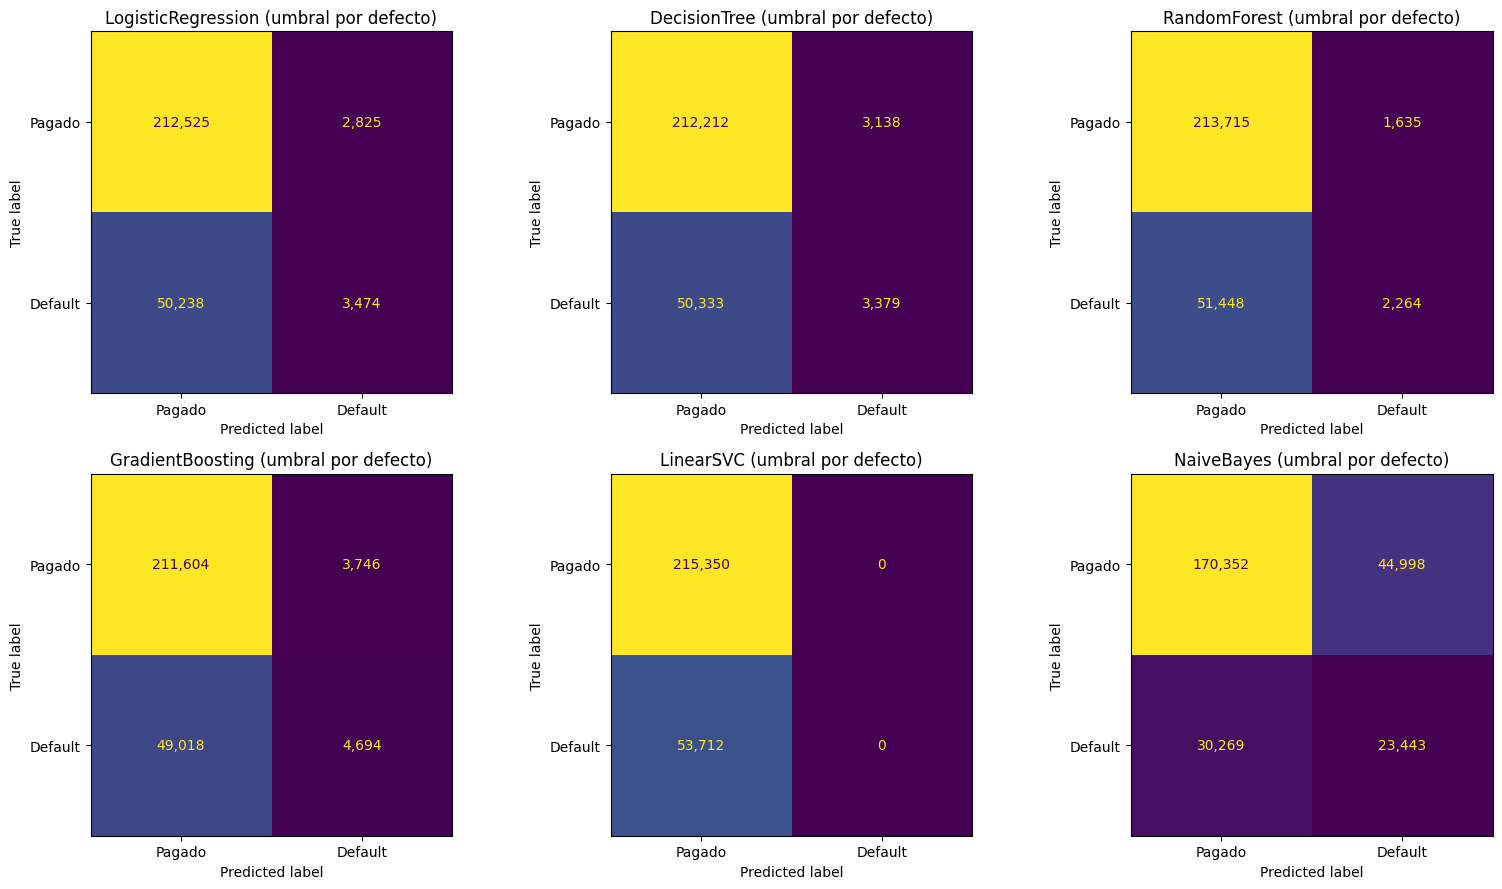

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))  # Una matriz de confusión por modelo
for ax, (nombre, r) in zip(axes.ravel(), resultados.items()):  # Recorre los modelos
    ConfusionMatrixDisplay(np.array(r["metricas"]["matriz_confusion"]), display_labels=["Pagado", "Default"]).plot(ax=ax, colorbar=False, values_format=",")  # Dibuja la matriz
    ax.set_title(f"{nombre} (umbral por defecto)")  # Título
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "04_matrices_confusion_pyspark")  # Exporta la figura
plt.show()  # Muestra la figura

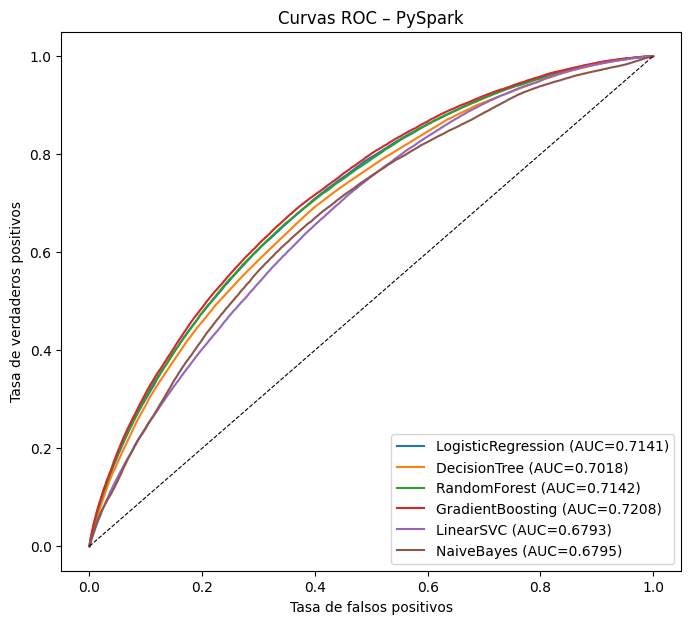

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))  # Curvas ROC de los seis modelos
for nombre in [m for m in cfg.NOMBRES_MODELOS if m in resultados]:  # Recorre los modelos en orden canónico
    s = pd.read_parquet(cfg.DIR_SCORES_SP / f"{nombre}.parquet")  # Puntuaciones transferidas (id, default, score)
    fpr, tpr, _ = roc_curve(s[cfg.COL_TARGET], s["score"])  # Curva ROC
    ax.plot(fpr, tpr, label=f"{nombre} (AUC={resultados[nombre]['metricas']['roc_auc']:.4f})")  # Dibuja la curva
ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # Diagonal de referencia
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")  # Ejes
ax.set_title("Curvas ROC – PySpark"); ax.legend(loc="lower right")  # Título y leyenda
guardar_figura(fig, "04_roc_pyspark")  # Exporta la figura
plt.show()  # Muestra la figura

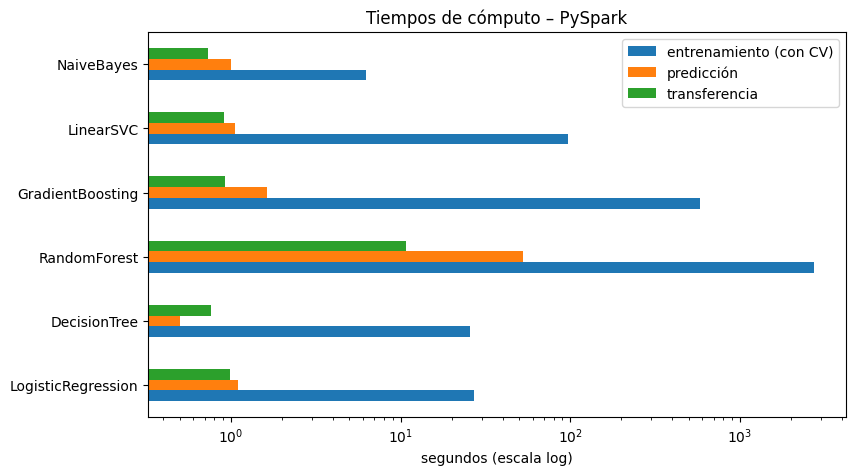

,entrenamiento (con CV),predicción,transferencia
LogisticRegression,27.073861,1.097751,0.982955
DecisionTree,25.515612,0.501452,0.766742
RandomForest,2740.532909,52.799507,10.755929
GradientBoosting,580.838081,1.622343,0.919180
LinearSVC,97.362244,1.056653,0.906327
NaiveBayes,6.260258,0.996200,0.736438


In [12]:
tiempos = pd.DataFrame({n: {"entrenamiento (con CV)": r["tiempo_entrenamiento_s"], "predicción": r["tiempo_prediccion_s"],  # Tiempos por modelo
                            "transferencia": r["tiempo_transferencia_s"]} for n, r in resultados.items()}).T  # Incluye la transferencia
ax = tiempos.plot.barh(figsize=(9, 5), logx=True)  # Barras en escala logarítmica
ax.set_xlabel("segundos (escala log)"); ax.set_title("Tiempos de cómputo – PySpark")  # Ejes y título
plt.show()  # Muestra la figura
tiempos  # Tabla de tiempos

## LIME sobre el mejor modelo de PySpark (en esta misma sesión)

LIME trabaja en memoria local con arreglos de NumPy, pero el modelo de PySpark vive en la
JVM de esta sesión. En Windows sin `winutils`, Spark no puede guardar modelos en disco, y
reajustar el modelo en otra sesión no reproduce exactamente el elegido por el
`CrossValidator`. Por eso la explicación del modelo de PySpark se genera **aquí**, mientras
el modelo sigue vivo. El notebook 06 carga estas explicaciones y las compara con las de
scikit-learn sobre las **mismas instancias y las mismas perturbaciones**.

Cada llamada de LIME (2.000 perturbaciones) se escribe en un Parquet temporal y se lee con
Spark: crear el DataFrame directamente desde pandas sin Arrow tardaba ≈ 250 s por llamada en
Windows (un proceso de Python por partición), frente a menos de un segundo con Parquet.

In [13]:
from src import lime_utils  # Utilidades de LIME compartidas con el notebook 06
from src.utilidades import leer_json  # Lectura de las métricas de scikit-learn

espacio = lime_utils.EspacioLime()  # Datos en el espacio original y conversiones
met_sk = leer_json(cfg.RUTA_METRICAS_SK)["modelos"]  # Métricas de scikit-learn (notebook 03)
mejor_sk = lime_utils.mejor_probabilistico(met_sk)  # Mejor modelo probabilístico de scikit-learn
mejor_sp = lime_utils.mejor_probabilistico(resultados)  # Mejor modelo probabilístico de PySpark
modelo_sp = modelo_lime  # Modelo ganador del CrossValidator del mejor modelo probabilístico (vivo en la sesión)
ruta_tmp = str(cfg.DIR_DATOS / "lime_perturbaciones.parquet")  # Archivo temporal de perturbaciones
llamadas = []  # Tiempo de cada llamada de LIME a Spark


def predecir_sp(X):  # Función de predicción que LIME llamará con cada lote de perturbaciones
    t0 = time.time()  # Inicio de la llamada
    d = espacio.desde_lime(X)  # Perturbaciones en el espacio original (pandas, en el driver)
    d["_orden"] = np.arange(len(d))  # Orden para reconstruir el resultado
    d.to_parquet(ruta_tmp, index=False)  # Se escriben en Parquet (los NaN quedan como nulos)
    sdf = spark.read.parquet(ruta_tmp)  # Spark lee las perturbaciones
    for c in cfg.NUMERICAS_MODELO:  # Asegura tipo double en las numéricas
        sdf = sdf.withColumn(c, F.col(c).cast("double"))  # Conversión de tipo
    sdf = prep_sp.agrupar_categorias(prep_sp.transformar_numericas(sdf), frecuentes)  # Mismas reglas que en train
    pred = modelo_sp.transform(modelo_prep.transform(sdf))  # Preprocesamiento + modelo en Spark
    p1 = pred.select("_orden", vector_to_array("probability")[1].alias("p1")).toPandas().sort_values("_orden")["p1"].to_numpy()  # Solo las perturbaciones vuelven al driver
    llamadas.append(time.time() - t0)  # Registra el tiempo de la llamada
    return np.column_stack([1 - p1, p1])  # Probabilidades [P(0), P(1)]


verif = predecir_sp(espacio.a_lime(espacio.test.iloc[:2000]))[:, 1]  # Verificación sobre 2.000 filas de test
guardadas = pd.read_parquet(cfg.DIR_SCORES_SP / f"{mejor_sp}.parquet").set_index(cfg.COL_ID).loc[espacio.test[cfg.COL_ID].iloc[:2000], "score"].to_numpy()  # Puntuaciones del modelo
print(f"{mejor_sp}: máx. diferencia entre predecir_sp y las puntuaciones guardadas = {np.abs(verif - guardadas).max():.2e}")  # ≈ 0 (salvo nulos imputados)

GradientBoosting: máx. diferencia entre predecir_sp y las puntuaciones guardadas = 0.00e+00


Mejor sklearn: GradientBoosting | mejor PySpark: GradientBoosting | FN comunes: 18,480 | FP comunes: 62,896 | instancias: {'Falso negativo': 101230150, 'Falso positivo': 2826869}


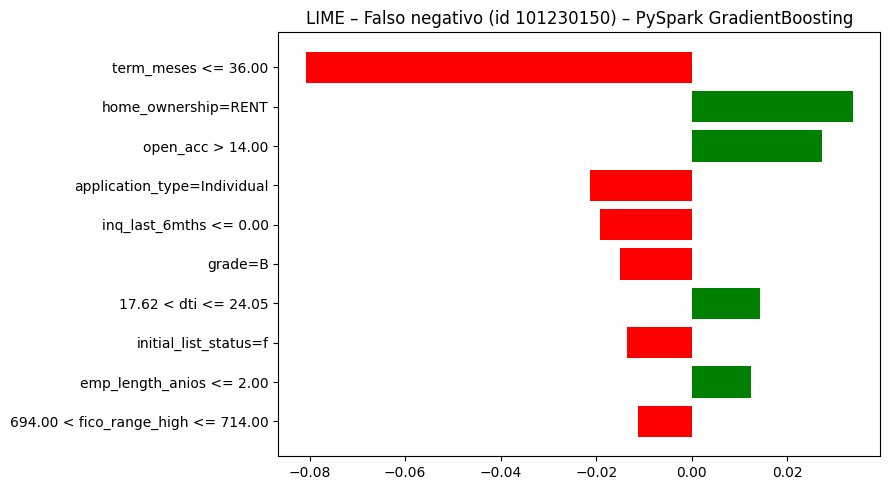

Falso negativo: P(default)=0.140  R² local=0.195  tiempo=4.0s


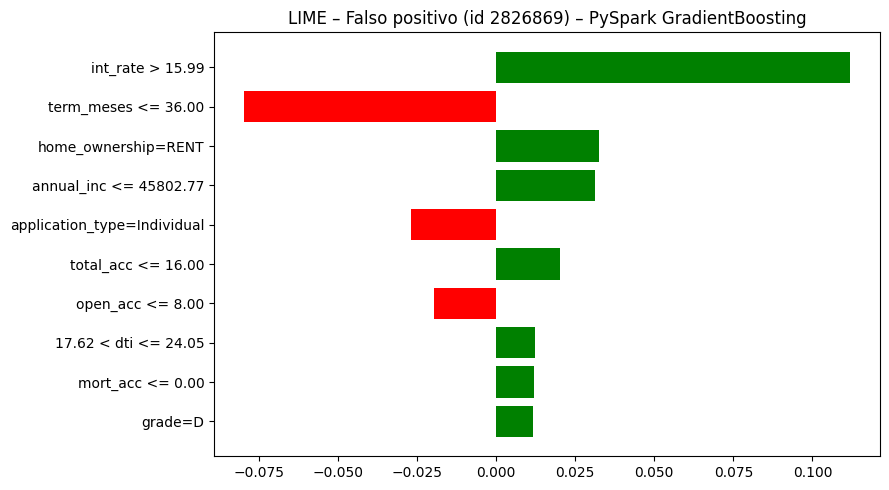

Falso positivo: P(default)=0.299  R² local=0.442  tiempo=3.9s
Llamadas a Spark: 3 | tiempo medio por llamada: 0.57 s


In [14]:
s_sk = pd.read_parquet(cfg.DIR_SCORES_SK / f"{mejor_sk}.parquet").set_index(cfg.COL_ID)["score"]  # Puntuaciones de scikit-learn
s_sp = pd.read_parquet(cfg.DIR_SCORES_SP / f"{mejor_sp}.parquet").set_index(cfg.COL_ID)["score"]  # Puntuaciones de PySpark
instancias, n_fn, n_fp = lime_utils.seleccionar_instancias(espacio.test, s_sk, s_sp, met_sk[mejor_sk]["umbral"], resultados[mejor_sp]["umbral"])  # Instancias mal clasificadas por ambos
print(f"Mejor sklearn: {mejor_sk} | mejor PySpark: {mejor_sp} | FN comunes: {n_fn:,} | FP comunes: {n_fp:,} | instancias: {instancias}")  # Resumen
explicaciones_sp = {}  # Resultados serializables
for etiqueta, id_ in instancias.items():  # Recorre las dos instancias
    t0 = time.time()  # Inicio de la explicación
    exp = espacio.explicador().explain_instance(espacio.instancia(id_), predecir_sp, num_features=lime_utils.N_VARIABLES, num_samples=lime_utils.N_MUESTRAS)  # Explicación local
    explicaciones_sp[etiqueta] = {"id": id_, "pesos": exp.as_list(label=1), "p_default": float(exp.predict_proba[1]),  # Pesos y probabilidad
                                  "r2_local": float(exp.score), "intercepto": float(exp.intercept[1]), "tiempo_s": time.time() - t0}  # Calidad y tiempo
    fig = exp.as_pyplot_figure(label=1); fig.set_size_inches(9, 5)  # Gráfico de pesos hacia "Charged Off"
    plt.title(f"LIME – {etiqueta} (id {id_}) – PySpark {mejor_sp}"); plt.tight_layout()  # Título
    guardar_figura(fig, f"04_lime_{etiqueta.replace(' ', '_')}_pyspark"); plt.show()  # Exporta y muestra
    print(f"{etiqueta}: P(default)={exp.predict_proba[1]:.3f}  R² local={exp.score:.3f}  tiempo={time.time() - t0:.1f}s")  # Resumen
guardar_json({"mejor_sklearn": mejor_sk, "mejor_pyspark": mejor_sp, "instancias": instancias, "n_fn_comunes": n_fn, "n_fp_comunes": n_fp,  # Metadatos
              "explicaciones": explicaciones_sp, "tiempo_medio_llamada_s": float(np.mean(llamadas)), "n_llamadas": len(llamadas)},  # Explicaciones y tiempos
             lime_utils.RUTA_EXPLICACIONES_SP)  # Archivo leído por el notebook 06
print(f"Llamadas a Spark: {len(llamadas)} | tiempo medio por llamada: {np.mean(llamadas):.2f} s")  # Costo de cada llamada

In [15]:
train.unpersist(); test.unpersist()  # Libera la caché de los conjuntos
spark.stop()  # Detiene la sesión de Spark

## Interpretación de los resultados de PySpark

**Capacidad discriminante.** Los AUC son prácticamente los de scikit-learn: *gradient
boosting* 0,7208 (vs 0,7207), regresión logística 0,7141 (vs 0,7141), bosque 0,7142 (vs 0,7153),
árbol 0,7018 (vs 0,7043) y Naive Bayes 0,6795 (vs 0,6792). La gran excepción es LinearSVC: 0,6793
frente a 0,5293. El notebook 05 contrasta formalmente estas diferencias.

**Hiperparámetros.** Se eligen los mismos que en scikit-learn para el árbol (profundidad 10), el
bosque (100 × 15) y el boosting (100 × 5). En la regresión logística los tres `regParam` dan el
mismo AUC de validación hasta el cuarto decimal (0,7139); el elegido (1e-5) y el de scikit-learn
(C ≈ 0,0093 ↔ 1e-4) son, en la práctica, equivalentes.

**Diferencias atribuibles a la implementación.**
* *Árbol de profundidad 5*: 0,654 en CV frente a 0,692 en scikit-learn. Spark **poda las hojas
  hermanas que predicen la misma clase**; con 20 % de defaults, a poca profundidad casi todas
  las hojas predicen "pagado", se fusionan y se pierde la ordenación por probabilidad. A mayor
  profundidad el efecto se diluye (profundidad 10: 0,701 vs 0,696).
* `maxBins = 32`: cada variable continua solo admite 31 cortes candidatos (scikit-learn evalúa
  todos los cortes exactos). Explica pequeñas pérdidas en árbol y bosque (−0,0025 y −0,0011 de AUC).
* *LinearSVC*: con el umbral por defecto (margen 0) no predice ningún default (precisión y recall
  = 0), pero su margen **sí ordena** el riesgo (AUC 0,68): Spark optimiza la pérdida *hinge*
  con OWL-QN, estandariza internamente y no penaliza el intercepto.

**Tiempos (6 hilos en PySpark frente a 12 en scikit-learn).** PySpark fue más rápido en la
regresión logística (27 s vs 63 s), el árbol (26 s vs 37 s) y, sobre todo, LinearSVC (97 s vs
3.549 s), y más lento en el bosque (2.741 s vs 519 s; ×5,3), el boosting (581 s vs 71 s; ×8,2)
y Naive Bayes (6 s vs 4 s). La predicción en Spark cuesta ≈ 1 s por modelo (53 s en el bosque)
por la planificación de trabajos, y la transferencia de `id`, `default` y `score` al driver,
≈ 1 s (11 s en el bosque). El preprocesamiento completo tomó 38 s (vs 29 s en scikit-learn).

**LIME.** La explicación del modelo de PySpark se hizo con el modelo vivo en esta sesión; la
función de predicción reproduce exactamente las puntuaciones guardadas (diferencia máxima 0) y
cada llamada con 2.000 perturbaciones cuesta ≈ 0,6 s gracias al paso por Parquet.

---

# 5. Comparación estadística de los modelos

Secciones 5.1–5.4 del enunciado:

1. **Prueba de DeLong** (obligatoria) con la versión rápida O(n log n) de Sun y Xu (2014),
   validada primero frente a la versión directa O(n²).
2. Dos familias de comparaciones de AUC: entre entornos (6) y entre modelos dentro de cada
   entorno (15 + 15), con corrección de **Holm** (α = 0.05) dentro de cada familia.
3. Pruebas complementarias de **McNemar** y **bootstrap pareado** (B = 2000) sobre las 6
   comparaciones entre entornos y el par de modelos con mayor AUC de cada entorno.

**Margen de relevancia práctica (definido de antemano):** |ΔAUC| ≥ 0.005. Con ~269 mil
observaciones de prueba el error estándar de una diferencia de AUC entre modelos
correlacionados es del orden de 0.001, así que diferencias minúsculas resultan
"significativas". Un ΔAUC de 0.005 equivale a 1 punto del coeficiente de Gini
(Gini = 2·AUC − 1), la unidad con la que suele reportarse el poder discriminante de un
modelo de riesgo de crédito; diferencias menores no alteran de forma apreciable la
ordenación de la cartera, por eso se adopta como umbral de relevancia.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import itertools  # Generación de pares de modelos
import time  # Medición de tiempos
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
import seaborn as sns  # Mapas de calor
from sklearn.metrics import roc_auc_score  # AUC de referencia para verificar
from src import config as cfg  # Configuración central
from src import delong  # Implementación de la prueba de DeLong
from src.pruebas import bootstrap_pareado, holm, prueba_mcnemar  # Pruebas complementarias
from src.utilidades import guardar_figura, leer_json  # Utilidades

pd.set_option("display.float_format", lambda x: f"{x:.6g}")  # Formato numérico compacto
pd.set_option("display.max_columns", 40)  # Muestra hasta 40 columnas
pd.set_option("display.width", 250)  # Ancho de impresión

## 5.1 Validación de la implementación rápida de DeLong

(a) Datos sintéticos con empates; (b) un subconjunto pequeño de las puntuaciones reales.

In [2]:
val = delong.validar_rapido_vs_directo(n=800, k=4, semilla=7)  # Compara ambas versiones en datos sintéticos
print("Máx. |ΔAUC| rápido vs directo:", val["max_dif_auc"])  # Diferencia de AUC
print("Máx. |Δcov| rápido vs directo:", val["max_dif_cov"])  # Diferencia de covarianza
assert val["max_dif_auc"] < 1e-10 and val["max_dif_cov"] < 1e-10  # Detiene el notebook si no coinciden

Máx. |ΔAUC| rápido vs directo: 1.1102230246251565e-16
Máx. |Δcov| rápido vs directo: 1.0842021724855044e-19


In [3]:
def cargar(entorno):  # Carga las puntuaciones de test de los seis modelos de un entorno
    carpeta = cfg.DIR_SCORES_SK if entorno == "sklearn" else cfg.DIR_SCORES_SP  # Carpeta del entorno
    tablas = []  # Lista de DataFrames
    for nombre in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        s = pd.read_parquet(carpeta / f"{nombre}.parquet").set_index(cfg.COL_ID)  # Lee id, default, score
        tablas.append(s["score"].rename(f"{entorno}|{nombre}"))  # Renombra la puntuación
        etiqueta = s[cfg.COL_TARGET].rename(f"y_{entorno}")  # Etiqueta real de ese entorno
    return pd.concat(tablas + [etiqueta], axis=1)  # Une todo por id

sk = cargar("sklearn")  # Puntuaciones de scikit-learn
sp = cargar("pyspark")  # Puntuaciones de PySpark
datos = sk.join(sp, how="inner").sort_index()  # Une ambos entornos por id (mismas observaciones)
assert len(datos) == len(sk) == len(sp)  # Verifica que ambos entornos evaluaron exactamente las mismas filas
assert (datos["y_sklearn"] == datos["y_pyspark"]).all()  # Verifica que las etiquetas coinciden
y = datos["y_sklearn"].to_numpy()  # Vector común de etiquetas reales
print(f"Observaciones de test comunes: {len(datos):,}  (positivos: {y.sum():,}, {100 * y.mean():.2f} %)")  # Tamaño del test

Observaciones de test comunes: 269,062  (positivos: 53,712, 19.96 %)


In [4]:
idx = np.random.default_rng(0).choice(len(y), 3000, replace=False)  # 3.000 observaciones reales para validar
cols = ["sklearn|LogisticRegression", "sklearn|GradientBoosting", "pyspark|GradientBoosting"]  # Tres modelos reales
auc_d, cov_d = delong.delong_directo(y[idx], datos[cols].to_numpy()[idx].T)  # Versión directa O(n²)
mat, m = delong._ordenar_por_clase(y[idx], datos[cols].to_numpy()[idx].T)  # Entrada ordenada para la rápida
auc_r, cov_r = delong.delong_rapido(mat, m)  # Versión rápida O(n log n)
print("AUC directo:", auc_d, "\nAUC rápido: ", auc_r)  # AUC de ambas versiones
print("Máx. |Δcov|:", np.abs(cov_d - cov_r).max())  # Diferencia de covarianzas
assert np.allclose(auc_d, auc_r) and np.allclose(cov_d, cov_r)  # Coinciden también en datos reales

AUC directo: [0.69955206 0.70221052 0.70565417] 
AUC rápido:  [0.69955206 0.70221052 0.70565417]
Máx. |Δcov|: 2.710505431213761e-20


## AUC de cada modelo con IC 95 % (DeLong)

In [5]:
filas = []  # Lista de resultados
for col in [c for c in datos.columns if "|" in c]:  # Recorre las 12 puntuaciones
    auc, li, ls = delong.ic_auc(y, datos[col].to_numpy())  # AUC e intervalo de DeLong
    entorno, modelo = col.split("|")  # Separa entorno y modelo
    filas.append({"entorno": entorno, "modelo": modelo, "AUC": auc, "IC95_inf": li, "IC95_sup": ls,  # Guarda el resultado
                  "AUC_sklearn_metrics": roc_auc_score(y, datos[col])})  # Verificación con scikit-learn
tabla_auc = pd.DataFrame(filas).pivot(index="modelo", columns="entorno", values=["AUC", "IC95_inf", "IC95_sup"]).reindex(cfg.NOMBRES_MODELOS)  # Tabla modelo × entorno
tabla_auc  # Muestra la tabla

AUC          IC95_inf          IC95_sup         
entorno             pyspark  sklearn  pyspark  sklearn  pyspark  sklearn
modelo                                                                  
LogisticRegression 0.714113 0.714102 0.711751 0.711741 0.716474 0.716463
DecisionTree       0.701812 0.704262 0.699409 0.701869 0.704214 0.706656
RandomForest       0.714218 0.715276 0.711855 0.712916 0.716582 0.717635
GradientBoosting   0.720775  0.72073 0.718436  0.71839 0.723114 0.723069
LinearSVC           0.67932 0.529334 0.676908 0.526585 0.681733 0.532084
NaiveBayes         0.679458 0.679154 0.676984 0.676681 0.681932 0.681626

## Familia 1: mismo modelo, scikit-learn vs. PySpark (6 comparaciones)

In [6]:
filas = []  # Resultados de la familia 1
for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
    r = delong.prueba_delong(y, datos[f"sklearn|{modelo}"].to_numpy(), datos[f"pyspark|{modelo}"].to_numpy())  # DeLong sklearn vs PySpark
    filas.append({"comparacion": f"{modelo}: sklearn vs PySpark", **r})  # Guarda el resultado
fam1 = pd.DataFrame(filas).set_index("comparacion")  # Tabla de la familia
fam1["p_holm"], fam1["significativa"] = holm(fam1["p_valor"], cfg.ALFA)  # Corrección de Holm
fam1["relevante"] = fam1["delta_auc"].abs() >= cfg.MARGEN_RELEVANCIA_AUC  # Relevancia práctica
fam1  # Muestra la tabla

,auc_1,ic_1_inf,ic_1_sup,auc_2,ic_2_inf,ic_2_sup,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
comparacion,,,,,,,,,,,,,,
LogisticRegression: sklearn vs PySpark,0.714102,0.711741,0.716463,0.714113,0.711751,0.716474,-1.11431e-05,-3.39499e-05,1.16637e-05,-0.957612,0.338259,0.676517,False,False
DecisionTree: sklearn vs PySpark,0.704262,0.701869,0.706656,0.701812,0.699409,0.704214,0.00245089,0.00149492,0.00340686,5.0249,5.03692e-07,1.51108e-06,True,False
RandomForest: sklearn vs PySpark,0.715276,0.712916,0.717635,0.714218,0.711855,0.716582,0.00105734,0.000731372,0.00138331,6.3575,2.05068e-10,8.20271e-10,True,False
GradientBoosting: sklearn vs PySpark,0.72073,0.71839,0.723069,0.720775,0.718436,0.723114,-4.54533e-05,-0.00043838,0.000347473,-0.226727,0.820636,0.820636,False,False
LinearSVC: sklearn vs PySpark,0.529334,0.526585,0.532084,0.67932,0.676908,0.681733,-0.149986,-0.153423,-0.146549,-85.5268,0,0,True,True
NaiveBayes: sklearn vs PySpark,0.679154,0.676681,0.681626,0.679458,0.676984,0.681932,-0.00030454,-0.000359848,-0.000249232,-10.7921,3.75161e-27,1.87581e-26,True,False


## Familia 2: todos los pares de modelos dentro de cada entorno (15 + 15)

In [7]:
dentro = {}  # Resultados por entorno
for entorno in ["sklearn", "pyspark"]:  # Recorre los dos entornos
    filas = []  # Resultados del entorno
    for a, b in itertools.combinations(cfg.NOMBRES_MODELOS, 2):  # Los 15 pares de modelos
        r = delong.prueba_delong(y, datos[f"{entorno}|{a}"].to_numpy(), datos[f"{entorno}|{b}"].to_numpy())  # DeLong del par
        filas.append({"modelo_1": a, "modelo_2": b, **r})  # Guarda el resultado
    t = pd.DataFrame(filas)  # Tabla del entorno
    t["p_holm"], t["significativa"] = holm(t["p_valor"], cfg.ALFA)  # Holm dentro de la familia del entorno
    t["relevante"] = t["delta_auc"].abs() >= cfg.MARGEN_RELEVANCIA_AUC  # Relevancia práctica
    dentro[entorno] = t  # Guarda la tabla
    print(f"\n=== {entorno} ===")  # Encabezado
    display(t[["modelo_1", "modelo_2", "auc_1", "auc_2", "delta_auc", "delta_ic_inf", "delta_ic_sup", "z", "p_valor", "p_holm", "significativa", "relevante"]])  # Muestra la tabla


=== sklearn ===


,modelo_1,modelo_2,auc_1,auc_2,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
0,LogisticRegression,DecisionTree,0.714102,0.704262,0.00983909,0.00871106,0.0109671,17.0956,1.59938e-65,3.19875e-65,True,True
1,LogisticRegression,RandomForest,0.714102,0.715276,-0.00117403,-0.00190448,-0.000443575,-3.15017,0.00163173,0.00163173,True,False
2,LogisticRegression,GradientBoosting,0.714102,0.72073,-0.0066281,-0.00730878,-0.00594743,-19.0853,3.34269e-81,1.33708e-80,True,True
3,LogisticRegression,LinearSVC,0.714102,0.529334,0.184767,0.181422,0.188113,108.251,0,0,True,True
4,LogisticRegression,NaiveBayes,0.714102,0.679154,0.0349479,0.0333709,0.036525,43.4327,0,0,True,True
5,DecisionTree,RandomForest,0.704262,0.715276,-0.0110131,-0.0119122,-0.0101141,-24.0088,2.24967e-127,1.12484e-126,True,True
6,DecisionTree,GradientBoosting,0.704262,0.72073,-0.0164672,-0.0174378,-0.0154965,-33.2512,1.96082e-242,1.37258e-241,True,True
7,DecisionTree,LinearSVC,0.704262,0.529334,0.174928,0.171606,0.17825,103.215,0,0,True,True
8,DecisionTree,NaiveBayes,0.704262,0.679154,0.0251089,0.0231642,0.0270536,25.3059,2.74968e-141,1.64981e-140,True,True
9,RandomForest,GradientBoosting,0.715276,0.72073,-0.00545408,-0.0060609,-0.00484726,-17.6161,1.85286e-69,5.55858e-69,True,True



=== pyspark ===


,modelo_1,modelo_2,auc_1,auc_2,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
0,LogisticRegression,DecisionTree,0.714113,0.701812,0.0123011,0.011205,0.0133972,21.9962,3.13241e-107,1.5662e-106,True,True
1,LogisticRegression,RandomForest,0.714113,0.714218,-0.000105541,-0.000839908,0.000628825,-0.281681,0.778188,1,False,False
2,LogisticRegression,GradientBoosting,0.714113,0.720775,-0.00666241,-0.00739069,-0.00593413,-17.9301,6.87084e-72,2.06125e-71,True,True
3,LogisticRegression,LinearSVC,0.714113,0.67932,0.0347926,0.033291,0.0362942,45.4138,0,0,True,True
4,LogisticRegression,NaiveBayes,0.714113,0.679458,0.0346545,0.0330926,0.0362165,43.4862,0,0,True,True
5,DecisionTree,RandomForest,0.701812,0.714218,-0.0124067,-0.0132178,-0.0115956,-29.9799,1.79529e-197,1.43623e-196,True,True
6,DecisionTree,GradientBoosting,0.701812,0.720775,-0.0189635,-0.0199725,-0.0179546,-36.8389,4.40073e-297,3.96065e-296,True,True
7,DecisionTree,LinearSVC,0.701812,0.67932,0.0224915,0.0208043,0.0241786,26.1282,1.74267e-150,1.21987e-149,True,True
8,DecisionTree,NaiveBayes,0.701812,0.679458,0.0223534,0.0204476,0.0242593,22.9878,6.17191e-117,3.70314e-116,True,True
9,RandomForest,GradientBoosting,0.714218,0.720775,-0.00655687,-0.00724261,-0.00587114,-18.7409,2.29811e-78,9.19245e-78,True,True


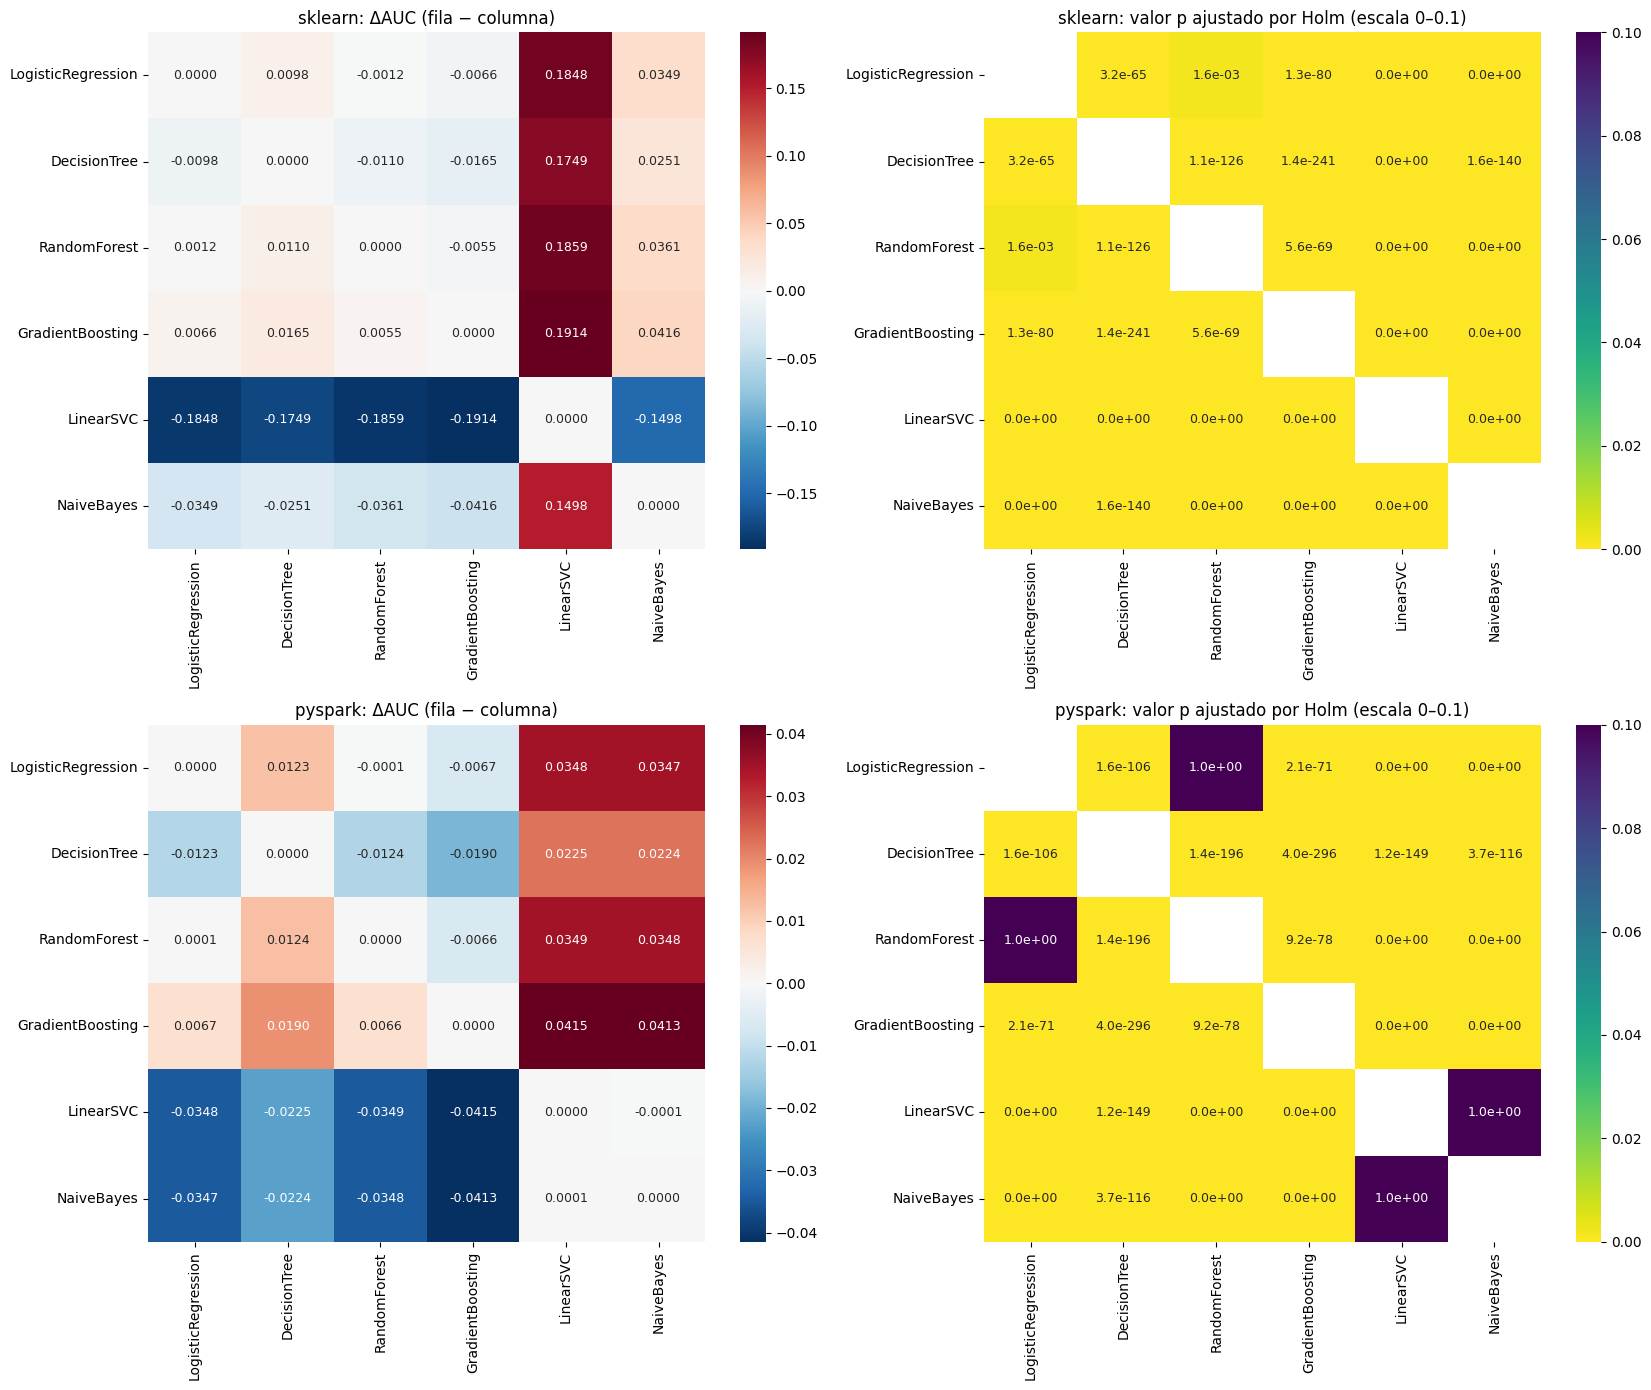

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(17, 14))  # Mapas de calor: ΔAUC y p ajustado por entorno
for fila, entorno in enumerate(["sklearn", "pyspark"]):  # Una fila por entorno
    t = dentro[entorno]  # Resultados del entorno
    delta = pd.DataFrame(0.0, index=cfg.NOMBRES_MODELOS, columns=cfg.NOMBRES_MODELOS)  # Matriz de ΔAUC (fila − columna)
    pmat = pd.DataFrame(np.nan, index=cfg.NOMBRES_MODELOS, columns=cfg.NOMBRES_MODELOS)  # Matriz de p ajustados
    for _, r in t.iterrows():  # Llena ambas matrices de forma simétrica
        delta.loc[r.modelo_1, r.modelo_2], delta.loc[r.modelo_2, r.modelo_1] = r.delta_auc, -r.delta_auc  # ΔAUC antisimétrico
        pmat.loc[r.modelo_1, r.modelo_2] = pmat.loc[r.modelo_2, r.modelo_1] = r.p_holm  # p ajustado simétrico
    sns.heatmap(delta, annot=True, fmt=".4f", cmap="RdBu_r", center=0, ax=axes[fila, 0], annot_kws={"size": 9})  # Mapa de ΔAUC
    axes[fila, 0].set_title(f"{entorno}: ΔAUC (fila − columna)")  # Título
    sns.heatmap(pmat, annot=True, fmt=".1e", cmap="viridis_r", vmin=0, vmax=0.1, ax=axes[fila, 1], annot_kws={"size": 9})  # Mapa de p ajustados
    axes[fila, 1].set_title(f"{entorno}: valor p ajustado por Holm (escala 0–0.1)")  # Título
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "05_heatmaps_delong")  # Exporta la figura
plt.show()  # Muestra la figura

## 5.3 Pruebas complementarias: McNemar y bootstrap pareado

**Umbral de decisión.** Para cada modelo se usa el umbral que maximiza F1 **en el
conjunto de entrenamiento** (calculado en los notebooks 03 y 04, sin tocar test). Con una
clase positiva del ~20 %, el umbral de 0.5 dejaría a varios modelos casi sin predecir
defaults, lo que haría la comparación de errores poco informativa.

In [9]:
met_sk = leer_json(cfg.RUTA_METRICAS_SK)["modelos"]  # Métricas y umbrales de scikit-learn
met_sp = leer_json(cfg.RUTA_METRICAS_SP)["modelos"]  # Métricas y umbrales de PySpark
umbral = {**{f"sklearn|{k}": v["umbral"] for k, v in met_sk.items()}, **{f"pyspark|{k}": v["umbral"] for k, v in met_sp.items()}}  # Umbral por modelo
top = {}  # Los dos modelos con mayor AUC de cada entorno
for entorno in ["sklearn", "pyspark"]:  # Recorre los entornos
    aucs = tabla_auc["AUC"][entorno].sort_values(ascending=False)  # AUC ordenados de mayor a menor
    top[entorno] = aucs.index[:2].tolist()  # Los dos primeros
print("Pares con mayor AUC:", top)  # Muestra los pares elegidos
pd.Series(umbral, name="umbral_train").to_frame()  # Muestra los umbrales

Pares con mayor AUC: {'sklearn': ['GradientBoosting', 'RandomForest'], 'pyspark': ['GradientBoosting', 'RandomForest']}


,umbral_train
sklearn|LogisticRegression,0.214241
sklearn|DecisionTree,0.21421
sklearn|RandomForest,0.245074
sklearn|GradientBoosting,0.214676
sklearn|LinearSVC,-1
sklearn|NaiveBayes,0.0738859
pyspark|LogisticRegression,0.212474
pyspark|DecisionTree,0.215241
pyspark|RandomForest,0.240502
pyspark|GradientBoosting,0.214045


In [10]:
comparaciones = [(f"{m}: sklearn vs PySpark", f"sklearn|{m}", f"pyspark|{m}", "entre_entornos") for m in cfg.NOMBRES_MODELOS]  # 6 comparaciones entre entornos
comparaciones += [(f"{e}: {top[e][0]} vs {top[e][1]}", f"{e}|{top[e][0]}", f"{e}|{top[e][1]}", "top2_por_entorno") for e in ["sklearn", "pyspark"]]  # 2 pares de mejores modelos
filas = []  # Resultados combinados
for nombre, c1, c2, familia in comparaciones:  # Recorre las 8 comparaciones
    s1, s2 = datos[c1].to_numpy(), datos[c2].to_numpy()  # Puntuaciones de ambos modelos
    dl = delong.prueba_delong(y, s1, s2)  # DeLong
    mc = prueba_mcnemar(y, (s1 >= umbral[c1]).astype(int), (s2 >= umbral[c2]).astype(int))  # McNemar con umbrales de train
    t0 = time.time()  # Inicio del bootstrap
    bs = bootstrap_pareado(y, s1, s2, umbral[c1], umbral[c2], B=cfg.B_BOOTSTRAP, semilla=cfg.SEMILLA)  # Bootstrap pareado
    filas.append({"comparacion": nombre, "familia": familia,  # Identificación
                  "delong_delta_auc": dl["delta_auc"], "delong_ic_inf": dl["delta_ic_inf"], "delong_ic_sup": dl["delta_ic_sup"], "delong_z": dl["z"], "delong_p": dl["p_valor"],  # DeLong
                  "mcnemar_b": mc["b"], "mcnemar_c": mc["c"], "mcnemar_chi2": mc["estadistico"], "mcnemar_p": mc["p_valor"], "mcnemar_exacta": mc["exacta"],  # McNemar
                  **{f"boot_{k}": v for k, v in bs.items()}})  # Bootstrap
    print(f"{nombre}: bootstrap en {time.time() - t0:.1f} s", flush=True)  # Progreso
comp = pd.DataFrame(filas).set_index("comparacion")  # Tabla combinada
for familia in comp["familia"].unique():  # Holm dentro de cada familia
    f = comp["familia"] == familia  # Filas de la familia
    for p in ["delong_p", "mcnemar_p", "boot_delta_auc_p", "boot_delta_auc_pr_p", "boot_delta_f1_p"]:  # Cada prueba/métrica
        comp.loc[f, p + "_holm"] = holm(comp.loc[f, p], cfg.ALFA)[0]  # Valor p ajustado por Holm

LogisticRegression: sklearn vs PySpark: bootstrap en 26.7 s


DecisionTree: sklearn vs PySpark: bootstrap en 8.8 s


RandomForest: sklearn vs PySpark: bootstrap en 27.2 s


GradientBoosting: sklearn vs PySpark: bootstrap en 28.7 s


LinearSVC: sklearn vs PySpark: bootstrap en 29.2 s


NaiveBayes: sklearn vs PySpark: bootstrap en 28.9 s


sklearn: GradientBoosting vs RandomForest: bootstrap en 29.1 s


pyspark: GradientBoosting vs RandomForest: bootstrap en 29.2 s


### Resultados detallados

In [11]:
comp[["familia", "delong_delta_auc", "delong_ic_inf", "delong_ic_sup", "delong_z", "delong_p", "delong_p_holm"]]  # DeLong

,familia,delong_delta_auc,delong_ic_inf,delong_ic_sup,delong_z,delong_p,delong_p_holm
comparacion,,,,,,,
LogisticRegression: sklearn vs PySpark,entre_entornos,-1.11431e-05,-3.39499e-05,1.16637e-05,-0.957612,0.338259,0.676517
DecisionTree: sklearn vs PySpark,entre_entornos,0.00245089,0.00149492,0.00340686,5.0249,5.03692e-07,1.51108e-06
RandomForest: sklearn vs PySpark,entre_entornos,0.00105734,0.000731372,0.00138331,6.3575,2.05068e-10,8.20271e-10
GradientBoosting: sklearn vs PySpark,entre_entornos,-4.54533e-05,-0.00043838,0.000347473,-0.226727,0.820636,0.820636
LinearSVC: sklearn vs PySpark,entre_entornos,-0.149986,-0.153423,-0.146549,-85.5268,0,0
NaiveBayes: sklearn vs PySpark,entre_entornos,-0.00030454,-0.000359848,-0.000249232,-10.7921,3.75161e-27,1.87581e-26
sklearn: GradientBoosting vs RandomForest,top2_por_entorno,0.00545408,0.00484726,0.0060609,17.6161,1.85286e-69,1.85286e-69
pyspark: GradientBoosting vs RandomForest,top2_por_entorno,0.00655687,0.00587114,0.00724261,18.7409,2.29811e-78,4.59623e-78


In [12]:
comp[["mcnemar_b", "mcnemar_c", "mcnemar_chi2", "mcnemar_exacta", "mcnemar_p", "mcnemar_p_holm"]]  # McNemar

,mcnemar_b,mcnemar_c,mcnemar_chi2,mcnemar_exacta,mcnemar_p,mcnemar_p_holm
comparacion,,,,,,
LogisticRegression: sklearn vs PySpark,1135,319,456.826,False,2.35838e-101,9.43353e-101
DecisionTree: sklearn vs PySpark,18549,11787,1506.83,False,0,0
RandomForest: sklearn vs PySpark,5413,3812,277.507,False,2.62374e-62,7.87123e-62
GradientBoosting: sklearn vs PySpark,5555,6250,40.7993,False,1.68692e-10,3.37383e-10
LinearSVC: sklearn vs PySpark,16471,119601,78161.5,False,0,0
NaiveBayes: sklearn vs PySpark,742,797,1.89474,False,0.168669,0.168669
sklearn: GradientBoosting vs RandomForest,7457,18142,4459.07,False,0,0
pyspark: GradientBoosting vs RandomForest,8838,17227,2699.35,False,0,0


In [13]:
comp[[c for c in comp.columns if c.startswith("boot_")]].T  # Bootstrap pareado (ΔAUC, ΔAUC-PR, ΔF1)

comparacion,LogisticRegression: sklearn vs PySpark,DecisionTree: sklearn vs PySpark,RandomForest: sklearn vs PySpark,GradientBoosting: sklearn vs PySpark,LinearSVC: sklearn vs PySpark,NaiveBayes: sklearn vs PySpark,sklearn: GradientBoosting vs RandomForest,pyspark: GradientBoosting vs RandomForest
boot_delta_auc,-1.07829e-05,0.00246193,0.00105299,-4.08004e-05,-0.149985,-0.000304166,0.00545803,0.00655182
boot_delta_auc_ic_inf,-3.35031e-05,0.00147575,0.000739802,-0.000424747,-0.153389,-0.000359262,0.0048622,0.00586054
boot_delta_auc_ic_sup,1.16176e-05,0.00339225,0.00138226,0.000331819,-0.146624,-0.000248693,0.00609944,0.00725128
boot_delta_auc_difiere,False,True,True,False,True,True,True,True
boot_delta_auc_p,0.361,0.0005,0.0005,0.823,0.0005,0.0005,0.0005,0.0005
boot_delta_auc_pr,-0.000145269,0.00445726,0.00078234,0.000226047,-0.103054,-0.000720251,0.00810916,0.00866545
boot_delta_auc_pr_ic_inf,-0.000202581,0.00248761,7.54609e-05,-0.000679186,-0.106309,-0.000853549,0.00681018,0.00725075
boot_delta_auc_pr_ic_sup,-8.73936e-05,0.00629229,0.00154232,0.00115919,-0.0998786,-0.000594301,0.00939243,0.0100543
boot_delta_auc_pr_difiere,True,True,True,False,True,True,True,True
boot_delta_auc_pr_p,0.0005,0.0005,0.037,0.638,0.0005,0.0005,0.0005,0.0005


### 5.4 Tabla resumen de las tres pruebas

In [14]:
def veredicto(p, alfa=cfg.ALFA):  # Traduce un valor p ajustado a texto
    return "difiere" if p < alfa else "no difiere"  # Decisión al 5 %

resumen = pd.DataFrame({  # Una fila por comparación
    "ΔAUC": comp["delong_delta_auc"],  # Diferencia de AUC
    "IC95 ΔAUC (DeLong)": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["delong_ic_inf"], comp["delong_ic_sup"])],  # IC de DeLong
    "DeLong (p Holm)": comp["delong_p_holm"],  # p ajustado de DeLong
    "DeLong": comp["delong_p_holm"].map(veredicto),  # Decisión de DeLong
    "Relevante |ΔAUC|≥0.005": comp["delong_delta_auc"].abs() >= cfg.MARGEN_RELEVANCIA_AUC,  # Relevancia práctica
    "McNemar (p Holm)": comp["mcnemar_p_holm"],  # p ajustado de McNemar
    "McNemar": comp["mcnemar_p_holm"].map(veredicto),  # Decisión de McNemar
    "Boot ΔAUC IC95": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["boot_delta_auc_ic_inf"], comp["boot_delta_auc_ic_sup"])],  # IC bootstrap de ΔAUC
    "Boot ΔAUC-PR IC95": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["boot_delta_auc_pr_ic_inf"], comp["boot_delta_auc_pr_ic_sup"])],  # IC bootstrap de ΔAUC-PR
    "Boot ΔF1 IC95": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["boot_delta_f1_ic_inf"], comp["boot_delta_f1_ic_sup"])],  # IC bootstrap de ΔF1
    "Boot ΔAUC": comp["boot_delta_auc_p_holm"].map(veredicto),  # Decisión bootstrap AUC
    "Boot ΔAUC-PR": comp["boot_delta_auc_pr_p_holm"].map(veredicto),  # Decisión bootstrap AUC-PR
    "Boot ΔF1": comp["boot_delta_f1_p_holm"].map(veredicto),  # Decisión bootstrap F1
})
resumen["DeLong = Boot (AUC)"] = resumen["DeLong"] == resumen["Boot ΔAUC"]  # ¿Coinciden DeLong y bootstrap para el AUC?
resumen  # Muestra la tabla resumen

,ΔAUC,IC95 ΔAUC (DeLong),DeLong (p Holm),DeLong,Relevante |ΔAUC|≥0.005,McNemar (p Holm),McNemar,Boot ΔAUC IC95,Boot ΔAUC-PR IC95,Boot ΔF1 IC95,Boot ΔAUC,Boot ΔAUC-PR,Boot ΔF1,DeLong = Boot (AUC)
comparacion,,,,,,,,,,,,,,
LogisticRegression: sklearn vs PySpark,-1.11431e-05,"[-0.0000, 0.0000]",0.676517,no difiere,False,9.43353e-101,difiere,"[-0.0000, 0.0000]","[-0.0002, -0.0001]","[-0.0002, 0.0006]",no difiere,difiere,no difiere,True
DecisionTree: sklearn vs PySpark,0.00245089,"[0.0015, 0.0034]",1.51108e-06,difiere,False,0,difiere,"[0.0015, 0.0034]","[0.0025, 0.0063]","[0.0014, 0.0050]",difiere,difiere,difiere,True
RandomForest: sklearn vs PySpark,0.00105734,"[0.0007, 0.0014]",8.20271e-10,difiere,False,7.87123e-62,difiere,"[0.0007, 0.0014]","[0.0001, 0.0015]","[-0.0007, 0.0016]",difiere,no difiere,no difiere,True
GradientBoosting: sklearn vs PySpark,-4.54533e-05,"[-0.0004, 0.0003]",0.820636,no difiere,False,3.37383e-10,difiere,"[-0.0004, 0.0003]","[-0.0007, 0.0012]","[-0.0006, 0.0016]",no difiere,no difiere,no difiere,True
LinearSVC: sklearn vs PySpark,-0.149986,"[-0.1534, -0.1465]",0,difiere,True,0,difiere,"[-0.1534, -0.1466]","[-0.1063, -0.0999]","[-0.0724, -0.0682]",difiere,difiere,difiere,True
NaiveBayes: sklearn vs PySpark,-0.00030454,"[-0.0004, -0.0002]",1.87581e-26,difiere,False,0.168669,no difiere,"[-0.0004, -0.0002]","[-0.0009, -0.0006]","[-0.0008, -0.0001]",difiere,difiere,difiere,True
sklearn: GradientBoosting vs RandomForest,0.00545408,"[0.0048, 0.0061]",1.85286e-69,difiere,True,0,difiere,"[0.0049, 0.0061]","[0.0068, 0.0094]","[0.0068, 0.0103]",difiere,difiere,difiere,True
pyspark: GradientBoosting vs RandomForest,0.00655687,"[0.0059, 0.0072]",4.59623e-78,difiere,True,0,difiere,"[0.0059, 0.0073]","[0.0073, 0.0101]","[0.0069, 0.0104]",difiere,difiere,difiere,True


In [15]:
comp.to_csv(cfg.DIR_SALIDAS / "comparaciones_complementarias.csv")  # Guarda la tabla combinada
fam1.to_csv(cfg.DIR_SALIDAS / "delong_entre_entornos.csv")  # Guarda la familia 1
for entorno, t in dentro.items():  # Guarda la familia 2 de cada entorno
    t.to_csv(cfg.DIR_SALIDAS / f"delong_dentro_{entorno}.csv", index=False)  # Un CSV por entorno
tabla_auc.to_csv(cfg.DIR_SALIDAS / "auc_ic95.csv")  # Guarda los AUC con IC
print("Resultados guardados en", cfg.DIR_SALIDAS)  # Confirma el guardado

Resultados guardados en C:\Users\user-pc\Documents\DanielSerranoRomero\Maestría\MachineLearning\Projects\proyecto_integrador_ml\outputs


## 5.2 Interpretación y limitaciones

**Validación.** La versión rápida de DeLong coincide con la directa hasta el error de redondeo
(|ΔAUC| ≈ 1e-16, |Δcov| ≈ 1e-19) tanto en datos sintéticos con empates como en 3.000
observaciones reales; además, sus AUC coinciden con `roc_auc_score`.

**Familia 1 – mismo modelo en ambos entornos (Holm, α = 0,05).**

| Modelo | ΔAUC (sklearn − PySpark) | p Holm | ¿Significativa? | ¿Relevante (≥ 0,005)? |
|---|---|---|---|---|
| Regresión logística | −0,00001 | 0,68 | No | No |
| Árbol de decisión | +0,0025 | < 0,001 | Sí | No |
| Bosque aleatorio | +0,0011 | < 0,001 | Sí | No |
| *Gradient boosting* | −0,00005 | 0,82 | No | No |
| LinearSVC | −0,150 | < 0,001 | Sí | **Sí** |
| Naive Bayes | −0,0003 | < 0,001 | Sí | No |

Regresión logística y *gradient boosting* son **estadísticamente indistinguibles** entre
entornos. En árbol, bosque y Naive Bayes las diferencias son significativas pero diminutas
(≤ 0,0025, la mitad del margen de relevancia): con 269 mil observaciones y curvas ROC muy
correlacionadas, el error estándar de ΔAUC es del orden de 0,0001–0,0005, así que la prueba
detecta diferencias sin importancia práctica. Solo LinearSVC difiere de forma relevante.

**Familia 2 – pares dentro de cada entorno.** En scikit-learn los 15 pares difieren tras
Holm; en PySpark 13 de 15 (no difieren regresión logística vs bosque, p = 1, ni LinearSVC vs
Naive Bayes, p = 1). Con el margen de relevancia, el orden práctico es el mismo en ambos
entornos: **boosting** (mejor que todos por ≥ 0,0055) > **bosque ≈ logística** (diferencia
≤ 0,0012, irrelevante) > **árbol** > **Naive Bayes** (≈ LinearSVC en PySpark); LinearSVC de
scikit-learn es el último.

**Pruebas complementarias (8 comparaciones).**
* **Bootstrap vs DeLong (AUC):** coinciden en las 8 comparaciones, y los intervalos son
  prácticamente idénticos (p. ej., bosque: DeLong [0,0007; 0,0014], bootstrap [0,0007;
  0,0014]). Es lo esperable: con n grande la aproximación normal de DeLong es excelente.
* **AUC-PR y F1 (bootstrap):** cuentan una historia algo distinta. En la regresión logística el
  AUC-PR difiere (−0,00015, irrelevante) aunque el AUC no; en el bosque el AUC-PR deja de ser
  significativo tras Holm (p = 0,074) y el F1 no difiere. Entre los mejores modelos de cada
  entorno, el boosting supera al bosque en las tres métricas (ΔAUC-PR ≈ +0,008; ΔF1 ≈ +0,009).
* **McNemar:** declara diferencias en casi todas las comparaciones, incluso donde DeLong no las
  ve (regresión logística: b = 1.135, c = 319; boosting: 5.555 vs 6.250). La razón es que compara
  **decisiones** con umbrales elegidos por separado en cada entorno (0,2142 vs 0,2125 en la
  logística): un corrimiento mínimo del umbral cambia la decisión de miles de préstamos cercanos
  a la frontera sin alterar la ordenación. En Naive Bayes ocurre lo contrario: DeLong detecta
  una diferencia ínfima de ordenación, pero las decisiones coinciden (p = 0,17).
* **Boosting vs bosque (McNemar):** hay **más** casos en que acierta el bosque y falla el
  boosting (18.142) que al revés (7.457), a pesar de que el boosting tiene mejor AUC, AUC-PR y
  F1. El umbral del bosque (0,245) es más alto, así que predice menos defaults: comete menos
  falsos positivos (clase mayoritaria) y más falsos negativos. McNemar cuenta todos los errores
  por igual, y con una clase minoritaria del 20 % eso favorece al modelo más conservador aunque
  detecte menos defaults. Es exactamente la limitación que pide discutir la sección 5.3.

**Limitaciones de la prueba de DeLong en este diseño.**
1. Solo captura la variabilidad del **muestreo del conjunto de prueba**. No incluye la
   variabilidad del entrenamiento (semillas, pliegues de la validación cruzada, aleatoriedad del
   bosque): otra semilla podría mover los AUC más que las diferencias entre entornos detectadas.
2. Supone observaciones independientes; los préstamos de un mismo periodo o región comparten
   condiciones económicas, así que el error estándar real puede ser mayor.
3. El AUC resume todos los umbrales; en la operación solo importa uno. Dos modelos con igual AUC
   pueden tomar decisiones distintas (regresión logística y boosting entre entornos, según
   McNemar) y un modelo con mejor AUC puede cometer más errores totales en su umbral
   (boosting vs bosque).
4. Con n ≈ 269 mil, la significancia estadística es casi automática: por eso se fijó de antemano
   el margen de relevancia |ΔAUC| ≥ 0,005 (1 punto de Gini).

---

# 6. Interpretabilidad con LIME

Sección 5.5 del enunciado. Se explica el modelo con mayor AUC de cada entorno **entre los
que entregan probabilidades** (LinearSVC queda excluido) sobre dos instancias de test
**mal clasificadas por ambos modelos**: un falso negativo y un falso positivo (con el umbral
elegido en train).

**Espacio de explicación.** LIME perturba las variables *originales* (antes de escalar y
codificar) para que las explicaciones sean legibles: montos en dólares, tasa en %,
categorías con su nombre. La función de predicción aplica internamente el preprocesamiento
ajustado con train y luego el modelo. En `mths_since_last_delinq`, `emp_length_anios` y
`mort_acc` el valor −1 representa "dato faltante" (informativo según el EDA) y se
reconvierte a nulo antes de predecir.

**Explicaciones de PySpark.** Se generaron al final del notebook 04, con el modelo ganador
todavía vivo en la sesión de Spark (ver allí la justificación). Aquí se cargan y se
comparan con las de scikit-learn, calculadas con el **mismo explicador, las mismas
instancias y la misma semilla** (por tanto, las mismas 2.000 perturbaciones).

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos
import joblib  # Carga del modelo y de los transformadores de scikit-learn
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
from IPython.display import Image, display  # Muestra figuras guardadas
from src import config as cfg  # Configuración central
from src import lime_utils  # Utilidades de LIME compartidas con el notebook 04
from src import preparacion as prep  # Transformaciones con pandas
from src.utilidades import guardar_figura, leer_json  # Utilidades

lime_sp = leer_json(lime_utils.RUTA_EXPLICACIONES_SP)  # Explicaciones de PySpark (notebook 04)
met_sk = leer_json(cfg.RUTA_METRICAS_SK)["modelos"]  # Métricas de scikit-learn
met_sp = leer_json(cfg.RUTA_METRICAS_SP)["modelos"]  # Métricas de PySpark
mejor_sk, mejor_sp = lime_sp["mejor_sklearn"], lime_sp["mejor_pyspark"]  # Modelos explicados
instancias = lime_sp["instancias"]  # Instancias elegidas en el notebook 04
print(f"scikit-learn → {mejor_sk} (AUC {met_sk[mejor_sk]['metricas']['roc_auc']:.4f}, umbral {met_sk[mejor_sk]['umbral']:.3f})")  # Modelo elegido
print(f"PySpark      → {mejor_sp} (AUC {met_sp[mejor_sp]['metricas']['roc_auc']:.4f}, umbral {met_sp[mejor_sp]['umbral']:.3f})")  # Modelo elegido
print(f"Falsos negativos comunes: {lime_sp['n_fn_comunes']:,} | falsos positivos comunes: {lime_sp['n_fp_comunes']:,}")  # Tamaño de cada grupo
print("Instancias explicadas:", instancias)  # Identificadores

scikit-learn → GradientBoosting (AUC 0.7207, umbral 0.215)
PySpark      → GradientBoosting (AUC 0.7208, umbral 0.214)
Falsos negativos comunes: 18,480 | falsos positivos comunes: 62,896
Instancias explicadas: {'Falso negativo': 101230150, 'Falso positivo': 2826869}


## Función de predicción de scikit-learn

In [2]:
espacio = lime_utils.EspacioLime()  # Datos en el espacio original y conversiones
tr = joblib.load(cfg.DIR_SKLEARN_PREP / "transformadores.joblib")  # Transformadores ajustados con train (notebook 02)
modelo_sk = joblib.load(cfg.DIR_MODELOS_SK / f"{mejor_sk}.joblib")  # Mejor modelo de scikit-learn (notebook 03)


def predecir_sk(X):  # Función de predicción que LIME llamará con cada lote de perturbaciones
    d = prep.transformar_numericas(espacio.desde_lime(X))  # Espacio original + log1p + indicadores de nulo
    num = tr["escalador"].transform(tr["imputador"].transform(d[tr["numericas"]]))  # Imputa y escala con parámetros de train
    cat = tr["codificador"].transform(d[cfg.CATEGORICAS_MODELO])  # One-hot con las categorías de train
    return modelo_sk.predict_proba(np.hstack([num, cat]).astype(np.float32))  # Probabilidades [P(0), P(1)]


verif = predecir_sk(espacio.a_lime(espacio.test.iloc[:2000]))[:, 1]  # Verificación sobre 2.000 filas de test
guardadas = pd.read_parquet(cfg.DIR_SCORES_SK / f"{mejor_sk}.parquet").set_index(cfg.COL_ID).loc[espacio.test[cfg.COL_ID].iloc[:2000], "score"].to_numpy()  # Puntuaciones del notebook 03
print(f"Máx. diferencia con las puntuaciones del notebook 03: {np.abs(verif - guardadas).max():.2e}")  # ≈ 0

Máx. diferencia con las puntuaciones del notebook 03: 0.00e+00


C:\Users\user-pc\.conda\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _winapi.Create

## Instancias explicadas (valores originales)

In [3]:
t = espacio.test.set_index(cfg.COL_ID).loc[list(instancias.values()), lime_utils.VARIABLES + [cfg.COL_TARGET]].T  # Valores originales
t.columns = [f"{k} (id {v})" for k, v in instancias.items()]  # Encabezados descriptivos
t  # Muestra la tabla

,Falso negativo (id 101230150),Falso positivo (id 2826869)
loan_amnt,15775.0,9750.0
term_meses,36.0,36.0
int_rate,11.49,17.77
annual_inc,65000.0,30000.0
dti,19.43,20.92
fico_range_high,704.0,679.0
emp_length_anios,0.0,5.0
delinq_2yrs,0.0,0.0
inq_last_6mths,0.0,1.0
open_acc,29.0,8.0


## Explicaciones locales de scikit-learn

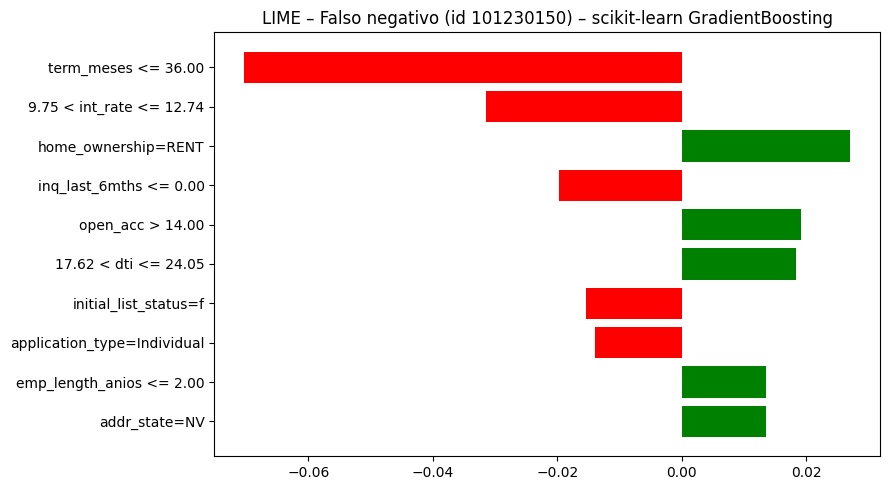

Falso negativo: P(default)=0.156  R² local=0.175  tiempo=3.53s


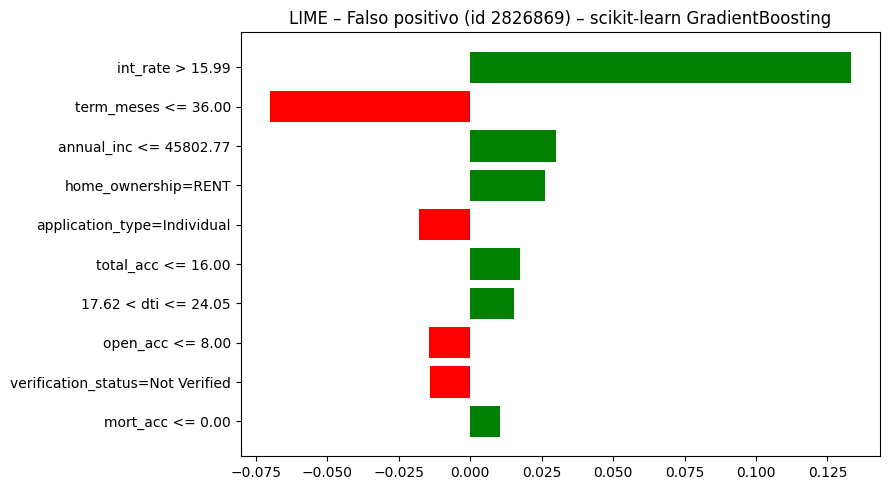

Falso positivo: P(default)=0.341  R² local=0.525  tiempo=3.49s


In [4]:
explicaciones_sk = {}  # Explicaciones de scikit-learn por instancia
for etiqueta, id_ in instancias.items():  # Recorre las dos instancias
    t0 = time.time()  # Inicio de la explicación
    exp = espacio.explicador().explain_instance(espacio.instancia(id_), predecir_sk, num_features=lime_utils.N_VARIABLES, num_samples=lime_utils.N_MUESTRAS)  # Explicación local
    explicaciones_sk[etiqueta] = {"exp": exp, "tiempo_s": time.time() - t0}  # Guarda la explicación y el tiempo
    fig = exp.as_pyplot_figure(label=1); fig.set_size_inches(9, 5)  # Pesos hacia "Charged Off"
    plt.title(f"LIME – {etiqueta} (id {id_}) – scikit-learn {mejor_sk}"); plt.tight_layout()  # Título
    guardar_figura(fig, f"06_lime_{etiqueta.replace(' ', '_')}_sklearn"); plt.show()  # Exporta y muestra
    print(f"{etiqueta}: P(default)={exp.predict_proba[1]:.3f}  R² local={exp.score:.3f}  tiempo={time.time() - t0:.2f}s")  # Resumen

In [5]:
for etiqueta in instancias:  # Visualización HTML interactiva de LIME (valores + contribuciones)
    print(f"{etiqueta} – scikit-learn")  # Encabezado
    explicaciones_sk[etiqueta]["exp"].show_in_notebook(show_table=True)  # Tabla y barras de LIME

Falso negativo – scikit-learn


Falso positivo – scikit-learn


## Explicaciones locales de PySpark (generadas en el notebook 04)

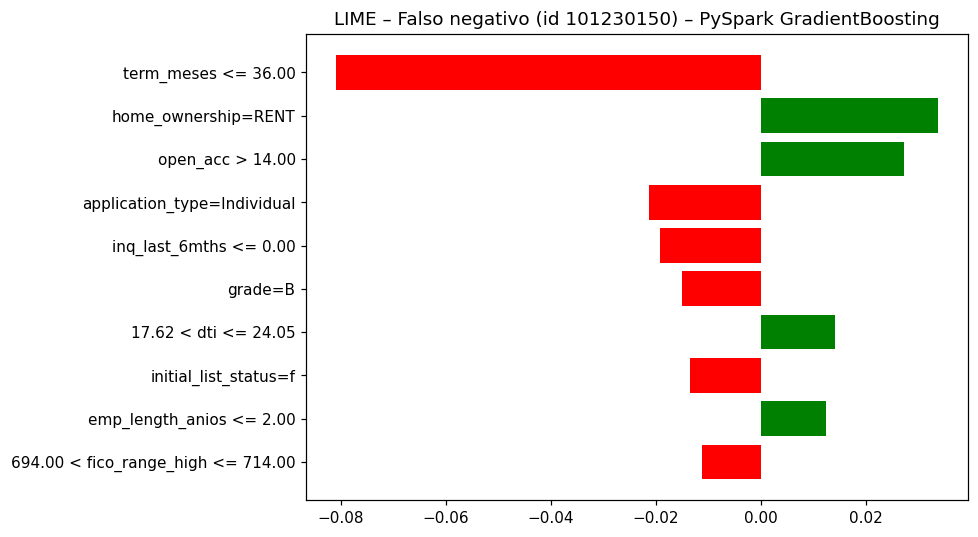

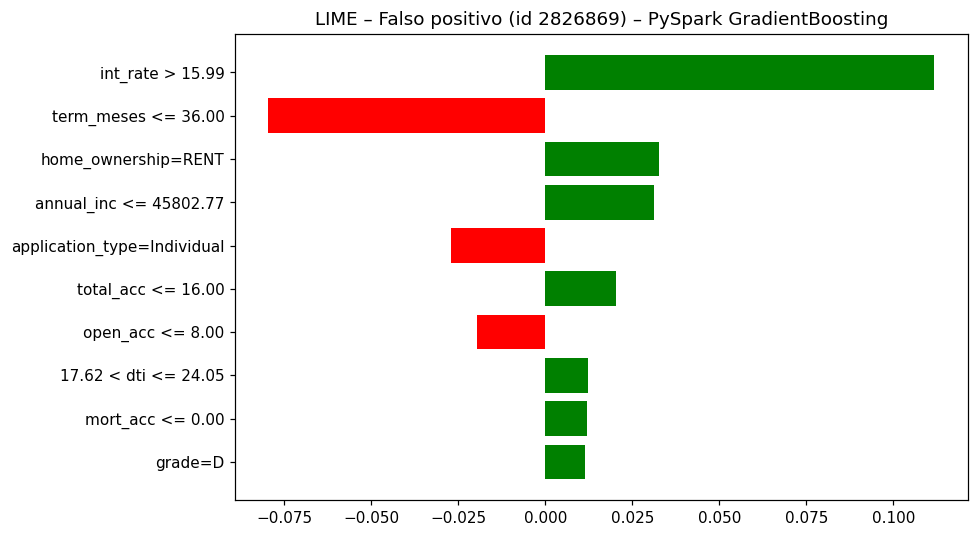

In [6]:
for etiqueta in instancias:  # Figuras exportadas en el notebook 04
    display(Image(filename=str(cfg.DIR_FIGURAS / f"04_lime_{etiqueta.replace(' ', '_')}_pyspark.png")))  # Muestra la figura

## Comparación entre entornos

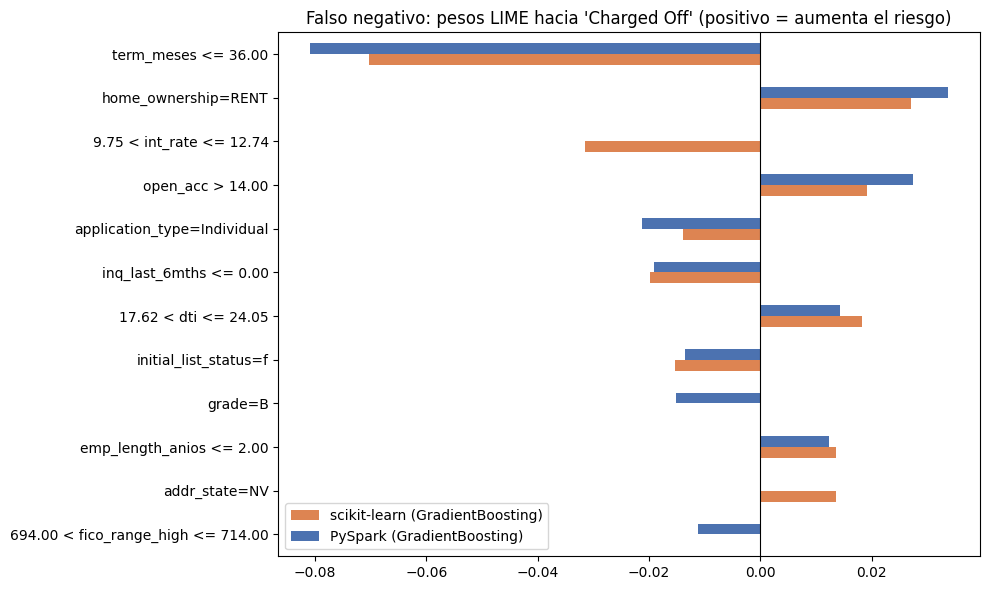

,scikit-learn (GradientBoosting),PySpark (GradientBoosting)
term_meses <= 36.00,-0.070237,-0.080811
home_ownership=RENT,0.026968,0.033717
9.75 < int_rate <= 12.74,-0.031404,NaN
open_acc > 14.00,0.019131,0.027334
application_type=Individual,-0.013917,-0.021223
inq_last_6mths <= 0.00,-0.019780,-0.019138
17.62 < dti <= 24.05,0.018321,0.014213
initial_list_status=f,-0.015412,-0.013503
grade=B,NaN,-0.015096
emp_length_anios <= 2.00,0.013580,0.012334


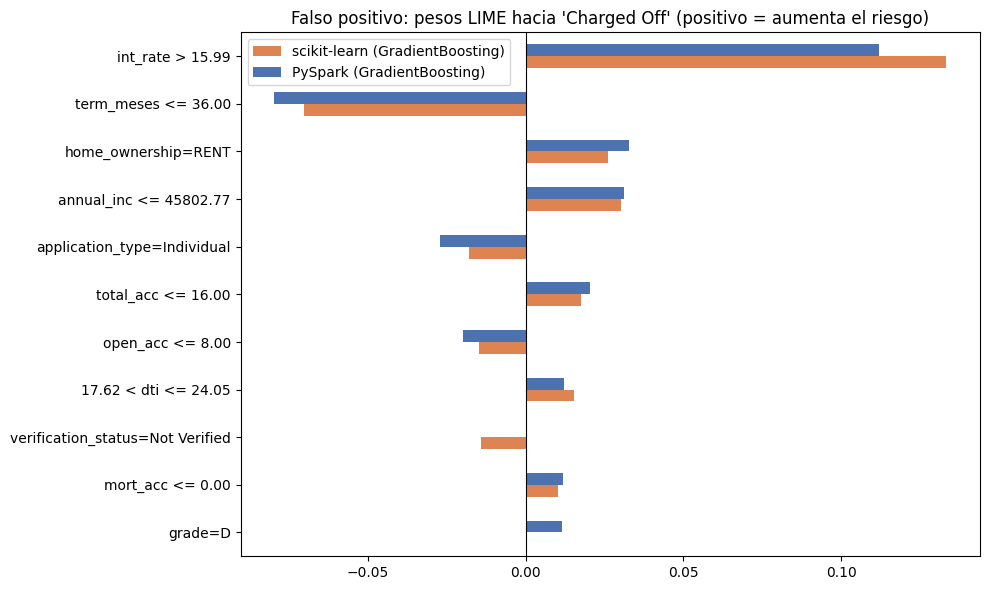

,scikit-learn (GradientBoosting),PySpark (GradientBoosting)
int_rate > 15.99,0.133213,0.111797
term_meses <= 36.00,-0.070213,-0.079549
home_ownership=RENT,0.026093,0.032651
annual_inc <= 45802.77,0.030061,0.031177
application_type=Individual,-0.017898,-0.027006
total_acc <= 16.00,0.017501,0.020318
open_acc <= 8.00,-0.014586,-0.019715
17.62 < dti <= 24.05,0.015199,0.012227
verification_status=Not Verified,-0.014056,NaN
mort_acc <= 0.00,0.010326,0.012013


In [7]:
for etiqueta in instancias:  # Una comparación por instancia
    pesos = pd.DataFrame({  # Pesos por condición en ambos entornos
        f"scikit-learn ({mejor_sk})": dict(explicaciones_sk[etiqueta]["exp"].as_list(label=1)),  # Pesos de scikit-learn
        f"PySpark ({mejor_sp})": dict((c, w) for c, w in lime_sp["explicaciones"][etiqueta]["pesos"]),  # Pesos de PySpark
    })
    pesos = pesos.reindex(pesos.abs().max(axis=1).sort_values().index)  # Ordena por importancia
    ax = pesos.plot.barh(figsize=(10, 6), color=["#DD8452", "#4C72B0"])  # Barras agrupadas
    ax.axvline(0, color="black", lw=0.8)  # Línea en cero
    ax.set_title(f"{etiqueta}: pesos LIME hacia 'Charged Off' (positivo = aumenta el riesgo)")  # Título
    plt.tight_layout(); guardar_figura(ax.figure, f"06_lime_comparacion_{etiqueta.replace(' ', '_')}"); plt.show()  # Exporta y muestra
    display(pesos.iloc[::-1])  # Tabla de pesos (más importante primero)

In [8]:
resumen = pd.DataFrame([  # Probabilidad, ajuste local y costo de cada explicación
    {"instancia": e, "entorno": "scikit-learn", "P(default)": explicaciones_sk[e]["exp"].predict_proba[1],  # scikit-learn
     "R² local": explicaciones_sk[e]["exp"].score, "tiempo (s)": explicaciones_sk[e]["tiempo_s"]} for e in instancias] + [  # Métricas
    {"instancia": e, "entorno": "PySpark", "P(default)": lime_sp["explicaciones"][e]["p_default"],  # PySpark
     "R² local": lime_sp["explicaciones"][e]["r2_local"], "tiempo (s)": lime_sp["explicaciones"][e]["tiempo_s"]} for e in instancias])  # Métricas
print(f"PySpark: {lime_sp['n_llamadas']} llamadas al modelo, {lime_sp['tiempo_medio_llamada_s']:.2f} s por llamada en promedio")  # Costo por llamada
resumen.set_index(["instancia", "entorno"])  # Muestra la tabla

PySpark: 3 llamadas al modelo, 0.57 s por llamada en promedio


,,P(default),R² local,tiempo (s)
instancia,entorno,,,
Falso negativo,scikit-learn,0.156228,0.175248,3.323424
Falso positivo,scikit-learn,0.341288,0.525030,3.272462
Falso negativo,PySpark,0.139924,0.195292,3.845228
Falso positivo,PySpark,0.299095,0.441838,3.756416


## Discusión: qué aporta LIME y sus limitaciones en entornos distribuidos

**Las explicaciones.** En ambos entornos el mejor modelo probabilístico es *gradient
boosting* (AUC 0,7207 / 0,7208).

* **Falso negativo (id 101230150, sí hizo default):** grado B, tasa de 11,49 %, plazo de 36 meses,
  FICO 704 y utilización revolvente del 24 %. Es un perfil de bajo riesgo, y ambos modelos le
  asignan P(default) ≈ 0,14–0,16, por debajo del umbral (≈ 0,21). Según LIME, lo que más reduce el
  riesgo es el **plazo de 36 meses** (−0,07 / −0,08) y la tasa baja; empujan hacia arriba el
  alquiler de vivienda (`RENT`, +0,03), tener muchas líneas abiertas (`open_acc` > 14) y un `dti`
  de 17–24. El préstamo terminó en default por causas que los datos de originación no recogen
  (un evento posterior), así que el error es esperable.
* **Falso positivo (id 2826869, sí pagó):** grado D, tasa de 17,77 %, ingreso de 30 mil, FICO
  679, un registro público y una quiebra. P(default) ≈ 0,30–0,34, por encima del umbral. La
  variable dominante es **`int_rate` > 15,99** (+0,13 / +0,11), seguida del ingreso bajo y el
  alquiler, compensados parcialmente por el plazo de 36 meses.
* **Consistencia entre entornos:** las variables principales y sus signos coinciden en ambos
  modelos, con magnitudes parecidas; solo cambian las variables en las posiciones 9–10 (grado,
  estado, FICO). Esto confirma que los dos *boosting* aprendieron prácticamente la misma función.

**Qué aporta LIME.** Traduce una predicción individual de un modelo de caja negra a unas pocas
reglas legibles ("plazo ≤ 36 meses reduce el riesgo en 7 puntos"), útiles para justificar
decisiones de crédito, detectar dependencias indeseadas (p. ej., por estado de residencia) y
comparar modelos entre entornos, como aquí.

**Limitaciones generales.** (1) Es **local e inestable**: otra semilla o número de
perturbaciones cambia los pesos, sobre todo los pequeños. (2) El R² local es bajo en el falso
negativo (0,18–0,20): el sustituto lineal explica poco del modelo en ese entorno. (3) Perturba
cada variable **de forma independiente**, lo que genera combinaciones irreales (tasa de 6 % con
grado F). (4) La discretización en cuartiles es arbitraria y cambia el significado de los pesos.

**Limitaciones en entornos distribuidos (PySpark).**
1. LIME trabaja **en memoria local**: necesita en el driver un conjunto de entrenamiento para
   calcular cuartiles y frecuencias, lo que choca con la filosofía de no llevar datos al driver.
2. Cada lote de perturbaciones debe **viajar a la JVM**, convertirse en DataFrame, pasar por el
   pipeline y volver. Sin Arrow (incompatible con Java 21 en Spark 3.5), crear el DataFrame
   desde pandas tardaba ≈ 250 s por llamada; escribiendo Parquet se redujo a ≈ 0,6 s, pero
   cada llamada sigue lanzando varios trabajos de Spark. Explicar miles de instancias sería caro.
3. El modelo debe estar **vivo en la sesión**: en Windows sin `winutils` no se pudo guardar, y
   reajustarlo en otra sesión no reproducía exactamente el modelo del `CrossValidator`.
4. La explicación es de un solo préstamo; para una visión global habría que agregar muchas
   explicaciones, lo que multiplica los costos anteriores.

---

# 7. Comparación de resultados y reflexión crítica

Sección 5.6 y entregable (sección 6) del enunciado: tabla comparativa de métricas y
tiempos, curvas ROC por entorno, comparación de tiempos, mapas de calor de DeLong,
resumen de las tres pruebas estadísticas, un experimento auxiliar de escalabilidad y la
reflexión crítica final.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
from IPython.display import Image, display  # Muestra figuras guardadas
from sklearn.metrics import roc_curve  # Curva ROC
from src import config as cfg  # Configuración central
from src.utilidades import guardar_figura, info_hardware, leer_json  # Utilidades

pd.set_option("display.float_format", lambda x: f"{x:.4f}")  # Formato numérico
pd.set_option("display.max_columns", 40)  # Muestra hasta 40 columnas
pd.set_option("display.width", 250)  # Ancho de impresión
met = {"scikit-learn": leer_json(cfg.RUTA_METRICAS_SK)["modelos"], "PySpark": leer_json(cfg.RUTA_METRICAS_SP)["modelos"]}  # Métricas de ambos entornos
prep_t = leer_json(cfg.RUTA_TIEMPOS_PREP)  # Tiempos de preprocesamiento
info_hardware()  # Hardware utilizado

{'sistema': 'Windows 10',
 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD',
 'nucleos_fisicos': 6,
 'nucleos_logicos': 12,
 'ram_total_gb': 13.8,
 'ram_disponible_gb': 6.1,
 'python': '3.9.25'}

## Tabla comparativa de métricas (test, umbral por defecto) y F1 con el umbral elegido en train

In [2]:
filas = []  # Una fila por modelo y entorno
for entorno, m in met.items():  # Recorre los entornos
    for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        r = m[modelo]  # Resultados del modelo
        filas.append({"modelo": modelo, "entorno": entorno,  # Identificación
                      **{k: r["metricas"][k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},  # Métricas con umbral por defecto
                      "f1_umbral_train": r["metricas_umbral"]["f1"], "recall_umbral_train": r["metricas_umbral"]["recall"],  # Métricas con umbral de train
                      "mejores_parametros": str(r["mejores_parametros"])})  # Hiperparámetros ganadores
metr = pd.DataFrame(filas).set_index(["modelo", "entorno"]).sort_index(level=0, key=lambda s: s.map(cfg.NOMBRES_MODELOS.index))  # Tabla ordenada
metr  # Muestra la tabla

accuracy  precision  recall     f1  roc_auc  f1_umbral_train  recall_umbral_train                      mejores_parametros
modelo             entorno                                                                                                                                
LogisticRegression PySpark         0.8028     0.5515  0.0647 0.1158   0.7141           0.4309               0.6361                     {'regParam': 1e-05}
                   scikit-learn    0.8028     0.5522  0.0641 0.1149   0.7141           0.4311               0.6308             {'C': 0.009291538753149831}
DecisionTree       PySpark         0.8013     0.5185  0.0629 0.1122   0.7018           0.4202               0.6476                        {'maxDepth': 10}
                   scikit-learn    0.8016     0.5239  0.0659 0.1171   0.7043           0.4234               0.6101                       {'max_depth': 10}
RandomForest       PySpark         0.8027     0.5807  0.0422 0.0786   0.7142           0.4287               0.5486       {'numTrees': 100, 'maxDepth': 15}
                   scikit-learn    0.8026     0.5802  0.0408 0.0762   0.7153           0.4292               0.5385  {'max_depth': 15, 'n_estimators': 100}
GradientBoosting   PySpark         0.8039     0.5562  0.0874 0.1510   0.7208           0.4373               0.6288         {'maxIter': 100, 'maxDepth': 5}
                   scikit-learn    0.8039     0.5710  0.0704 0.1254   0.7207           0.4377               0.6351       {'max_depth': 5, 'max_iter': 100}
LinearSVC          PySpark         0.8004     0.0000  0.0000 0.0000   0.6793           0.4027               0.6994                     {'regParam': 1e-05}
                   scikit-learn    0.8003     0.4924  0.0162 0.0314   0.5293           0.3325               0.9949               {'C': 0.9291538753149833}
NaiveBayes         PySpark         0.7203     0.3425  0.4365 0.3838   0.6795           0.4100               0.6560                                      {}
                   scikit-learn    0.7206     0.3425  0.4344 0.3830   0.6792           0.4095               0.6551                                      {}

## Tiempos de cómputo por modelo y entorno (segundos)

In [3]:
filas = []  # Una fila por modelo y entorno
for entorno, m in met.items():  # Recorre los entornos
    clave = "sklearn" if entorno == "scikit-learn" else "pyspark"  # Clave en el JSON de preprocesamiento
    for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        r = m[modelo]  # Resultados del modelo
        filas.append({"modelo": modelo, "entorno": entorno,  # Identificación
                      "preprocesamiento (común)": prep_t[clave]["total"],  # Tiempo de preprocesamiento del entorno
                      "entrenamiento + CV": r["tiempo_entrenamiento_s"],  # Tiempo de entrenamiento con validación cruzada
                      "predicción": r["tiempo_prediccion_s"],  # Tiempo de predicción
                      "transferencia al driver": r.get("tiempo_transferencia_s", 0.0)})  # Solo PySpark
tiempos = pd.DataFrame(filas).set_index(["modelo", "entorno"]).sort_index(level=0, key=lambda s: s.map(cfg.NOMBRES_MODELOS.index))  # Tabla ordenada
tiempos["total modelo"] = tiempos[["entrenamiento + CV", "predicción", "transferencia al driver"]].sum(axis=1)  # Tiempo total por modelo
tiempos  # Muestra la tabla

preprocesamiento (común)  entrenamiento + CV  predicción  transferencia al driver  total modelo
modelo             entorno                                                                                                      
LogisticRegression PySpark                        38.1933             27.0739      1.0978                   0.9830       29.1546
                   scikit-learn                   29.3051             63.3387      0.1419                   0.0000       63.4806
DecisionTree       PySpark                        38.1933             25.5156      0.5015                   0.7667       26.7838
                   scikit-learn                   29.3051             36.6852      0.0939                   0.0000       36.7791
RandomForest       PySpark                        38.1933           2740.5329     52.7995                  10.7559     2804.0883
                   scikit-learn                   29.3051            518.8967      5.3602                   0.0000      524.2569
GradientBoosting   PySpark                        38.1933            580.8381      1.6223                   0.9192      583.3796
                   scikit-learn                   29.3051             70.6159      1.4436                   0.0000       72.0594
LinearSVC          PySpark                        38.1933             97.3622      1.0567                   0.9063       99.3252
                   scikit-learn                   29.3051           3549.4394      0.1457                   0.0000     3549.5850
NaiveBayes         PySpark                        38.1933              6.2603      0.9962                   0.7364        7.9929
                   scikit-learn                   29.3051              3.6361      0.5324                   0.0000        4.1685

In [4]:
ent = tiempos["entrenamiento + CV"].unstack()  # Entrenamiento por modelo (filas) y entorno (columnas)
ent["PySpark / scikit-learn"] = ent["PySpark"] / ent["scikit-learn"]  # Cociente de tiempos (< 1 → PySpark más rápido)
ent.loc["TOTAL"] = {"scikit-learn": ent["scikit-learn"].sum(), "PySpark": ent["PySpark"].sum(),  # Totales por entorno (por nombre de columna)
                    "PySpark / scikit-learn": ent["PySpark"].sum() / ent["scikit-learn"].sum()}  # Cociente de los totales
print("Preprocesamiento (s):", {k: round(v["total"], 1) for k, v in prep_t.items()})  # Tiempos de preprocesamiento
ent  # Muestra la tabla

Preprocesamiento (s): {'sklearn': 29.3, 'pyspark': 38.2}


entorno,PySpark,scikit-learn,PySpark / scikit-learn
modelo,,,
DecisionTree,25.5156,36.6852,0.6955
GradientBoosting,580.8381,70.6159,8.2253
LinearSVC,97.3622,3549.4394,0.0274
LogisticRegression,27.0739,63.3387,0.4274
NaiveBayes,6.2603,3.6361,1.7217
RandomForest,2740.5329,518.8967,5.2815
TOTAL,3477.5830,4242.6120,0.8197


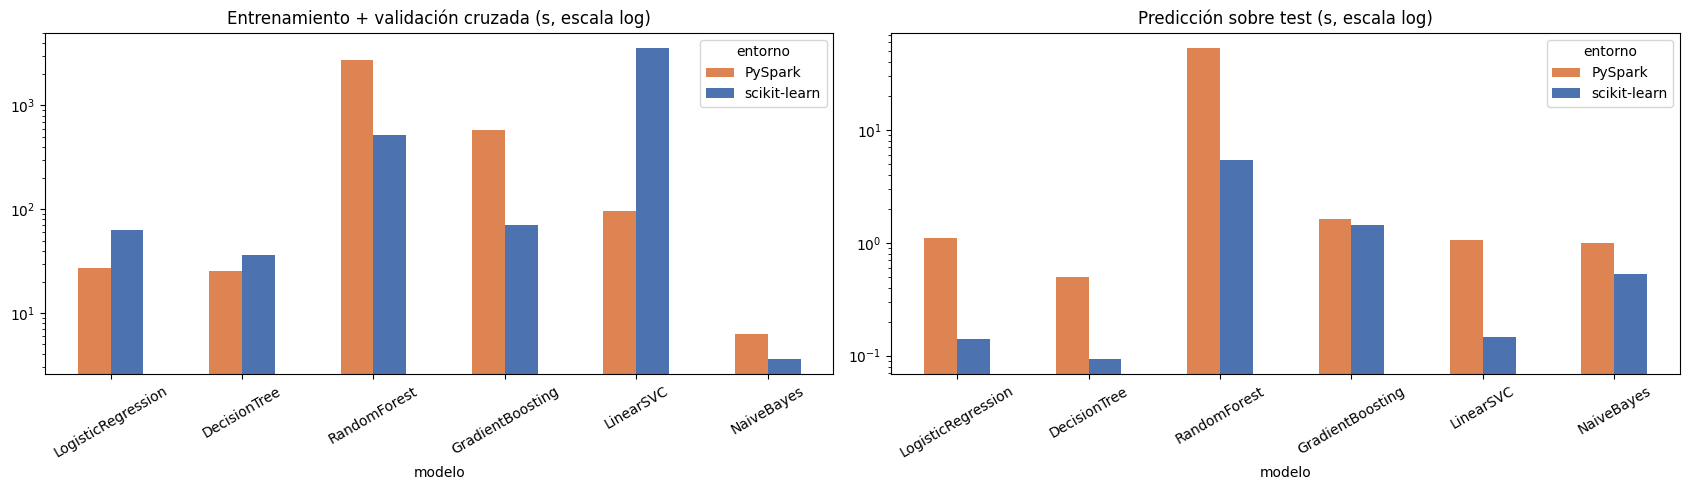

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))  # Comparación de tiempos
tiempos["entrenamiento + CV"].unstack().reindex(cfg.NOMBRES_MODELOS).plot.bar(ax=axes[0], color=["#DD8452", "#4C72B0"], logy=True)  # Entrenamiento por modelo
axes[0].set_title("Entrenamiento + validación cruzada (s, escala log)"); axes[0].tick_params(axis="x", rotation=30)  # Título y etiquetas
tiempos["predicción"].unstack().reindex(cfg.NOMBRES_MODELOS).plot.bar(ax=axes[1], color=["#DD8452", "#4C72B0"], logy=True)  # Predicción por modelo
axes[1].set_title("Predicción sobre test (s, escala log)"); axes[1].tick_params(axis="x", rotation=30)  # Título y etiquetas
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "07_tiempos")  # Exporta la figura
plt.show()  # Muestra la figura

## Curvas ROC (una figura por entorno)

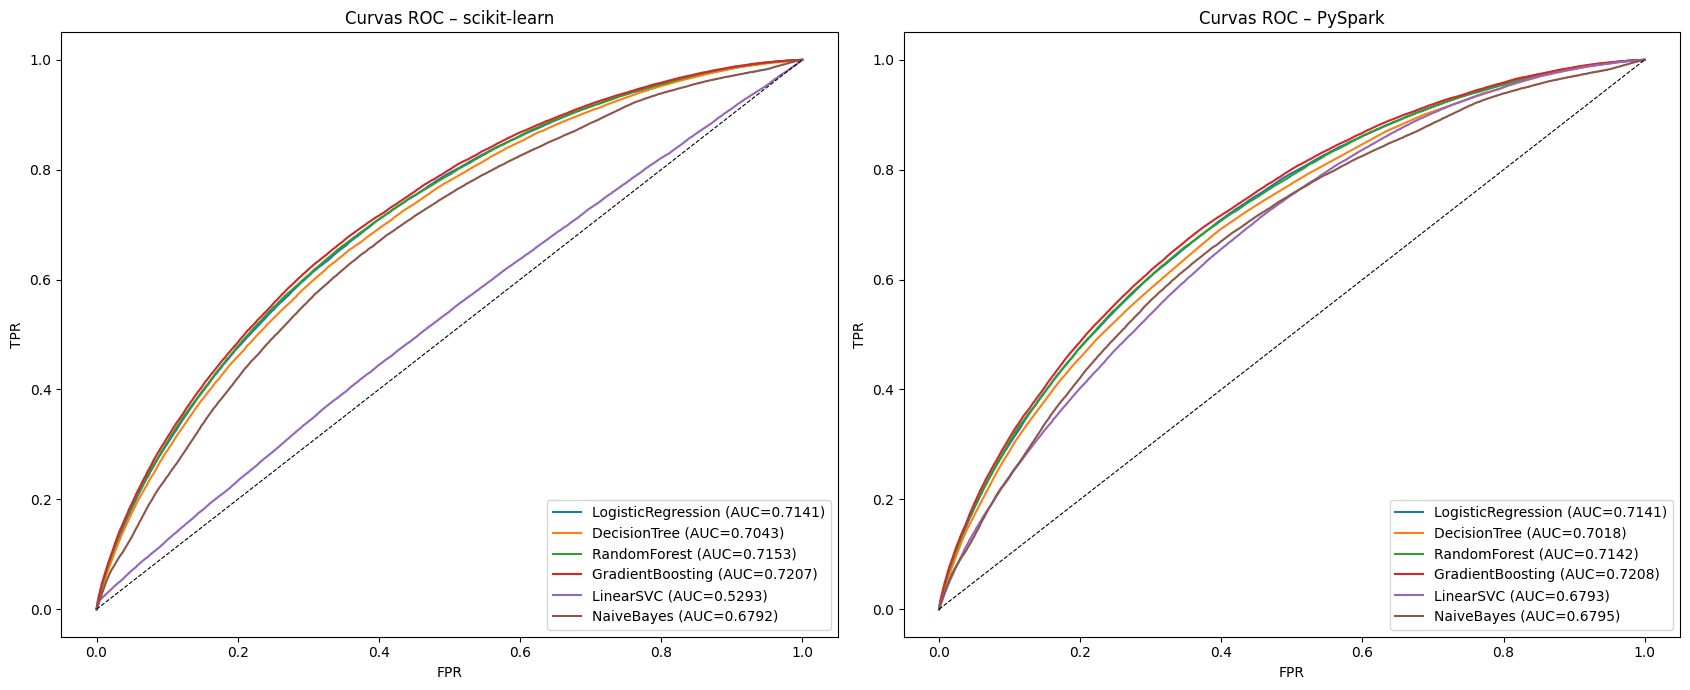

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))  # Una figura por entorno
for ax, (entorno, carpeta) in zip(axes, [("scikit-learn", cfg.DIR_SCORES_SK), ("PySpark", cfg.DIR_SCORES_SP)]):  # Recorre los entornos
    for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        s = pd.read_parquet(carpeta / f"{modelo}.parquet")  # Puntuaciones de test
        fpr, tpr, _ = roc_curve(s[cfg.COL_TARGET], s["score"])  # Curva ROC
        ax.plot(fpr, tpr, label=f"{modelo} (AUC={met[entorno][modelo]['metricas']['roc_auc']:.4f})")  # Dibuja la curva
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # Diagonal de referencia
    ax.set_title(f"Curvas ROC – {entorno}"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(loc="lower right")  # Rótulos
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "07_roc_ambos")  # Exporta la figura
plt.show()  # Muestra la figura

## Prueba de DeLong: AUC con IC 95 %, comparaciones entre entornos y mapas de calor

In [7]:
auc_ic = pd.read_csv(cfg.DIR_SALIDAS / "auc_ic95.csv", header=[0, 1], index_col=0)  # AUC e IC por modelo y entorno
auc_ic  # Muestra la tabla

AUC         IC95_inf         IC95_sup        
entorno            pyspark sklearn  pyspark sklearn  pyspark sklearn
modelo                                                              
LogisticRegression  0.7141  0.7141   0.7118  0.7117   0.7165  0.7165
DecisionTree        0.7018  0.7043   0.6994  0.7019   0.7042  0.7067
RandomForest        0.7142  0.7153   0.7119  0.7129   0.7166  0.7176
GradientBoosting    0.7208  0.7207   0.7184  0.7184   0.7231  0.7231
LinearSVC           0.6793  0.5293   0.6769  0.5266   0.6817  0.5321
NaiveBayes          0.6795  0.6792   0.6770  0.6767   0.6819  0.6816

In [8]:
fam1 = pd.read_csv(cfg.DIR_SALIDAS / "delong_entre_entornos.csv", index_col=0)  # DeLong sklearn vs PySpark
fam1[["auc_1", "auc_2", "delta_auc", "delta_ic_inf", "delta_ic_sup", "z", "p_valor", "p_holm", "significativa", "relevante"]].rename(columns={"auc_1": "AUC sklearn", "auc_2": "AUC PySpark"})  # Tabla resumida

,AUC sklearn,AUC PySpark,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
comparacion,,,,,,,,,,
LogisticRegression: sklearn vs PySpark,0.7141,0.7141,-0.0000,-0.0000,0.0000,-0.9576,0.3383,0.6765,False,False
DecisionTree: sklearn vs PySpark,0.7043,0.7018,0.0025,0.0015,0.0034,5.0249,0.0000,0.0000,True,False
RandomForest: sklearn vs PySpark,0.7153,0.7142,0.0011,0.0007,0.0014,6.3575,0.0000,0.0000,True,False
GradientBoosting: sklearn vs PySpark,0.7207,0.7208,-0.0000,-0.0004,0.0003,-0.2267,0.8206,0.8206,False,False
LinearSVC: sklearn vs PySpark,0.5293,0.6793,-0.1500,-0.1534,-0.1465,-85.5268,0.0000,0.0000,True,True
NaiveBayes: sklearn vs PySpark,0.6792,0.6795,-0.0003,-0.0004,-0.0002,-10.7921,0.0000,0.0000,True,False


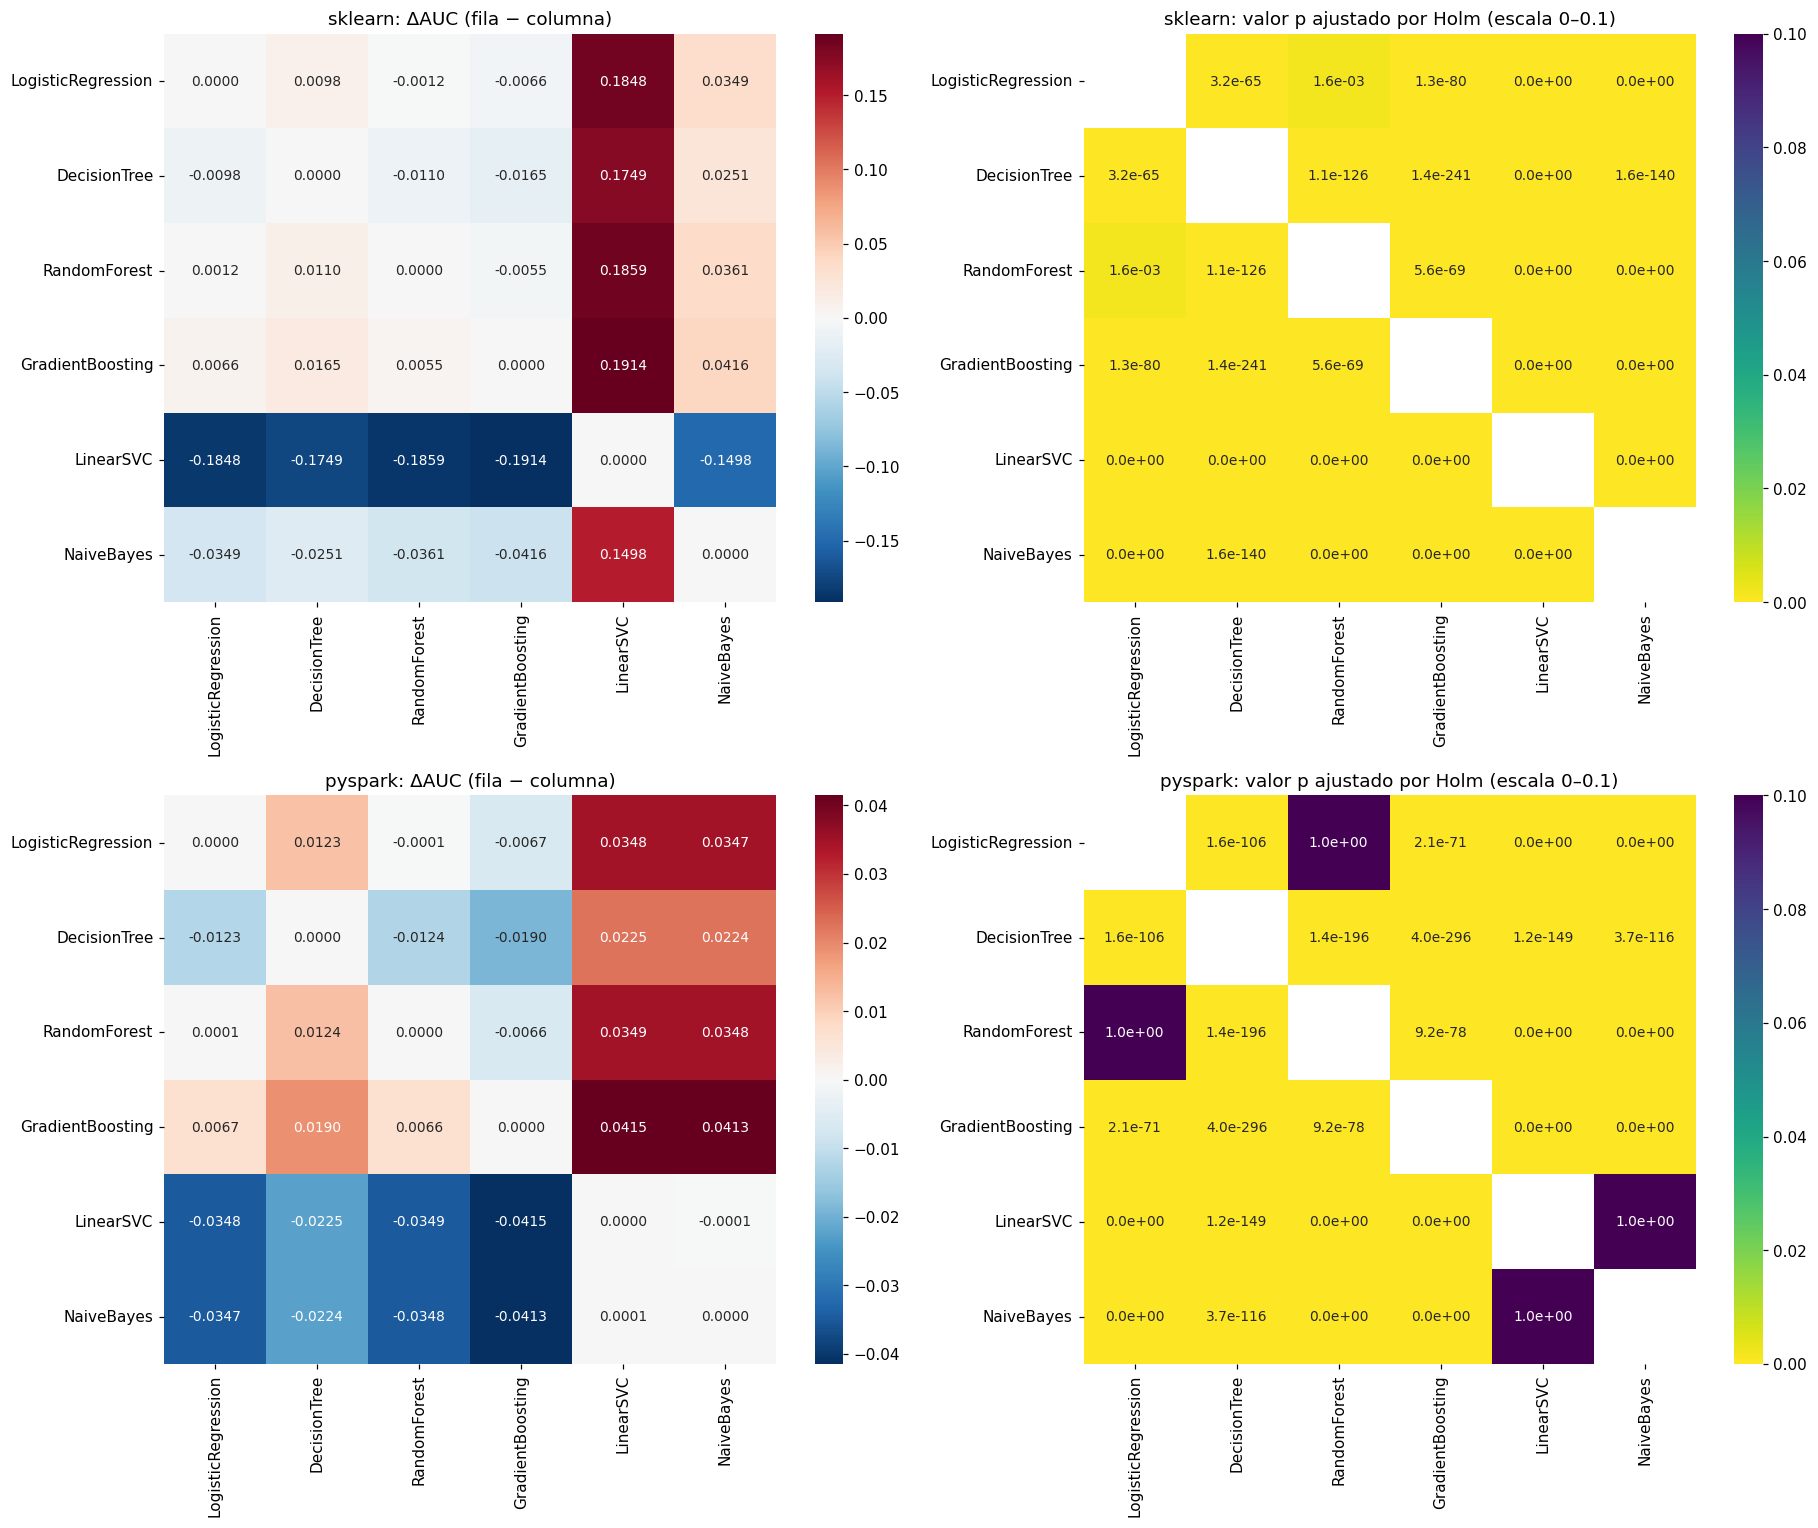

In [9]:
display(Image(filename=str(cfg.DIR_FIGURAS / "05_heatmaps_delong.png")))  # Mapas de calor generados en el notebook 05

## Resumen de las tres pruebas (DeLong, McNemar, bootstrap pareado)

In [10]:
comp = pd.read_csv(cfg.DIR_SALIDAS / "comparaciones_complementarias.csv", index_col=0)  # Resultados del notebook 05
def ic(a, b):  # Formatea un intervalo
    return f"[{a:+.4f}, {b:+.4f}]"  # Texto del intervalo
tabla = pd.DataFrame({  # Tabla de síntesis
    "ΔAUC": comp["delong_delta_auc"],  # Diferencia de AUC
    "DeLong IC95": [ic(a, b) for a, b in zip(comp["delong_ic_inf"], comp["delong_ic_sup"])],  # IC de DeLong
    "DeLong p_Holm": comp["delong_p_holm"],  # p ajustado DeLong
    "McNemar b / c": [f"{b:,} / {c:,}" for b, c in zip(comp["mcnemar_b"], comp["mcnemar_c"])],  # Discordantes
    "McNemar p_Holm": comp["mcnemar_p_holm"],  # p ajustado McNemar
    "Boot ΔAUC IC95": [ic(a, b) for a, b in zip(comp["boot_delta_auc_ic_inf"], comp["boot_delta_auc_ic_sup"])],  # IC bootstrap AUC
    "Boot ΔAUC-PR IC95": [ic(a, b) for a, b in zip(comp["boot_delta_auc_pr_ic_inf"], comp["boot_delta_auc_pr_ic_sup"])],  # IC bootstrap AUC-PR
    "Boot ΔF1 IC95": [ic(a, b) for a, b in zip(comp["boot_delta_f1_ic_inf"], comp["boot_delta_f1_ic_sup"])],  # IC bootstrap F1
})
tabla  # Muestra la tabla

,ΔAUC,DeLong IC95,DeLong p_Holm,McNemar b / c,McNemar p_Holm,Boot ΔAUC IC95,Boot ΔAUC-PR IC95,Boot ΔF1 IC95
comparacion,,,,,,,,
LogisticRegression: sklearn vs PySpark,-0.0000,"[-0.0000, +0.0000]",0.6765,"1,135 / 319",0.0000,"[-0.0000, +0.0000]","[-0.0002, -0.0001]","[-0.0002, +0.0006]"
DecisionTree: sklearn vs PySpark,0.0025,"[+0.0015, +0.0034]",0.0000,"18,549 / 11,787",0.0000,"[+0.0015, +0.0034]","[+0.0025, +0.0063]","[+0.0014, +0.0050]"
RandomForest: sklearn vs PySpark,0.0011,"[+0.0007, +0.0014]",0.0000,"5,413 / 3,812",0.0000,"[+0.0007, +0.0014]","[+0.0001, +0.0015]","[-0.0007, +0.0016]"
GradientBoosting: sklearn vs PySpark,-0.0000,"[-0.0004, +0.0003]",0.8206,"5,555 / 6,250",0.0000,"[-0.0004, +0.0003]","[-0.0007, +0.0012]","[-0.0006, +0.0016]"
LinearSVC: sklearn vs PySpark,-0.1500,"[-0.1534, -0.1465]",0.0000,"16,471 / 119,601",0.0000,"[-0.1534, -0.1466]","[-0.1063, -0.0999]","[-0.0724, -0.0682]"
NaiveBayes: sklearn vs PySpark,-0.0003,"[-0.0004, -0.0002]",0.0000,742 / 797,0.1687,"[-0.0004, -0.0002]","[-0.0009, -0.0006]","[-0.0008, -0.0001]"
sklearn: GradientBoosting vs RandomForest,0.0055,"[+0.0048, +0.0061]",0.0000,"7,457 / 18,142",0.0000,"[+0.0049, +0.0061]","[+0.0068, +0.0094]","[+0.0068, +0.0103]"
pyspark: GradientBoosting vs RandomForest,0.0066,"[+0.0059, +0.0072]",0.0000,"8,838 / 17,227",0.0000,"[+0.0059, +0.0073]","[+0.0073, +0.0101]","[+0.0069, +0.0104]"


## Experimento auxiliar: ¿a partir de qué volumen PySpark supera a scikit-learn?

Para responder a esta pregunta de la reflexión se mide el tiempo de **un solo ajuste**
(sin validación cruzada) de dos modelos representativos con hiperparámetros fijos, sobre
fracciones crecientes del conjunto de entrenamiento: 1 %, 5 %, 10 %, 25 %, 50 % y 100 %.
**Este experimento es solo de tiempos**: ningún modelo reportado en el proyecto se entrenó
con datos reducidos. Las fracciones se toman con la misma lista de índices en ambos entornos.

In [11]:
from sklearn.linear_model import LogisticRegression as SkLR  # Regresión logística de sklearn
from sklearn.ensemble import RandomForestClassifier as SkRF  # Bosque aleatorio de sklearn
from pyspark.sql import functions as F  # Funciones de Spark
from pyspark.ml.classification import LogisticRegression as SpLR, RandomForestClassifier as SpRF, GBTClassifier  # Modelos de Spark
from src import preparacion_spark as prep_sp  # Preparación con Spark

X_train = np.load(cfg.DIR_SKLEARN_PREP / "X_train.npy")  # Matriz de entrenamiento de sklearn
y_train = np.load(cfg.DIR_SKLEARN_PREP / "y_train.npy")  # Etiquetas de entrenamiento
id_train = np.load(cfg.DIR_SKLEARN_PREP / "id_train.npy")  # Identificadores de entrenamiento
orden = np.random.default_rng(cfg.SEMILLA).permutation(len(id_train))  # Orden aleatorio fijo de las filas de train
rango = pd.DataFrame({cfg.COL_ID: id_train[orden], "rango": np.arange(len(orden)) / len(orden)})  # Posición relativa de cada id (0–1)
rango.to_parquet(cfg.DIR_DATOS / "rango_escalabilidad.parquet", index=False)  # Se guarda para que Spark lo lea sin pasar por el driver
fracciones = [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]  # Fracciones de train a evaluar

spark = prep_sp.crear_sesion()  # Sesión de Spark con la configuración del enunciado
df = prep_sp.transformar_numericas(prep_sp.construir_variables(prep_sp.leer_csv(spark)))  # Lee y construye variables
df = df.join(F.broadcast(spark.read.parquet(str(cfg.RUTA_PARTICION))), on=cfg.COL_ID).filter(F.col("split") == "train")  # Solo train
frec = prep_sp.categorias_frecuentes(df, cfg.CATEGORICAS_MODELO)  # Categorías frecuentes de train
df = prep_sp.agrupar_categorias(df, frec)  # Agrupa categorías raras
feat = prep_sp.pipeline_preprocesamiento().fit(df).transform(df).select(cfg.COL_ID, "features", cfg.COL_TARGET)  # Vector de características
feat = feat.join(F.broadcast(spark.read.parquet(str(cfg.DIR_DATOS / "rango_escalabilidad.parquet"))), on=cfg.COL_ID).repartition(cfg.PARTICIONES_SPARK).persist()  # Agrega la posición relativa (tabla pequeña de id → rango)
feat.count()  # Materializa la caché

filas = []  # Resultados del experimento
for frac in fracciones:  # Recorre las fracciones
    idx = orden[: int(frac * len(orden))]  # Índices de sklearn de la fracción
    sub = feat.filter(F.col("rango") < frac).persist()  # Mismas filas en Spark
    n_sub = sub.count()  # Materializa la fracción
    for nombre, sk_mod, sp_mod in [  # Dos modelos representativos
        ("LogisticRegression", SkLR(C=cfg.c_desde_regparam(1e-5, len(idx)), max_iter=1000), SpLR(regParam=1e-5, elasticNetParam=0.0, maxIter=100, featuresCol="features", labelCol=cfg.COL_TARGET)),  # Lineal
        ("RandomForest", SkRF(n_estimators=50, max_depth=10, n_jobs=-1, random_state=cfg.SEMILLA), SpRF(numTrees=50, maxDepth=10, seed=cfg.SEMILLA, featuresCol="features", labelCol=cfg.COL_TARGET)),  # Ensamble
    ]:
        t0 = time.time(); sk_mod.fit(X_train[idx], y_train[idx]); t_sk = time.time() - t0  # Ajuste en sklearn
        t0 = time.time(); sp_mod.fit(sub); t_sp = time.time() - t0  # Ajuste en Spark
        filas.append({"fraccion": frac, "n": n_sub, "modelo": nombre, "scikit-learn": t_sk, "PySpark": t_sp})  # Guarda los tiempos
        print(f"{frac:>5.0%} n={n_sub:>9,} {nombre:<18} sklearn={t_sk:7.1f}s  PySpark={t_sp:7.1f}s", flush=True)  # Progreso
    sub.unpersist()  # Libera la fracción
feat.unpersist(); spark.stop()  # Libera recursos
escala = pd.DataFrame(filas)  # Tabla de resultados
escala.to_csv(cfg.DIR_SALIDAS / "escalabilidad.csv", index=False)  # Guarda los resultados

   1% n=   10,763 LogisticRegression sklearn=    0.2s  PySpark=    3.7s


   1% n=   10,763 RandomForest       sklearn=    0.2s  PySpark=    3.2s


   5% n=   53,813 LogisticRegression sklearn=    0.6s  PySpark=    1.7s


   5% n=   53,813 RandomForest       sklearn=    0.5s  PySpark=    5.1s


  10% n=  107,625 LogisticRegression sklearn=    1.2s  PySpark=    1.4s


...

  25% n=  269,062 RandomForest       sklearn=    3.4s  PySpark=   17.2s


  50% n=  538,124 LogisticRegression sklearn=    6.4s  PySpark=    1.8s


  50% n=  538,124 RandomForest       sklearn=    7.3s  PySpark=   29.7s


 100% n=1,076,248 LogisticRegression sklearn=   20.3s  PySpark=    2.4s


 100% n=1,076,248 RandomForest       sklearn=   16.0s  PySpark=   47.5s


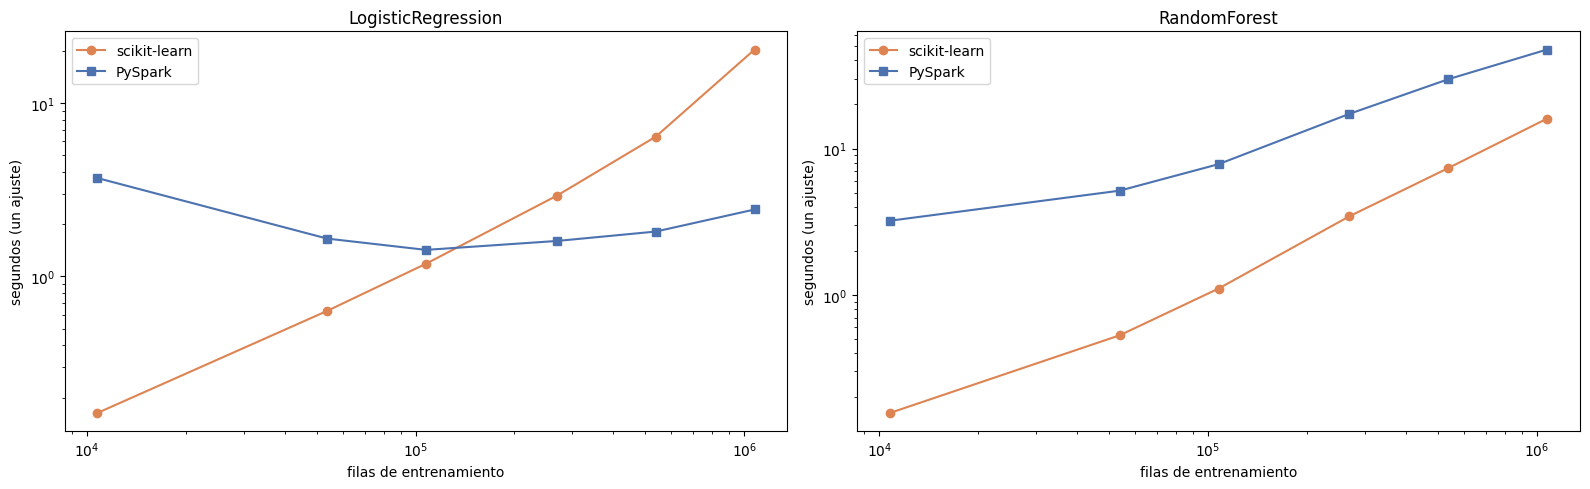

,fraccion,n,modelo,scikit-learn,PySpark,PySpark / sklearn
0,0.0100,10763,LogisticRegression,0.1631,3.6909,22.6270
1,0.0100,10763,RandomForest,0.1559,3.2105,20.5883
2,0.0500,53813,LogisticRegression,0.6323,1.6523,2.6132
3,0.0500,53813,RandomForest,0.5289,5.1499,9.7375
4,0.1000,107625,LogisticRegression,1.1835,1.4221,1.2017
5,0.1000,107625,RandomForest,1.1035,7.8154,7.0825
6,0.2500,269062,LogisticRegression,2.9192,1.6008,0.5484
7,0.2500,269062,RandomForest,3.4403,17.2419,5.0118
8,0.5000,538124,LogisticRegression,6.3930,1.8137,0.2837
9,0.5000,538124,RandomForest,7.3457,29.7370,4.0482


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))  # Tiempo vs tamaño para cada modelo
for ax, (nombre, g) in zip(axes, escala.groupby("modelo")):  # Un gráfico por modelo
    ax.plot(g["n"], g["scikit-learn"], "o-", color="#DD8452", label="scikit-learn")  # Curva de sklearn
    ax.plot(g["n"], g["PySpark"], "s-", color="#4C72B0", label="PySpark")  # Curva de PySpark
    ax.set_xscale("log"); ax.set_yscale("log")  # Escalas logarítmicas
    ax.set_xlabel("filas de entrenamiento"); ax.set_ylabel("segundos (un ajuste)"); ax.set_title(nombre); ax.legend()  # Rótulos
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "07_escalabilidad")  # Exporta la figura
plt.show()  # Muestra la figura
escala.assign(**{"PySpark / sklearn": escala["PySpark"] / escala["scikit-learn"]})  # Tabla con el cociente de tiempos

## Experimento auxiliar: efecto de las condiciones obligatorias de Spark

Se mide, sobre **todo** el conjunto de entrenamiento, el tiempo de ajustar un
`GBTClassifier` (10 iteraciones, profundidad 5) y un `RandomForestClassifier` (20 árboles,
profundidad 10) bajo tres condiciones:

1. **6 particiones + caché** (configuración usada en el notebook 04, `local[6]`);
2. **400 particiones + caché** (valores literales del enunciado para `shuffle.partitions`,
   `default.parallelism` y el reparto de los datos);
3. **6 particiones sin caché**: cada pasada del algoritmo vuelve a leer y descomprimir el
   CSV y a recalcular el preprocesamiento (solo con el bosque, por su costo).

In [13]:
def features_train(spark, particiones):  # Construye el DataFrame de train con el vector de características
    d = prep_sp.transformar_numericas(prep_sp.construir_variables(prep_sp.leer_csv(spark)))  # Lectura y variables
    d = d.join(F.broadcast(spark.read.parquet(str(cfg.RUTA_PARTICION))), on=cfg.COL_ID).filter(F.col("split") == "train")  # Solo train
    d = prep_sp.agrupar_categorias(d, prep_sp.categorias_frecuentes(d, cfg.CATEGORICAS_MODELO)).repartition(particiones)  # Categorías y reparto
    return prep_sp.pipeline_preprocesamiento().fit(d).transform(d).select("features", cfg.COL_TARGET)  # Vector de características (perezoso)

modelos_exp = {  # Modelos del experimento
    "GBT (10 it., prof. 5)": lambda: GBTClassifier(maxIter=10, maxDepth=5, seed=cfg.SEMILLA, featuresCol="features", labelCol=cfg.COL_TARGET),  # Boosting
    "RF (20 árboles, prof. 10)": lambda: SpRF(numTrees=20, maxDepth=10, seed=cfg.SEMILLA, featuresCol="features", labelCol=cfg.COL_TARGET),  # Bosque
}
filas = []  # Resultados del experimento
for particiones in [cfg.PARTICIONES_SPARK, 400]:  # Recorre las dos configuraciones de particiones
    spark = prep_sp.crear_sesion(particiones=particiones)  # Sesión nueva con esa configuración
    feat = features_train(spark, particiones).persist()  # Datos de train cacheados
    feat.count()  # Materializa la caché
    for nombre, crear in modelos_exp.items():  # Recorre los modelos
        t0 = time.time(); crear().fit(feat); t = time.time() - t0  # Ajuste cronometrado
        filas.append({"condición": f"{particiones} particiones + caché", "modelo": nombre, "segundos": t})  # Guarda el tiempo
        print(filas[-1], flush=True)  # Progreso
    feat.unpersist()  # Libera la caché
    if particiones == cfg.PARTICIONES_SPARK:  # Condición sin caché (solo con 6 particiones)
        sin_cache = features_train(spark, particiones)  # Mismo DataFrame, sin persist()
        t0 = time.time(); modelos_exp["RF (20 árboles, prof. 10)"]().fit(sin_cache); t = time.time() - t0  # Ajuste sin caché
        filas.append({"condición": f"{particiones} particiones sin caché", "modelo": "RF (20 árboles, prof. 10)", "segundos": t})  # Guarda el tiempo
        print(filas[-1], flush=True)  # Progreso
    spark.stop()  # Detiene la sesión antes de cambiar la configuración
condiciones = pd.DataFrame(filas).pivot(index="modelo", columns="condición", values="segundos")  # Tabla modelo × condición
condiciones.to_csv(cfg.DIR_SALIDAS / "efecto_condiciones_spark.csv")  # Guarda la tabla
condiciones  # Muestra la tabla

{'condición': '6 particiones + caché', 'modelo': 'GBT (10 it., prof. 5)', 'segundos': 8.716172218322754}


{'condición': '6 particiones + caché', 'modelo': 'RF (20 árboles, prof. 10)', 'segundos': 15.161192655563354}


{'condición': '6 particiones sin caché', 'modelo': 'RF (20 árboles, prof. 10)', 'segundos': 92.48577618598938}


{'condición': '400 particiones + caché', 'modelo': 'GBT (10 it., prof. 5)', 'segundos': 75.64392304420471}


{'condición': '400 particiones + caché', 'modelo': 'RF (20 árboles, prof. 10)', 'segundos': 141.4095959663391}


condición,400 particiones + caché,6 particiones + caché,6 particiones sin caché
modelo,,,
"GBT (10 it., prof. 5)",75.6439,8.7162,NaN
"RF (20 árboles, prof. 10)",141.4096,15.1612,92.4858


## Reflexión crítica

### ¿Qué entorno fue más rápido y por qué?

Sumando el entrenamiento con validación cruzada de los seis modelos, **PySpark tardó ≈ 3.478 s
y scikit-learn ≈ 4.243 s**. Pero el total engaña: sin LinearSVC (cuyo solucionador de
scikit-learn es patológicamente lento aquí), scikit-learn tarda ≈ 693 s y PySpark ≈ 3.380 s.
El resultado depende del algoritmo:

* **PySpark gana en los modelos lineales y el árbol simple** (regresión logística 27 s vs 63 s;
  árbol 26 s vs 37 s; LinearSVC 97 s vs 3.549 s). Son algoritmos de pocas pasadas sobre datos
  cacheados; cada pasada se reparte bien entre particiones y Spark usa optimizadores
  (L-BFGS/OWL-QN) que convergen en pocas iteraciones. El LinearSVC de scikit-learn usa un
  descenso por coordenadas dual de un solo hilo que, con C ≈ 0,93, necesita miles de iteraciones.
* **scikit-learn gana en los ensambles** (bosque 519 s vs 2.741 s; boosting 71 s vs 581 s).
  Su código compilado entrena árboles completos en memoria y reparte los árboles del bosque
  entre 12 hilos. Spark construye los árboles **nivel por nivel**: cada nivel es un trabajo que
  serializa los árboles hacia las tareas y combina estadísticas entre particiones, y el boosting
  encadena 100 árboles secuenciales, cada uno con varios trabajos. Además, PySpark usó 6 hilos
  (el límite de memoria lo impuso) frente a 12.
* **Tamaño del dataset:** 1,3 M filas × 25 variables caben holgadamente en la RAM de un
  portátil (la matriz de scikit-learn ocupa ≈ 330 MB), así que la principal ventaja de Spark
  —procesar datos que no caben en una máquina— no se aprovecha, y su sobrecarga fija sí se paga.
* **Caché:** imprescindible. Sin ella, un bosque de 20 árboles tardó 92,5 s frente a 15,2 s
  (× 6,1), porque cada pasada volvía a descomprimir el CSV y a recalcular el preprocesamiento.
* **CrossValidator:** multiplica el costo por 3 pliegues × combinaciones, igual que
  `GridSearchCV`; pero `GridSearchCV` reparte los ajustes en 12 procesos, mientras que en Spark
  el paralelismo entre combinaciones tuvo que limitarse (1 en los ensambles) por memoria.
* **Configuración de Spark:** con las 400 particiones del enunciado, 10 iteraciones de GBT
  tardaron 75,6 s y 20 árboles de bosque 141,4 s, frente a 8,7 s y 15,2 s con 6 particiones
  (× 8,7 y × 9,3): en una sola máquina la sobrecarga de tareas diminutas domina.

### ¿Cuál fue más preciso?

**Empate técnico.** El mejor modelo de ambos entornos es *gradient boosting* con AUC 0,7207
(scikit-learn) y 0,7208 (PySpark), sin diferencia significativa (p Holm = 0,82). scikit-learn
es ligeramente mejor en árbol y bosque (+0,0025 y +0,0011, significativas pero irrelevantes) y
PySpark es mucho mejor en LinearSVC (+0,150). En F1 con umbral de train, los mejores modelos
empatan (0,4377 vs 0,4373).

### ¿Qué diferencias de AUC son significativas tras Holm y cuáles son relevantes?

* **Entre entornos:** significativas en árbol, bosque, Naive Bayes y LinearSVC; **relevante solo
  LinearSVC** (|ΔAUC| = 0,150). Regresión logística y boosting no difieren.
* **Entre modelos:** 15/15 pares significativos en scikit-learn y 13/15 en PySpark. Son
  relevantes (≥ 0,005) las ventajas del boosting sobre todos los demás (≥ 0,0055), las de
  logística y bosque sobre el árbol (≈ 0,010–0,012) y las de todos ellos sobre Naive Bayes
  (≈ 0,022–0,042). No es relevante la diferencia entre logística y bosque (≤ 0,0012): un modelo
  lineal regularizado rinde casi como un bosque de 100 árboles con estas variables.

### ¿Qué diferencias de implementación explican las discrepancias?

* **Discretización en los árboles:** `maxBins = 32` en Spark frente a cortes exactos
  (árbol/bosque) o 255 intervalos (`HistGradientBoosting`) en scikit-learn → pequeñas pérdidas
  de AUC en árbol y bosque.
* **Poda de hojas en Spark:** fusiona hojas hermanas con la misma clase predicha; con clases
  desbalanceadas destruye la ordenación de los árboles poco profundos (profundidad 5: 0,654 vs
  0,692 en CV). Además, en los árboles `rawPrediction` guarda conteos, no proporciones, y hubo
  que evaluar sobre `probability` para obtener AUC correctos.
* **LinearSVC:** mismos objetivos (*hinge* + L2), pero solucionadores distintos (dual por
  coordenadas vs OWL-QN) y, sobre todo, `liblinear` **penaliza el intercepto**; con 20 % de
  positivos eso degrada el modelo (0,53 vs 0,68).
* **Regularización:** C = 1/(regParam·n) es solo aproximada (suma vs promedio de pérdidas),
  pero con n ≈ 1 M la penalización es tan pequeña que los tres valores dan el mismo AUC.
* **Boosting:** `HistGradientBoosting` usa pasos de Newton (gradiente + hessiano) y
  `GBTClassifier` ajusta árboles de regresión a los pseudo-residuos; aun así el AUC es idéntico.
* **Naive Bayes:** el suavizado de varianzas difiere levemente (ΔAUC = 0,0003).
* **Codificación:** `StringIndexer(handleInvalid="keep")` añade una columna por variable para
  categorías no vistas (84 frente a 77 columnas), sin efecto en test.

### Limitaciones de DeLong y complemento de McNemar y bootstrap. ¿Coinciden?

DeLong solo mide la incertidumbre del **muestreo del test** (no la del entrenamiento), supone
independencia y resume todos los umbrales. El **bootstrap** coincidió con DeLong en las 8
comparaciones de AUC (intervalos casi idénticos) y además permitió evaluar **AUC-PR y F1**,
donde algunas conclusiones cambian (en el bosque, el AUC difiere pero F1 y AUC-PR no). **McNemar**
discrepó con frecuencia porque compara **decisiones** con umbrales distintos: detectó
diferencias donde el AUC es igual (logística, boosting), no las detectó donde el AUC difiere
levemente (Naive Bayes) y, entre boosting y bosque, favoreció al bosque por cometer menos errores
totales aunque detecta menos defaults. Las tres pruebas coinciden en lo importante (boosting
es el mejor; LinearSVC de scikit-learn es claramente inferior) y difieren en los matices, que
dependen de qué propiedad del desempeño se mide.

### ¿A partir de qué volumen PySpark supera a scikit-learn?

Depende del algoritmo (experimento auxiliar de escalabilidad):

* **Regresión logística:** con 1 % de train (≈ 11 mil filas) PySpark es 23 veces más lento
  (3,7 s vs 0,16 s) por la sobrecarga fija de trabajos; casi se iguala hacia el **10 % (≈ 110 mil
  filas**: 1,4 s vs 1,2 s) y a partir de **≈ 250 mil filas** PySpark es más rápido (1,6 s vs
  2,9 s). Con todo train es 8 veces más rápido (2,4 s vs 20,3 s), porque su tiempo casi no
  crece con n.
* **Bosque aleatorio:** PySpark **nunca** supera a scikit-learn en este equipo, aunque la
  brecha se reduce (de × 21 con 11 mil filas a × 3,0 con 1,07 M). Extrapolando la tendencia,
  haría falta del orden de decenas de millones de filas, o un clúster con más memoria y
  núcleos, para que la versión distribuida compense.

### ¿Qué aporta LIME y cuáles son sus limitaciones en entornos distribuidos?

LIME explicó por qué ambos *boosting* fallaron en dos préstamos concretos (plazo corto y tasa
baja en el falso negativo; tasa alta e ingreso bajo en el falso positivo) y mostró que los dos
modelos se apoyan en las mismas variables con los mismos signos. En Spark, LIME exige llevar
datos de entrenamiento y perturbaciones al driver, mantener el modelo vivo en la sesión y
pagar varios trabajos de Spark por cada lote de perturbaciones (≈ 0,6 s por llamada, y ≈ 250 s
antes de optimizar la transferencia). Es viable para unas pocas instancias, no para
explicaciones masivas.

### ¿Qué efecto tuvo cada condición obligatoria en el rendimiento?

| Condición | Efecto observado |
|---|---|
| Dataset completo, sin muestreo | Aumentó los tiempos de scikit-learn (bosque 519 s; LinearSVC 59 min) y amortizó la sobrecarga fija de Spark; en regresión logística es lo que hace ganar a Spark |
| Partición común guardada en Parquet (sin `randomSplit`) | Garantiza pruebas pareadas sobre las mismas 269.062 filas (verificado por `id`); costo despreciable |
| Transformadores ajustados solo con train | Sin costo apreciable; evita fuga de información (la media de test tras escalar no es exactamente 0) |
| Prohibición de `.toPandas()` / `.collect()` | Todo el preprocesamiento se hizo en Spark; la transferencia final de `id`, `default` y `score` costó ≈ 1 s por modelo (11 s en el bosque) |
| Caché tras el `VectorAssembler` | Imprescindible: sin caché el bosque de prueba fue 6,1 veces más lento |
| `ParamGridBuilder` + `CrossValidator` (sin bucles) | Mismo número de ajustes que `GridSearchCV`; el paralelismo entre combinaciones se limitó en los ensambles por memoria |
| 400 particiones de *shuffle* y paralelismo | ≈ 9 veces más lento en una sola máquina (GBT × 8,7; bosque × 9,3); se sustituyó por 6 (justificado) |
| Memoria 8g | Insuficiente para el bosque de 100 árboles de profundidad 15 con 12 tareas simultáneas (tres fallos por falta de memoria); se usaron 9g y `local[6]` |

**Conclusión.** Con 1,3 millones de filas en un solo equipo, ambos entornos alcanzan la misma
capacidad predictiva (AUC ≈ 0,72 con *gradient boosting*), pero scikit-learn es más rápido y
sencillo para los ensambles, mientras que PySpark ya aventaja a scikit-learn en los modelos
lineales a partir de unas 250 mil filas. La hipótesis del enunciado ("PySpark superará en
velocidad a scikit-learn") se cumple solo en parte: para la regresión logística, el árbol y
LinearSVC, no para los ensambles.